<p align="center">
  <img src="assets/hero_proje.svg" width="100%" alt="Gün 56 — Ülkelerin soy ağacı: hiyerarşik kümeleme ve 27 algoritma">
</p>

<p align="center">
  <img src="https://img.shields.io/badge/G%C3%BCn-56-0E2A3B?style=for-the-badge" alt="Gün 56">
  <img src="https://img.shields.io/badge/Konu-Hiyerar%C5%9Fik_K%C3%BCmeleme_(Proje)-34D399?style=for-the-badge" alt="Konu">
  <img src="https://img.shields.io/badge/Seviye-Ba%C5%9Flang%C4%B1%C3%A7_%E2%86%92_Orta-FBBF24?style=for-the-badge" alt="Seviye">
  <img src="https://img.shields.io/badge/Algoritma-27_%2B_taban-F472B6?style=for-the-badge" alt="Algoritma">
</p>

> **Proje sorusu:** Bir uluslararası insani yardım kuruluşu, topladığı fonu **en çok ihtiyacı olan** ülkelere yönlendirmek istiyor.
> Elinde "bu ülke yardıma muhtaç" diyen bir etiket yok; yalnızca **167 ülkenin 9 sağlık ve ekonomi göstergesi** var.
> Ülkeleri **anlamlı ailelere** ayırıp **öncelikli bir kısa liste** çıkarabilir miyiz ve bu listeye **güvenebilir miyiz**?

<table><tr><td>

<img src="assets/etiket_hedef.svg" height="34" alt="Hedefler">

**Bu notebook'un sonunda şunları yapabiliyor olacaksınız:**

- 🌍 Gerçek bir **Kaggle** verisiyle **uçtan uca** bir hiyerarşik kümeleme projesi kurmak
- 🧼 Hatalı kayıtları (Myanmar'ın dış ticareti) ve uç değerleri **karar defteriyle** ele almak
- 🔒 Etiketsiz bir problemde bile **test setini kilitlemek** ve ön işlemeyi **sızıntısız boru hattına** koymak
- 🔢 Segment sayısını **dendrogram sıçraması + beş ölçüt** ve **önceden yazılmış bir kuralla** seçmek
- 🏁 **27 kümeleme algoritmasını** (12'si hiyerarşik ya da ağaç tabanlı) ve rastgele tabanı **aynı ölçüm uzayında** yarıştırmak
- 🪤 **Silüet tuzağını** (yüksek skor, işe yaramaz segment) yakalamak
- 🔁 **Bootstrap**, **tohum** ve **konsensüs matrisi** ile kararlılığı ölçmek
- 🧭 Segmentlere **iş diliyle** ad vermek, **dünya haritası** ve **vekil karar ağacı** ile açıklamak
- 🇺🇳 Segmentleri kümelemede **hiç kullanılmayan** BM **En Az Gelişmiş Ülkeler** listesiyle **bağımsız** doğrulamak
- 🆘 **İhtiyaç endeksi**, konsensüs oyu ve **bütçe senaryosu** ile karar desteği üretmek
- ⚖️ **Kıta** ilişkisi, **özellik duyarlılığı**, **sınırdaki ve sıra dışı** ülkelerle adalet ve hata analizi yapmak
- 💾 Modeli kaydedip **ayrı bir Python sürecinde** ham kayıtla çalıştırmak

</td></tr></table>

<p align="center">
  <img src="assets/yol_haritasi_proje.svg" width="100%" alt="Proje yol haritası: 16 bölüm">
</p>

### 🧭 Hızlı Erişim

| # | Bölüm | Ana soru |
|:-:|:--|:--|
| 1 | [Kurulum](#p1) | Hangi araçlar, hangi tohum? |
| 2 | [Senaryo, veri, ölçütler, kurallar](#p2) | İş sorusu ne, başarıyı etiketsiz nasıl ölçeriz? |
| 3 | [Veri kalitesi](#p3) | Eksik, kopya, imkânsız değer, uç değer var mı? |
| 4 | [Dürüst bölme](#p4) | Test seti neden kilitli, boru hattı neden tek parça? |
| 5 | [Keşif](#p5) | Ülkeler nasıl dağılıyor? |
| 6 | [Ön işleme deneyi](#p6) | Aynı Ward, altı ön işlemeyle ne kadar değişir? |
| 7 | [Kaç segment?](#p7) | Ağacı nereden keseceğiz? |
| 8 | [Büyük yarış](#p8) | 27 algoritmadan hangisi? |
| 9 | [Kararlılık](#p9) | Segmentler tesadüf mü? |
| 10 | [Ayar ve final](#p10) | Düğmeler ne kadar fark ettirir? |
| 11 | [Segment kimliği](#p11) | Segmentler kim, nasıl açıklanır? |
| 12 | [Test seti](#p12) | Görülmemiş ülkelerde de geçerli mi? |
| 13 | [Yardım kararı](#p13) | BM listesiyle uyuşuyor mu, kısa liste ne? |
| 14 | [Adalet ve hata](#p14) | Kıta vekili mi, hangi ülkelerde yanılabiliriz? |
| 15 | [Model kaydı](#p15) | Model başka yerde nasıl çalışır? |
| 16 | [Proje özeti](#p16) | Sayılarla proje ve kaynakça |

<p align="center">
  <img src="assets/diyagram_proje_akisi.svg" width="100%" alt="Uçtan uca proje akışı">
</p>

<a id="p1"></a>

<p align="center">
  <img src="assets/proje_01.svg" width="100%" alt="Bölüm 1: Kurulum">
</p>

Kütüphaneleri, tohumu, renkleri ve yardımcı işlevleri tek hücrede topluyoruz. Tüm rastgelelik **`RANDOM_STATE = 42`** ile sabitlenir. Elle yazılmış kümeleyiciler (**DIANA**, SciPy bağlantıları, **K-Medoids**, **konsensüs hiyerarşik**, rastgele taban) ve ağaca "yeni gelen ülkeyi atama" yeteneği kazandıran **`AgacAtayici`** `ulke_yardimci.py` içindedir; böylece kaydedilen model başka bir Python sürecinde de yüklenebilir.

In [1]:
# ── Kütüphaneler ─────────────────────────────────────────────
import os, time, json, warnings, subprocess, sys, itertools
from pathlib import Path
from functools import partial
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn, scipy, joblib
from scipy import stats
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet, set_link_color_palette
from scipy.spatial.distance import pdist
from IPython.display import Image, Markdown, display
from matplotlib.animation import FuncAnimation, PillowWriter
from matplotlib.colors import to_hex
from joblib import Parallel, delayed

from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, RobustScaler, FunctionTransformer, PowerTransformer
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors, KNeighborsClassifier, kneighbors_graph
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score, pairwise_distances)
from sklearn.cluster import (AgglomerativeClustering, FeatureAgglomeration, KMeans, MiniBatchKMeans, BisectingKMeans, Birch,
                             DBSCAN, OPTICS, HDBSCAN, MeanShift, estimate_bandwidth, SpectralClustering, AffinityPropagation)
from sklearn.mixture import GaussianMixture, BayesianGaussianMixture

from ulke_yardimci import (veri_oku, ticaret_kontrol, OZELLIKLER, BIRIM, SUTUN_TR, LOG_SUTUNLARI, ISARETLI_LOG_SUTUNLARI,
                           log1p_donustur, isaretli_log, dunya_haritasi, DIANA, ScipyBaglanti, KMedoids,
                           KonsensusHiyerarsik, RastgeleTaban, AgacAtayici)

warnings.filterwarnings("ignore")
RS = RANDOM_STATE = 42
N_JOBS = min(4, os.cpu_count() or 1)
np.random.seed(RS)

# ── Klasörler ────────────────────────────────────────────────
FIG, REP = Path("outputs/figures"), Path("outputs/reports")
for p in (FIG, REP): p.mkdir(parents=True, exist_ok=True)

# ── Renkler ve stil ──────────────────────────────────────────
RENK = dict(altin="#F59E0B", mavi="#0EA5E9", pembe="#EC4899", yesil="#10B981", mor="#8B5CF6",
            turuncu="#F97316", cyan="#06B6D4", gri="#94A3B8", koyu="#0F172A", kirmizi="#DC2626")
KUME_RENK = [RENK[r] for r in ["yesil", "altin", "mavi", "pembe", "mor", "turuncu", "cyan"]] + ["#84CC16", "#E11D48", "#6366F1"]
set_link_color_palette(KUME_RENK[:7])
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold", "axes.titlesize": 13, "axes.spines.top": False, "axes.spines.right": False})

def kaydet(fig, ad): fig.savefig(FIG / f"{ad}.png", dpi=130, bbox_inches="tight")
def rapor_kaydet(df, ad): df.to_csv(REP / f"{ad}.csv", encoding="utf-8-sig")

def gif_yap(kare, n_kare, ad, boyut=(12, 5), fps=2, dpi=75):
    """kare(i, fig) her karede yeniden çizilir; GIF kaydedilir ve notebook'ta oynatılır."""
    fig = plt.figure(figsize=boyut)
    def ciz(i):
        fig.clf(); kare(i, fig); fig.tight_layout()
    FuncAnimation(fig, ciz, frames=n_kare).save(FIG / f"{ad}.gif", writer=PillowWriter(fps=fps), dpi=dpi)
    plt.close(fig); display(Image(filename=str(FIG / f"{ad}.gif")))

def wilson(basari, n, z=1.96):
    """Bir oranın %95 Wilson güven aralığı (küçük örneklerde normal yaklaşımdan daha güvenilir)."""
    if n == 0: return (np.nan, np.nan)
    p = basari / n; m = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    o = (p + z * z / (2 * n)) / (1 + z * z / n); return (o - m, o + m)

def cramers_v(a, b):
    """İki kategorik değişken arasındaki ilişki gücü (0 = ilişkisiz, 1 = tam ilişki)."""
    t = pd.crosstab(a, b); ki = stats.chi2_contingency(t, correction=False)[0]
    return np.sqrt(ki / (t.to_numpy().sum() * (min(t.shape) - 1)))

def eta_kare(x, et):
    """Bir göstergedeki toplam yayılımın segmentler arası farktan gelen payı (söz hakkı)."""
    x = np.asarray(x, float); genel = x.mean()
    ara = sum((et == j).sum() * (x[et == j].mean() - genel) ** 2 for j in np.unique(et))
    return ara / ((x - genel) ** 2).sum()

print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__} | scikit-learn {sklearn.__version__} | scipy {scipy.__version__} | çekirdek {N_JOBS}")

Python 3.13.18 | pandas 3.0.5 | numpy 2.5.3 | scikit-learn 1.9.1 | scipy 1.18.1 | çekirdek 4


<a id="p2"></a>

<p align="center">
  <img src="assets/proje_02.svg" width="100%" alt="Bölüm 2: Senaryo ve kurallar">
</p>

### 🎯 2.1 · Senaryo

Uluslararası bir **insani yardım kuruluşu** (veri setinin hikâyesinde *HELP International*) yaklaşık **10 milyon dolarlık** bir fon topladı. Yönetim kurulu, fonun **"en çok ihtiyacı olan"** ülkelere gitmesini istiyor; ama bu kararı **sezgiyle** değil, **veriyle** ve **açıklanabilir** biçimde vermek istiyor.

**İş sorusu:** *Ülkeleri sağlık ve ekonomi göstergelerine göre **benzer ailelere** ayır; **öncelikli destek** ailesini bul ve içinden **gerekçeli bir kısa liste** çıkar.*

**Neden hiyerarşik kümeleme?** Kuruluşun saha ekipleri ülkeleri zaten **kademeli** düşünür ("Sahra Altı Afrika'nın en kırılgan ülkeleri", "orta gelirli ama sağlık sistemi zayıf ülkeler"…). Dendrogram bu kademeli yapıyı **tek bir resimde** gösterir ve yönetim kuruluna "hangi ülke hangisine benziyor?" sorusunun cevabını **görsel** olarak sunar.

### 🌍 2.2 · Veri

**Kaggle "Unsupervised Learning on Country Data"** (Kokkula, 2020): 167 ülke, 9 gösterge. Çalışma ortamında Kaggle'a doğrudan erişim kapalıydı; dosya **dört bağımsız GitHub aynasından** indirildi ve dördünün **içerik olarak birebir aynı** olduğu (167 × 10) doğrulandı. **Veri uydurma değildir.**

| Gösterge | Anlamı | Birim |
|:--|:--|:--|
| Çocuk ölümü | 5 yaş altı ölüm | 1000 canlı doğumda |
| İhracat / İthalat | Mal ve hizmet ticareti | kişi başı GSYH'nin %'si |
| Sağlık harcaması | Toplam sağlık harcaması | kişi başı GSYH'nin %'si |
| Gelir | Kişi başı net gelir | $ |
| Enflasyon | GSYH'nin yıllık büyüme hızıyla ölçülen enflasyon | % |
| Yaşam beklentisi | Yeni doğanın beklenen yaşam süresi | yıl |
| Doğurganlık | Kadın başına çocuk | çocuk |
| Kişi başı GSYH | Gayrisafi yurt içi hasıla / nüfus | $ |

Ayrıca iki **dış bilgi** ekliyoruz; ikisi de kümelemede **kesinlikle kullanılmaz**: **kıta** (Natural Earth sınıflaması; yalnızca adalet denetimi için) ve **BM En Az Gelişmiş Ülkeler (EAGÜ) 2018 listesi** (yalnızca bağımsız dış doğrulama için).

### 📏 2.3 · Etiket Yokken Başarıyı Nasıl Ölçeceğiz?

<p align="center">
  <img src="assets/diyagram_olcutler.svg" width="100%" alt="Beş kalite ölçütü">
</p>

| Açı | Ölçüt | Yönü | Neyi yakalar? |
|:--|:--|:-:|:--|
| 🧲 Sıkılık + ayrılık | **Silüet** | ↑ | Ülke kendi segmentine, komşu segmentten daha mı yakın? |
| 🔀 Karışma | **Davies-Bouldin** | ↓ | Her segment en çok karıştığı komşusuna ne kadar benziyor? |
| 📢 Varyans oranı | **Calinski-Harabasz** | ↑ | Segmentler arası yayılım / segment içi yayılım |
| 🔁 Kararlılık | **Bootstrap ARI** | ↑ | Ülkeler yeniden örneklenince segmentler aynı kalıyor mu? |
| 🪞 Ağaç sadakati | **Kofenetik korelasyon** | ↑ | Dendrogram gerçek mesafeleri ne kadar koruyor? (yalnızca ağaçlar) |
| 🇺🇳 Dış doğrulama | **EAGÜ oranı** | — | Kümelemede kullanılmayan BM listesi segmentlerle örtüşüyor mu? (yalnızca 13. bölümde) |

<table><tr><td>

<img src="assets/etiket_kural.svg" height="34" alt="Önceden Yazılmış Kural">

**Sonuçları görmeden önce yazılan dört kural** (sonradan "işimize gelen" seçimi yapmamak için):

1. **Segment sayısı (k):** Ward bağlantısıyla aday aralık 2–8. **Uygunluk:** bootstrap kararlılığı (ort. ARI, 20 örnek) ≥ 0,70 **ve** en küçük segment ≥ eğitim ülkelerinin %8'i **ve** k ≥ 3 *(iş kısıtı: kuruluş "zengin / diğerleri" ikiliğini zaten biliyor; en az üç segment istiyor: öncelikli destek, gelişmekte olan, gelişmiş)*. Uygun adaylar arasında **bileşik sıra** (silüet, Davies-Bouldin, Calinski-Harabasz, kararlılık ve dendrogram kesim aralığı sıralarının ortalaması) en iyi olan seçilir. Hiçbiri uygun değilse k = 3.
2. **Yarış uygunluğu:** Bir algoritmanın sonucu ancak **2–10 segment**, **gürültü (etiketsiz ülke) ≤ %10** ve **en küçük segment ≥ %5** ise "uygun" sayılır. Uygunlar **yalnızca eğitim ölçütleriyle** (silüet, DB, CH, kararlılık) bileşik sıraya dizilir. Test seti yarışta **kullanılmaz**.
3. **Final:** Ayarlanmış adaylar **30 taze bootstrap** ile yeniden ölçülür; bileşik sırası en iyi olan seçilir. **Ancak** lider hiyerarşik değilse ve en iyi hiyerarşik/ağaç tabanlı aday silüette **≤ 0,02** ve kararlılıkta **≤ 0,05** geride ise **hiyerarşik aday** seçilir (dendrogramla açıklanabilirlik bu projenin iş gerekçesidir).
4. **Kısa liste:** Öncelikli segment = ortanca **çocuk ölümü en yüksek** segment. Sıralama, eğitimde öğrenilen ölçekle hesaplanan **ihtiyaç endeksiyle** (çocuk ölümü↑, doğurganlık↑, gelir↓, kişi başı GSYH↓, yaşam beklentisi↓ standart puanlarının ortalaması) yapılır. Bütçe senaryosu: ilk 10 ülkeye endeksle **orantılı** dağıtım *(varsayımdır; gerçek karar saha bilgisiyle verilir)*.

</td></tr></table>

<a id="p3"></a>

<p align="center">
  <img src="assets/proje_03.svg" width="100%" alt="Bölüm 3: Veri kalitesi">
</p>

### 🧼 3.1 · İlk Bakış ve Kalite Tablosu

In [2]:
ham = veri_oku()
print("Satır, sütun:", ham.shape)
display(ham.head(3))

kalite = pd.DataFrame({"Birim": pd.Series(BIRIM), "Eksik": ham[OZELLIKLER].isna().sum(), "Benzersiz": ham[OZELLIKLER].nunique(),
                       "Min": ham[OZELLIKLER].min(), "Medyan": ham[OZELLIKLER].median(), "Max": ham[OZELLIKLER].max(),
                       "Çarpıklık": ham[OZELLIKLER].skew()})
q1, q3 = ham[OZELLIKLER].quantile(.25), ham[OZELLIKLER].quantile(.75)
kalite["IQR dışı ülke"] = ((ham[OZELLIKLER] < q1 - 1.5 * (q3 - q1)) | (ham[OZELLIKLER] > q3 + 1.5 * (q3 - q1))).sum()
display(kalite.round(2)); rapor_kaydet(kalite.round(3), "01_veri_kalitesi")

bulgu = {"Eksik hücre": int(ham[OZELLIKLER].isna().sum().sum()),
         "Tekrarlanan ülke adı": int(ham["Ülke (EN)"].duplicated().sum()),
         "Göstergeleri birebir aynı satır": int(ham.duplicated(subset=OZELLIKLER).sum()),
         "Negatif enflasyon (deflasyon)": int((ham["Enflasyon"] < 0).sum()),
         "İhracat veya ithalat < %1 GSYH": int(((ham["İhracat"] < 1) | (ham["İthalat"] < 1)).sum()),
         "İhracat > %100 GSYH": int((ham["İhracat"] > 100).sum()),
         "Gelir < kişi başı GSYH'nin yarısı": int((ham["Gelir"] < ham["Kişi başı GSYH"] / 2).sum())}
display(pd.Series(bulgu, name="Sayı").to_frame())

Satır, sütun: (167, 13)


,Ülke (EN),Ülke,Çocuk ölümü,İhracat,Sağlık harcaması,İthalat,Gelir,Enflasyon,Yaşam beklentisi,Doğurganlık,Kişi başı GSYH,Kıta,EAGÜ (BM 2018)
0,Afghanistan,Afganistan,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553,Asya,1
1,Albania,Arnavutluk,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090,Avrupa,0
2,Algeria,Cezayir,27.3,38.4,4.17,31.4,12900,16.10,76.5,2.89,4460,Afrika,0


,Birim,Eksik,Benzersiz,Min,Medyan,Max,Çarpıklık,IQR dışı ülke
Çocuk ölümü,‰ (1000 doğumda),0,139,2.60,19.30,208.00,1.45,4
İhracat,% GSYH,0,147,0.11,35.00,200.00,2.45,5
Sağlık harcaması,% GSYH,0,147,1.81,6.32,17.90,0.71,2
İthalat,% GSYH,0,151,0.07,43.30,174.00,1.91,4
Gelir,$ / kişi,0,156,609.00,9960.00,125000.00,2.23,8
Enflasyon,%,0,156,-4.21,5.39,104.00,5.15,5
Yaşam beklentisi,yıl,0,127,32.10,73.10,82.80,-0.97,3
Doğurganlık,çocuk / kadın,0,138,1.15,2.41,7.49,0.97,1
Kişi başı GSYH,$ / kişi,0,157,231.00,4660.00,105000.00,2.22,25


,Sayı
Eksik hücre,0
Tekrarlanan ülke adı,0
Göstergeleri birebir aynı satır,0
Negatif enflasyon (deflasyon),8
İhracat veya ithalat < %1 GSYH,1
İhracat > %100 GSYH,4
Gelir < kişi başı GSYH'nin yarısı,0


### 🔍 3.2 · Şüpheli Değerlere Yakından Bakış

In [3]:
supheli = pd.concat([
    ham.nsmallest(3, "İhracat").assign(Neden="En düşük ihracat"),
    ham.nlargest(3, "İhracat").assign(Neden="En yüksek ihracat"),
    ham.nlargest(3, "Enflasyon").assign(Neden="En yüksek enflasyon"),
    ham.nsmallest(2, "Enflasyon").assign(Neden="Deflasyon"),
    ham.nsmallest(2, "Yaşam beklentisi").assign(Neden="En düşük yaşam beklentisi"),
    ham.nlargest(3, "Kişi başı GSYH").assign(Neden="En yüksek GSYH")])
display(supheli[["Neden", "Ülke"] + OZELLIKLER].set_index(["Neden", "Ülke"]).round(2))

Çocuk ölümü  İhracat  Sağlık harcaması  \
Neden                     Ülke                                                 
En düşük ihracat          Myanmar            64.4     0.11              1.97   
                          Doğu Timor         62.6     2.20              9.12   
                          Eritre             55.2     4.79              2.66   
En yüksek ihracat         Singapur            2.8   200.00              3.96   
                          Lüksemburg          2.8   175.00              7.77   
                          Malta               6.8   153.00              8.65   
En yüksek enflasyon       Nijerya           130.0    25.30              5.07   
                          Venezuela          17.1    28.50              4.91   
                          Moğolistan         26.1    46.70              5.44   
Deflasyon                 Seyşeller          14.4    93.80              3.40   
                          İrlanda             4.2   103.00              9.19   
En düşük yaşam beklentisi Haiti             208.0    15.30              6.91   
                          Lesotho            99.7    39.40             11.10   
En yüksek GSYH            Lüksemburg          2.8   175.00              7.77   
                          Norveç              3.2    39.70              9.48   
                          İsviçre             4.5    64.00             11.50   

                                      İthalat  Gelir  Enflasyon  \
Neden                     Ülke                                    
En düşük ihracat          Myanmar        0.07   3720       7.04   
                          Doğu Timor    27.80   1850      26.50   
                          Eritre        23.30   1420      11.60   
En yüksek ihracat         Singapur     174.00  72100      -0.05   
                          Lüksemburg   142.00  91700       3.62   
                          Malta        154.00  28300       3.83   
En yüksek enflasyon       Nijerya       17.40   5150     104.00   
                          Venezuela     17.60  16500      45.90   
                          Moğolistan    56.70   7710      39.20   
Deflasyon                 Seyşeller    108.00  20400      -4.21   
                          İrlanda       86.50  45700      -3.22   
En düşük yaşam beklentisi Haiti         64.70   1500       5.45   
                          Lesotho      101.00   2380       4.15   
En yüksek GSYH            Lüksemburg   142.00  91700       3.62   
                          Norveç        28.50  62300       5.95   
                          İsviçre       53.30  55500       0.32   

                                      Yaşam beklentisi  Doğurganlık  \
Neden                     Ülke                                        
En düşük ihracat          Myanmar                 66.8         2.41   
                          Doğu Timor              71.1         6.23   
                          Eritre                  61.7         4.61   
En yüksek ihracat         Singapur                82.7         1.15   
                          Lüksemburg              81.3         1.63   
                          Malta                   80.3         1.36   
En yüksek enflasyon       Nijerya                 60.5         5.84   
                          Venezuela               75.4         2.47   
                          Moğolistan              66.2         2.64   
Deflasyon                 Seyşeller               73.4         2.17   
                          İrlanda                 80.4         2.05   
En düşük yaşam beklentisi Haiti                   32.1         3.33   
                          Lesotho                 46.5         3.30   
En yüksek GSYH            Lüksemburg              81.3         1.63   
                          Norveç                  81.0         1.95   
                          İsviçre                 82.2         1.52   

                                      Kişi başı GSYH  
Neden                     Ülke                        
E

### 🧾 3.3 · Karar Defteri

Her bulgu için **ne yaptığımızı ve nedenini** yazıyoruz. Satır bazlı düzeltmeler (bir hücreyi eksik saymak) veriden **istatistik öğrenmez**; bu yüzden bölmeden önce uygulanmaları sızıntı yaratmaz. Eksik hücrenin **doldurulması** ise boru hattında, **yalnızca eğitim medyanıyla** yapılır.

In [4]:
karar = pd.DataFrame([
    ("Myanmar: ihracat %0,109, ithalat %0,066 (GSYH'nin)", "Eksik say (NaN), boru hattında eğitim medyanıyla doldur",
     "Bir sonraki en düşük ihracat bunun 20 katı; dış ticareti GSYH'nin %1'inden küçük ülke yoktur → birim/giriş hatası. Bırakılırsa log dönüşümünden sonra Myanmar tek kişilik bir küme olur."),
    ("Singapur, Lüksemburg, Malta: ihracat > %150", "Koru", "Transit ticaret merkezleri; ihracatın GSYH'yi aşması gerçek bir olgudur (yeniden ihracat). Log ile sıkıştırılır."),
    ("Nijerya: enflasyon %104", "Koru, işaretli log ile sıkıştır", "GSYH deflatörüne dayalı ölçüm; tek ülkede aşırı ama olanaksız değil. İşaretli log uç değerin etkisini azaltır; 14. bölümde 'sıra dışı' olarak izlenir."),
    ("8 ülkede negatif enflasyon", "Koru, işaretli log", "Deflasyon gerçek bir ekonomik durumdur; log1p negatif değer alamayacağı için sign(x)·log(1+|x|) kullanılır."),
    ("Haiti: yaşam beklentisi 32,1", "Koru", "2010 depreminin yılına ait şok değeri olabilir; gerçek bir felaket izidir, hata kanıtı yok. 'Sıra dışı' olarak izlenir."),
    ("Kıta ve EAGÜ sütunları", "Kümelemede KULLANMA", "Kıta yalnızca adalet denetiminde, EAGÜ yalnızca dış doğrulamada kullanılır (sonuçları önceden belirlemesin)."),
    ("Ülke adları benzersiz, kopya satır yok", "İşlem yok", "167 ülke, her biri bir kez."),
], columns=["Bulgu", "Karar", "Gerekçe"])
display(karar); rapor_kaydet(karar, "02_karar_defteri")

d = ticaret_kontrol(ham)                                       # Myanmar'ın iki hücresi → NaN
print("Karar sonrası eksik hücre:", d[OZELLIKLER].isna().sum()[lambda s: s > 0].to_dict(), "| satır sayısı:", len(d))

,Bulgu,Karar,Gerekçe
0,"Myanmar: ihracat %0,109, ithalat %0,066 (GSYH'...","Eksik say (NaN), boru hattında eğitim medyanıy...",Bir sonraki en düşük ihracat bunun 20 katı; dı...
1,"Singapur, Lüksemburg, Malta: ihracat > %150",Koru,Transit ticaret merkezleri; ihracatın GSYH'yi ...
2,Nijerya: enflasyon %104,"Koru, işaretli log ile sıkıştır",GSYH deflatörüne dayalı ölçüm; tek ülkede aşır...
3,8 ülkede negatif enflasyon,"Koru, işaretli log",Deflasyon gerçek bir ekonomik durumdur; log1p ...
4,"Haiti: yaşam beklentisi 32,1",Koru,2010 depreminin yılına ait şok değeri olabilir...
5,Kıta ve EAGÜ sütunları,Kümelemede KULLANMA,"Kıta yalnızca adalet denetiminde, EAGÜ yalnızc..."
6,"Ülke adları benzersiz, kopya satır yok",İşlem yok,"167 ülke, her biri bir kez."


Karar sonrası eksik hücre: {'İhracat': 1, 'İthalat': 1} | satır sayısı: 167


<table><tr><td>

<img src="assets/etiket_dikkat.svg" height="34" alt="Dikkat">

Bu veri yalnızca **167 satırdan** oluşuyor; tek bir hatalı kayıt bile sonucu bükebilir. Kavram notebook'unda gördük: Myanmar'ın düzeltilmemiş ticaret değeri, log dönüşümünden sonra **tek kişilik bir küme** yaratıyor ve bölerek kümeleme (DIANA) ilk adımda dünyayı "**Myanmar ve diğerleri**" diye ikiye ayırıyordu. Kümelemede veri kalitesi, gözetimli öğrenmeden **daha da kritiktir**: hatayı yakalayacak bir "doğru cevap" sütunu yoktur.

</td></tr></table>

<a id="p4"></a>

<p align="center">
  <img src="assets/proje_04.svg" width="100%" alt="Bölüm 4: Dürüst bölme">
</p>

### 🔒 4.1 · Önce Bölelim: 34 Ülke Kilitli

Kümelemede tahmin edilecek bir "y" yok; o hâlde neden test seti? Çünkü üç soruyu **ancak görülmemiş ülkelerle** dürüstçe cevaplayabiliriz:

1. Eğitimde bulunan segmentler **yeni ülkelerde de** aynı biçimde var mı, yoksa eğitim verisine özgü bir **tesadüf** mü?
2. Final model, yeni gelen bir ülkeyi **doğru** segmente atayabiliyor mu (aynı algoritmayı testte sıfırdan kurunca da aynı gruplar çıkıyor mu)?
3. Vekil karar ağacının kuralları, görmediği ülkelerde de geçerli mi?

Ülkelerin %20'sini (34 ülke) **kişi başı GSYH çeyreklerine göre tabakalı** ayırıyoruz; böylece test setinde her gelir düzeyinden ülke bulunur. Test seti **12. bölüme kadar açılmaz**. Proje sonunda kuruluşun bütün ülkeler için karar vermesi gerektiğinden, test ülkeleri de **final modelle atanarak** kısa listeye girer.

In [5]:
tabaka = pd.qcut(d["Kişi başı GSYH"], 4, labels=False)        # yalnızca bölme stratejisi; modele girmez
tr, te = train_test_split(d, test_size=0.20, random_state=RS, stratify=tabaka)
tr, te = tr.reset_index(drop=True), te.reset_index(drop=True)
Xtr, Xte = tr[OZELLIKLER], te[OZELLIKLER]
print(f"Eğitim: {len(tr)} ülke | Test (kilitli): {len(te)} ülke")
print("Eğitim kıtaları:", tr["Kıta"].value_counts().to_dict())
print("Test kıtaları  :", te["Kıta"].value_counts().to_dict())
print(f"EAGÜ oranı — eğitim: %{tr['EAGÜ (BM 2018)'].mean() * 100:.1f} | test: %{te['EAGÜ (BM 2018)'].mean() * 100:.1f}  (yalnızca bilgi; kümelemede kullanılmaz)")
print("Myanmar hangi tarafta?", "eğitim" if "Myanmar" in set(tr["Ülke"]) else "test")

Eğitim: 133 ülke | Test (kilitli): 34 ülke
Eğitim kıtaları: {'Asya': 39, 'Afrika': 38, 'Avrupa': 32, 'Kuzey Amerika': 11, 'Güney Amerika': 8, 'Okyanusya': 5}
Test kıtaları  : {'Afrika': 9, 'Avrupa': 7, 'Asya': 6, 'Kuzey Amerika': 4, 'Güney Amerika': 4, 'Okyanusya': 4}
EAGÜ oranı — eğitim: %26.3 | test: %17.6  (yalnızca bilgi; kümelemede kullanılmaz)
Myanmar hangi tarafta? test


### 🧱 4.2 · Sızıntısız Ön İşleme Boru Hattı

<p align="center">
  <img src="assets/diyagram_sizinti.svg" width="100%" alt="Sızıntısız boru hattı">
</p>

Dört adım, **tek bir `Pipeline`**: (1) eksik hücreleri **eğitim medyanıyla** doldur, (2) sağa çarpık altı göstergeyi `log(1+x)` ile sıkıştır, (3) enflasyonu **işaretli log** ile sıkıştır, (4) hepsini **eğitimin ortalama ve yayılımıyla** standartlaştır. Fonksiyon, 6. bölümdeki deney için farklı dönüşüm ve ölçekleyicilerle de çağrılabilir.

In [6]:
DIGER = [s for s in OZELLIKLER if s not in LOG_SUTUNLARI + ISARETLI_LOG_SUTUNLARI]

def on_isleme(donusum="log", olcekleyici="standart", pca=None):
    """Doldur → (dönüşüm) → (ölçekle) → (PCA). Tüm istatistikler fit() sırasında YALNIZCA verilen veriden öğrenilir."""
    adim = [("doldur", SimpleImputer(strategy="median"))]
    if donusum == "log":
        adim.append(("donustur", ColumnTransformer(
            [("log", FunctionTransformer(log1p_donustur, feature_names_out="one-to-one"), LOG_SUTUNLARI),
             ("isaretli_log", FunctionTransformer(isaretli_log, feature_names_out="one-to-one"), ISARETLI_LOG_SUTUNLARI)],
            remainder="passthrough", verbose_feature_names_out=False)))
    elif donusum == "yeo-johnson":
        adim.append(("donustur", PowerTransformer(method="yeo-johnson", standardize=False)))
    if olcekleyici == "standart": adim.append(("olcek", StandardScaler()))
    elif olcekleyici == "robust": adim.append(("olcek", RobustScaler()))
    hazir = Pipeline(adim).set_output(transform="pandas")        # sütun adları korunur (ColumnTransformer adla seçer)
    return Pipeline([("hazirla", hazir), ("pca", PCA(pca, random_state=RS))]) if pca else hazir

ON = on_isleme().fit(Xtr)                                      # öğren: yalnızca eğitim
Ztr, Zte = ON.transform(Xtr).to_numpy(), ON.transform(Xte).to_numpy()   # uygula: eğitim ve test
SUTUN = list(ON.transform(Xtr.head(1)).columns)
print("Ölçüm uzayı:", Ztr.shape, "| sütun sırası:", SUTUN)
print("Eğitimde ortalama ≈ 0:", np.abs(Ztr.mean(0)).max().round(10), "| testte ortalama (sıfır olmak zorunda değil):", Zte.mean(0).round(2).tolist())

Ölçüm uzayı: (133, 9) | sütun sırası: ['Çocuk ölümü', 'İhracat', 'İthalat', 'Gelir', 'Kişi başı GSYH', 'Doğurganlık', 'Enflasyon', 'Sağlık harcaması', 'Yaşam beklentisi']
Eğitimde ortalama ≈ 0: 0.0 | testte ortalama (sıfır olmak zorunda değil): [-0.1, -0.07, 0.03, -0.05, 0.04, -0.23, -0.26, 0.08, 0.22]


<a id="p5"></a>

<p align="center">
  <img src="assets/proje_05.svg" width="100%" alt="Bölüm 5: Keşif">
</p>

### 🔎 5.1 · Dokuz Göstergenin Dağılımı (yalnızca eğitim)

Üst satır ham hâli, alt satır boru hattından sonraki hâli. **Çarpıklık** 0'a yaklaştıkça dağılım simetrikleşir.

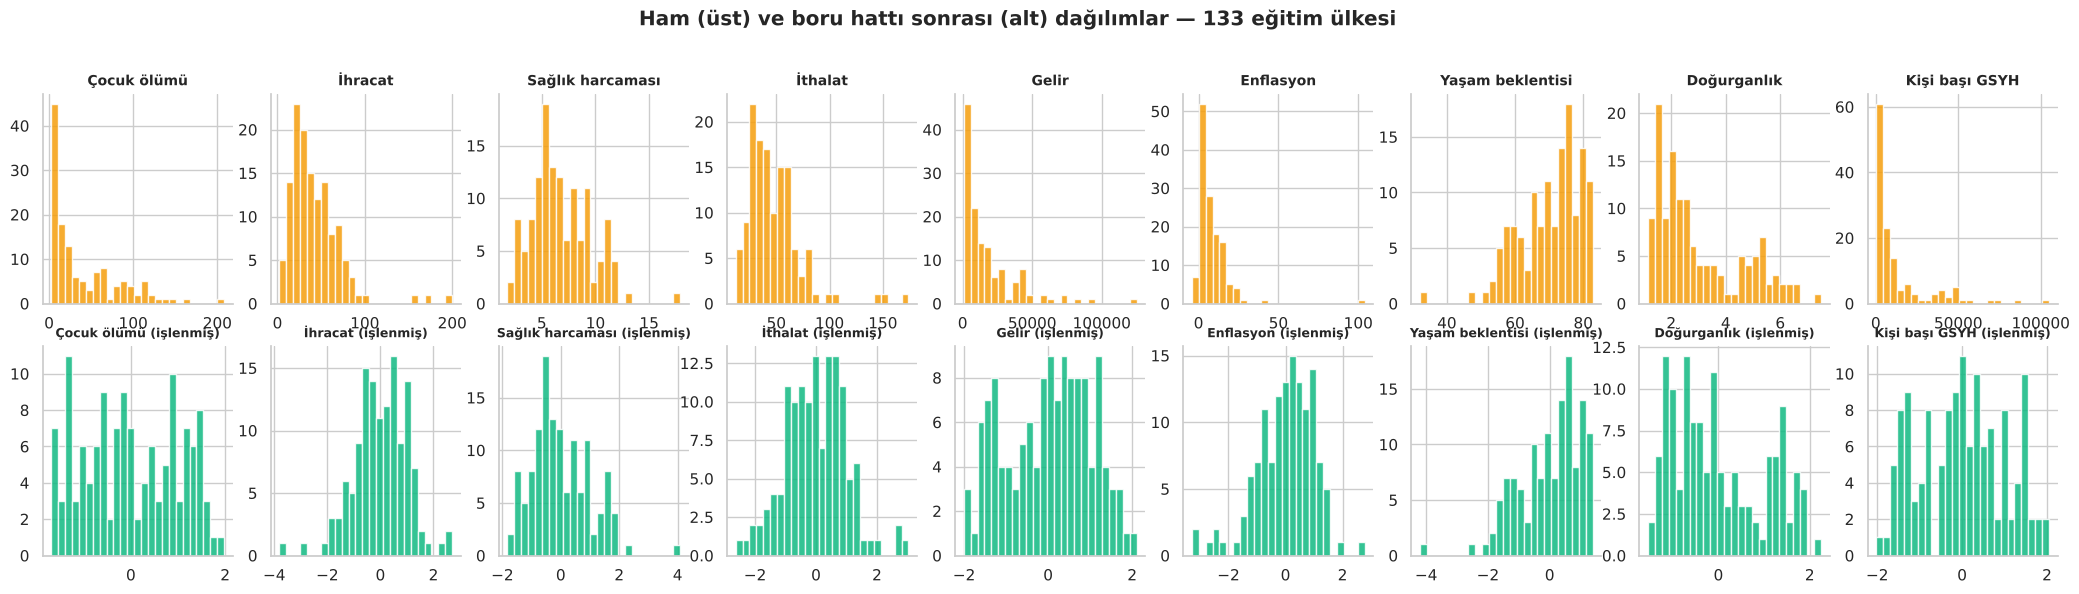

,Ham çarpıklık,İşlenmiş çarpıklık
Gösterge,,
Çocuk ölümü,1.36,0.04
İhracat,2.36,-0.42
Sağlık harcaması,0.73,0.73
İthalat,2.14,0.10
Gelir,2.19,-0.17
Enflasyon,5.35,-0.69
Yaşam beklentisi,-0.92,-0.92
Doğurganlık,0.86,0.46
Kişi başı GSYH,2.30,0.03


In [7]:
Ztr_df = pd.DataFrame(Ztr, columns=SUTUN)[OZELLIKLER]
fig, ax = plt.subplots(2, 9, figsize=(26, 6))
carpik = []
for j, s in enumerate(OZELLIKLER):
    x = Xtr[s].dropna()
    ax[0, j].hist(x, bins=25, color=RENK["altin"], alpha=.85); ax[0, j].set_title(s, fontsize=10)
    ax[1, j].hist(Ztr_df[s], bins=25, color=RENK["yesil"], alpha=.85); ax[1, j].set_title(f"{s} (işlenmiş)", fontsize=9)
    carpik.append({"Gösterge": s, "Ham çarpıklık": stats.skew(x), "İşlenmiş çarpıklık": stats.skew(Ztr_df[s])})
fig.suptitle("Ham (üst) ve boru hattı sonrası (alt) dağılımlar — 133 eğitim ülkesi", fontweight="bold", y=1.02)
kaydet(fig, "01_eda_dagilimlar"); plt.show()
carpik = pd.DataFrame(carpik).set_index("Gösterge"); display(carpik.round(2)); rapor_kaydet(carpik.round(3), "03_carpiklik")

### 🔗 5.2 · Göstergeler Arası İlişkiler

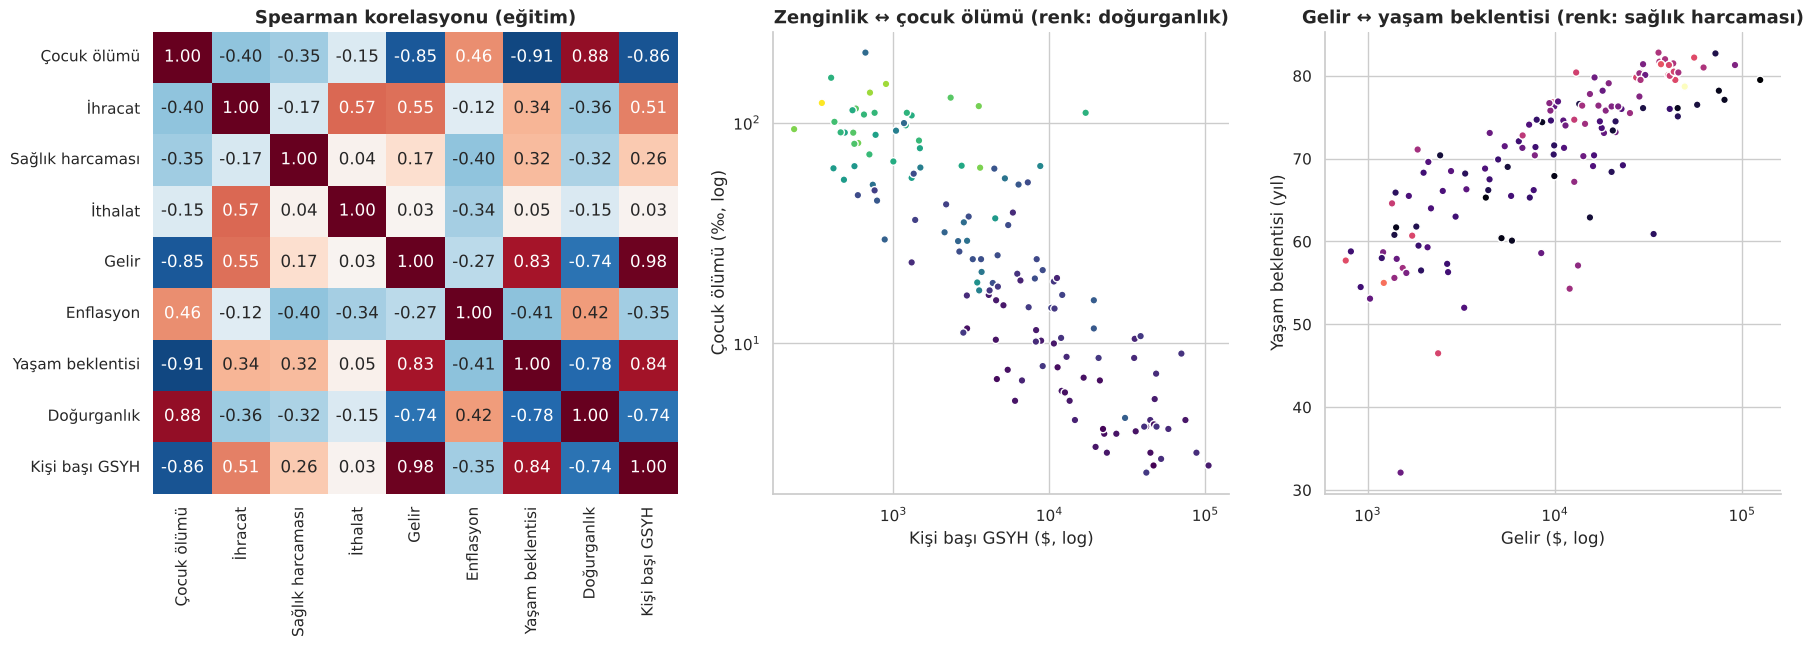

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(21, 6), gridspec_kw={"width_ratios": [1.15, 1, 1]})
kor = Ztr_df.corr(method="spearman")
sns.heatmap(kor, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax[0], cbar=False); ax[0].set_title("Spearman korelasyonu (eğitim)")
ax[1].scatter(tr["Kişi başı GSYH"], tr["Çocuk ölümü"], s=30, c=tr["Doğurganlık"], cmap="viridis", edgecolor="white")
ax[1].set(xscale="log", yscale="log", xlabel="Kişi başı GSYH ($, log)", ylabel="Çocuk ölümü (‰, log)", title="Zenginlik ↔ çocuk ölümü (renk: doğurganlık)")
ax[2].scatter(tr["Gelir"], tr["Yaşam beklentisi"], s=30, c=tr["Sağlık harcaması"], cmap="magma", edgecolor="white")
ax[2].set(xscale="log", xlabel="Gelir ($, log)", ylabel="Yaşam beklentisi (yıl)", title="Gelir ↔ yaşam beklentisi (renk: sağlık harcaması)")
kaydet(fig, "02_iliskiler"); plt.show()

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

**Gelir ile kişi başı GSYH** neredeyse aynı bilgiyi taşıyor (Spearman 0,98); **çocuk ölümü** ise yaşam beklentisi (−0,91), doğurganlık (+0,88), GSYH (−0,86) ve gelir (−0,85) ile çok güçlü ilişkili. Yani dokuz göstergenin beşi aslında tek bir büyük eksenin, bir **"kalkınma ekseni"nin** farklı yüzleri. **İhracat ve ithalat** (birbirleriyle +0,57) ve **sağlık harcaması** bu eksenden büyük ölçüde bağımsız ikinci bir hikâye anlatıyor (dışa açıklık ve sağlık sistemi). Segmentlerin büyük ölçüde kalkınma ekseni üzerinde dizilmesini, ama ticaret ve sağlık harcamasının **sınırdaki** ülkeleri bir yana ya da öbür yana itmesini bekleyebiliriz.

</td></tr></table>

### 🗺️ 5.3 · İlk Harita: Henüz Segment Yok

9 boyutlu ülkeleri görebilmek için iki boyutlu bir haritaya (PCA, **yalnızca eğitimde** öğrenilir) indiriyoruz; yanına da gerçek **dünya haritasını** koyuyoruz. Test ülkeleri haritada **kilitli** (koyu gri) gösteriliyor. Bu haritalar **yalnızca görselleştirme** içindir; kümeleme 9 boyutta yapılır.

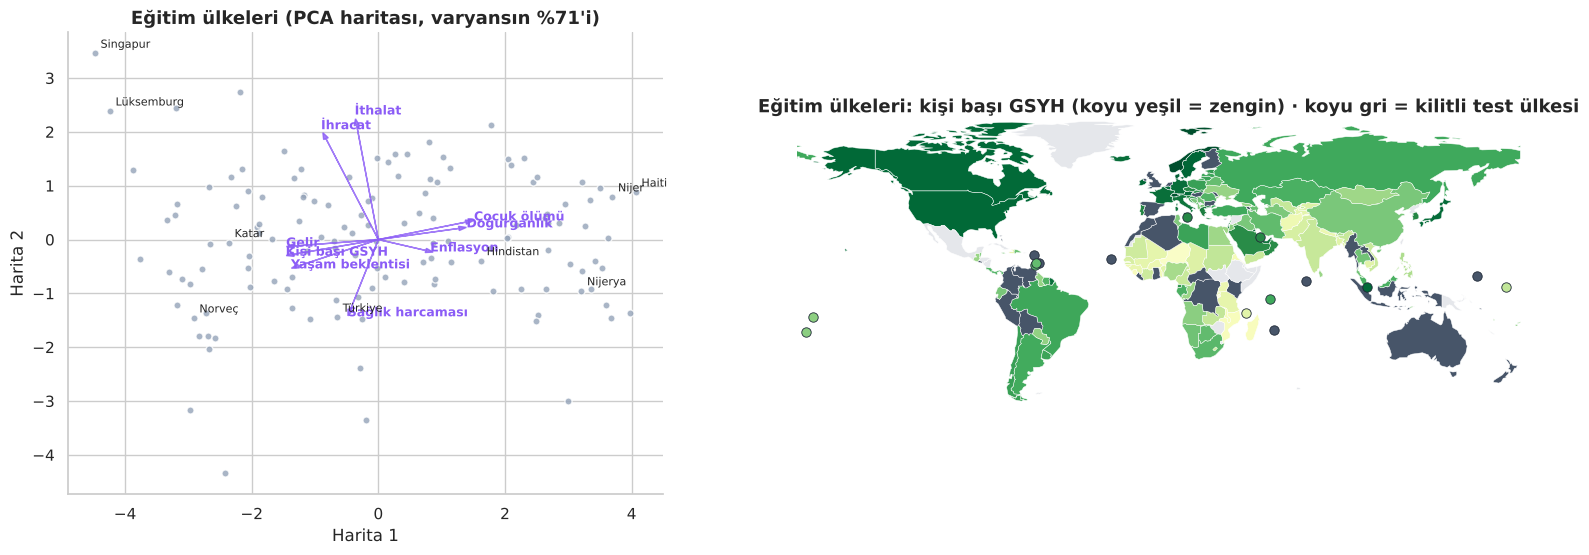

,Harita 1,Harita 2
Çocuk ölümü,0.432,0.101
İhracat,-0.259,0.586
İthalat,-0.107,0.664
Gelir,-0.416,-0.037
Kişi başı GSYH,-0.418,-0.085
Doğurganlık,0.398,0.065
Enflasyon,0.234,-0.063
Sağlık harcaması,-0.138,-0.407
Yaşam beklentisi,-0.394,-0.153


In [9]:
HARITA = PCA(3, random_state=RS).fit(Ztr)
Htr, Hte = HARITA.transform(Ztr), HARITA.transform(Zte)
oran = HARITA.explained_variance_ratio_
fig, ax = plt.subplots(1, 2, figsize=(19, 6), gridspec_kw={"width_ratios": [1, 1.25]})
ax[0].scatter(Htr[:, 0], Htr[:, 1], s=26, color=RENK["gri"], alpha=.8, edgecolor="white")
yuk = pd.DataFrame(HARITA.components_[:2].T, index=SUTUN, columns=["Harita 1", "Harita 2"])
for s, (x, y) in yuk.iterrows():
    ax[0].arrow(0, 0, x * 3.2, y * 3.2, color=RENK["mor"], head_width=.08, alpha=.8); ax[0].text(x * 3.5, y * 3.5, s, fontsize=9, color=RENK["mor"], fontweight="bold")
for a in ["Türkiye", "Nijer", "Lüksemburg", "Katar", "Haiti", "Hindistan", "Norveç", "Myanmar", "Nijerya", "Singapur"]:
    m = tr["Ülke"] == a
    if m.any(): ax[0].annotate(a, Htr[m.to_numpy()][0, :2], xytext=(4, 4), textcoords="offset points", fontsize=8)
ax[0].set(title=f"Eğitim ülkeleri (PCA haritası, varyansın %{oran[:2].sum() * 100:.0f}'i)", xlabel="Harita 1", ylabel="Harita 2")
renk = {u: to_hex(plt.cm.YlGn((np.log(g) - np.log(200)) / (np.log(110_000) - np.log(200)))) for u, g in zip(tr["Ülke (EN)"], tr["Kişi başı GSYH"])}
renk.update({u: "#475569" for u in te["Ülke (EN)"]})
dunya_haritasi(ax[1], renk, baslik="Eğitim ülkeleri: kişi başı GSYH (koyu yeşil = zengin) · koyu gri = kilitli test ülkesi")
kaydet(fig, "03_ilk_harita"); plt.show()
display(yuk.round(3))

<a id="p6"></a>

<p align="center">
  <img src="assets/proje_06.svg" width="100%" alt="Bölüm 6: Ön işleme deneyi">
</p>

### 🧪 6.1 · Aynı Ward, Altı Farklı Ön İşleme

Ön işleme, kümelemede **sonucu doğrudan belirler**: mesafeyi değiştirdiği için "hangi ülke hangisine benziyor?" sorusunun cevabı değişir. Aynı Ward ağacını (k = 3'e kesilmiş) altı ön işlemeyle kurup dört şeye bakıyoruz:

- **Söz hakkı dengesi:** her göstergenin segmentleri ayırmadaki payı (η², **ortak** log + standart uzayda ölçülür). Denge = payların normalleştirilmiş entropisi (1 = dokuz göstergenin hepsi eşit söz sahibi).
- **En büyük söz:** segmentleri en çok hangi gösterge belirliyor ve payı ne?
- **Kararlılık:** 20 bootstrap örneğinde ortalama ARI.
- **Kofenetik korelasyon** ve **en küçük segment payı**.

,Boyut,Söz hakkı dengesi ↑,En büyük söz,En büyük söz payı,Kararlılık ↑,Kofenetik ↑,En küçük segment %,Boylar
Ön işleme,,,,,,,,
Ham (ölçeksiz),9,0.860,Kişi başı GSYH,0.229,0.536,0.821,15.038,"[67, 46, 20]"
Standart,9,0.857,Çocuk ölümü,0.193,0.613,0.511,20.301,"[63, 43, 27]"
Robust,9,0.911,Çocuk ölümü,0.186,0.411,0.602,18.797,"[56, 52, 25]"
Log + standart,9,0.945,Çocuk ölümü,0.171,0.661,0.611,26.316,"[59, 39, 35]"
Yeo-Johnson + standart,9,0.930,Çocuk ölümü,0.191,0.542,0.579,25.564,"[51, 48, 34]"
Log + standart + PCA (%90),4,0.944,Çocuk ölümü,0.169,0.775,0.627,27.068,"[61, 36, 36]"


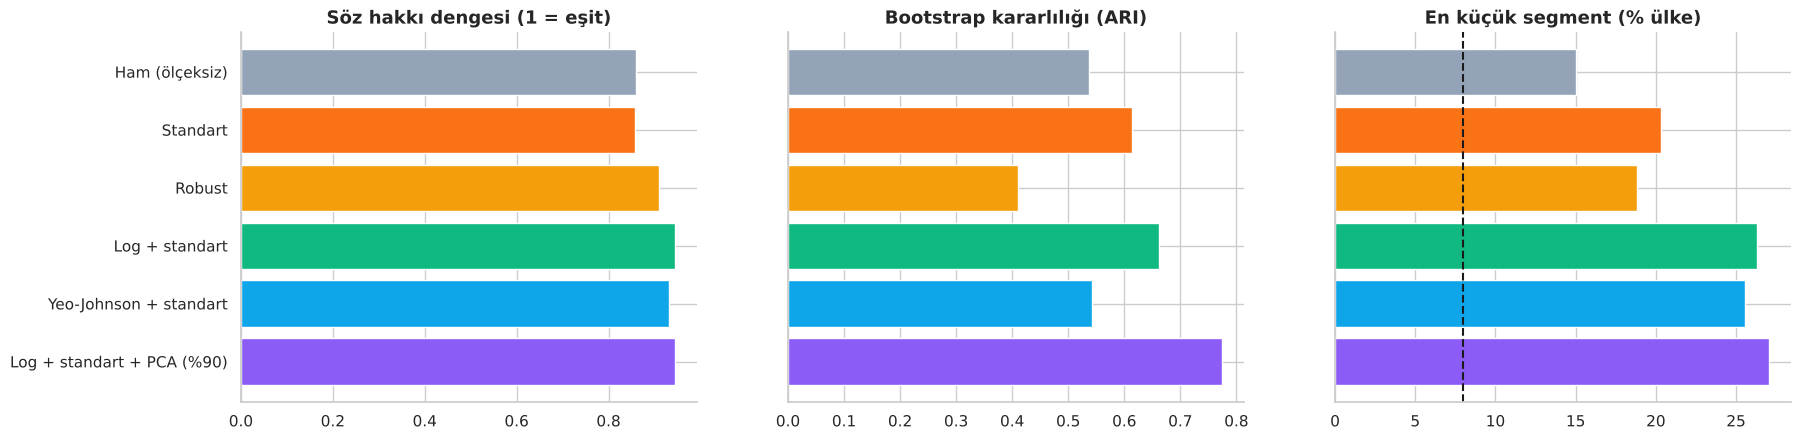

In [10]:
def bootstrap_ari(model, Z, B=20, tohum=0):
    """Referans etiketler tüm eğitimden; karşılaştırma bootstrap örneğindeki (tekrarsız) ortak ülkelerden yapılır."""
    ref = np.asarray(clone(model).fit_predict(Z)); rng = np.random.default_rng(tohum); s = []
    for _ in range(B):
        i = np.unique(rng.choice(len(Z), len(Z)))
        s.append(adjusted_rand_score(ref[i], np.asarray(clone(model).fit_predict(Z[i]))))
    return float(np.mean(s))

def denge(eta):
    p = np.asarray(eta) / np.sum(eta); p = p[p > 0]
    return float(-(p * np.log(p)).sum() / np.log(len(eta)))

secenek = {"Ham (ölçeksiz)": on_isleme(None, None), "Standart": on_isleme(None, "standart"), "Robust": on_isleme(None, "robust"),
           "Log + standart": on_isleme("log", "standart"), "Yeo-Johnson + standart": on_isleme("yeo-johnson", "standart"),
           "Log + standart + PCA (%90)": on_isleme("log", "standart", pca=0.90)}
on_deney = []
for ad, boru in secenek.items():
    Z = np.asarray(boru.fit(Xtr).transform(Xtr))
    et = AgglomerativeClustering(3).fit_predict(Z)
    eta = [eta_kare(Ztr[:, j], et) for j in range(9)]           # söz hakkı her zaman ORTAK uzayda ölçülür
    on_deney.append({"Ön işleme": ad, "Boyut": Z.shape[1], "Söz hakkı dengesi ↑": denge(eta), "En büyük söz": SUTUN[int(np.argmax(eta))],
                     "En büyük söz payı": max(eta) / sum(eta), "Kararlılık ↑": bootstrap_ari(AgglomerativeClustering(3), Z, 20, 1),
                     "Kofenetik ↑": cophenet(linkage(Z, "ward"), pdist(Z))[0], "En küçük segment %": np.bincount(et).min() / len(et) * 100,
                     "Boylar": sorted(np.bincount(et).tolist(), reverse=True)})
on_deney = pd.DataFrame(on_deney).set_index("Ön işleme")
display(on_deney.round(3)); rapor_kaydet(on_deney.round(4), "04_on_isleme_deneyi")

fig, ax = plt.subplots(1, 3, figsize=(20, 4.8))
r = [RENK["gri"], RENK["turuncu"], RENK["altin"], RENK["yesil"], RENK["mavi"], RENK["mor"]]
ax[0].barh(on_deney.index, on_deney["Söz hakkı dengesi ↑"], color=r); ax[0].set(title="Söz hakkı dengesi (1 = eşit)"); ax[0].invert_yaxis()
ax[1].barh(on_deney.index, on_deney["Kararlılık ↑"], color=r); ax[1].set(title="Bootstrap kararlılığı (ARI)"); ax[1].invert_yaxis()
ax[2].barh(on_deney.index, on_deney["En küçük segment %"], color=r); ax[2].axvline(8, color="k", ls="--"); ax[2].set(title="En küçük segment (% ülke)"); ax[2].invert_yaxis()
for a in ax[1:]: a.set_yticklabels([])
kaydet(fig, "04_on_isleme_deneyi"); plt.show()

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

**Ham** veride segmentleri en çok **kişi başı GSYH** belirliyor ve söz hakkı dengesi düşük (0,86); **Standart** ölçekleme de denge açısından iyileşme getirmiyor (0,86), çünkü çarpık sütunların uç değerleri (Lüksemburg, Katar, Singapur) mesafeyi bükmeye devam ediyor. **Log + standart** dokuz göstergeye en dengeli söz hakkını veriyor (**0,945**; en büyük pay çocuk ölümünde, yalnızca %17). PCA eklenince kararlılık artıyor (0,78 ↔ 0,66) ama segmentler artık **4 soyut eksende** tanımlanıyor; yönetim kuruluna "çocuk ölümü şu, gelir bu" diye açıklanamıyor ve fazladan öğrenilen bir adım ekleniyor. **Karar: log + standart.** Not: aynı ayarla bile Ward'ın 20 bootstraplik kararlılığı tohuma göre 0,66–0,74 arasında oynuyor; küçük veride kararlılık ölçümünün kendisi de gürültülüdür.

</td></tr></table>

<a id="p7"></a>

<p align="center">
  <img src="assets/proje_07.svg" width="100%" alt="Bölüm 7: Kaç segment?">
</p>

### 🌳 7.1 · Eğitim Ülkelerinin Soy Ağacı

Önce 133 eğitim ülkesinin Ward ağacına bakalım. Son 30 birleşmeyi gösteren **kırpılmış** bir dendrogram ve son birleşme yükseklikleri:

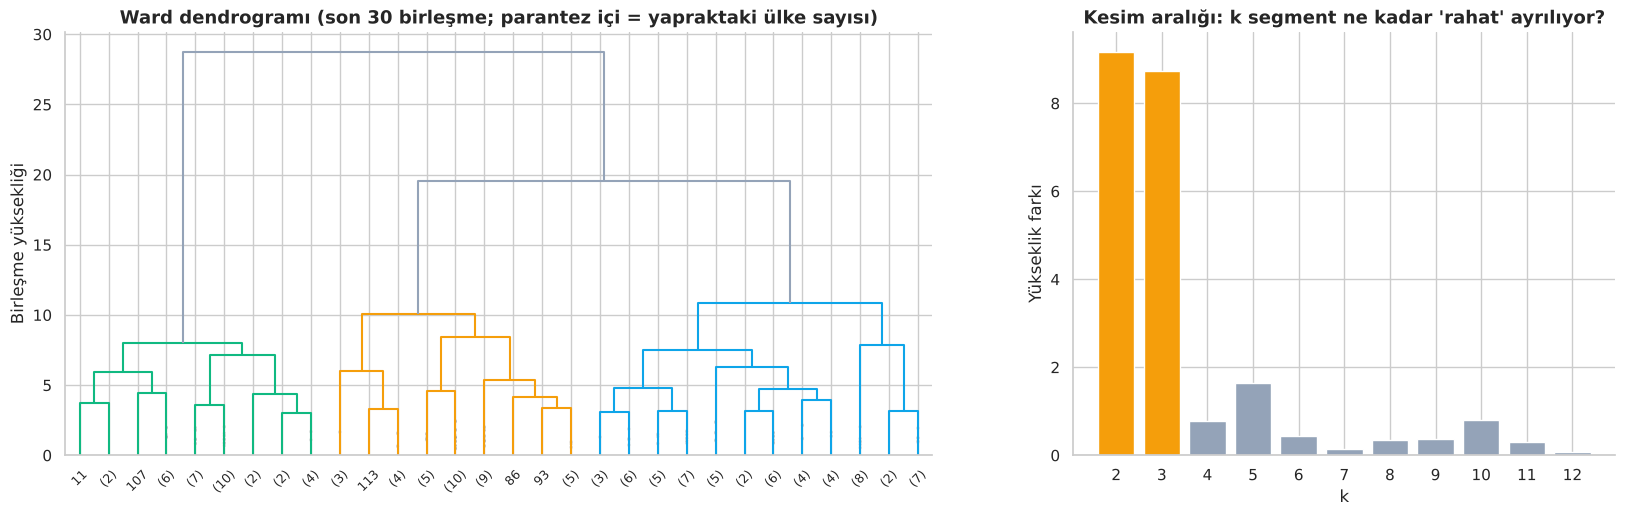

In [11]:
Z_ward = linkage(Ztr, method="ward")
yuk = Z_ward[:, 2]
fig, ax = plt.subplots(1, 2, figsize=(20, 5.5), gridspec_kw={"width_ratios": [1.6, 1]})
dendrogram(Z_ward, truncate_mode="lastp", p=30, ax=ax[0], color_threshold=(yuk[-3] + yuk[-2]) / 2, above_threshold_color="#94A3B8",
           show_contracted=True, leaf_font_size=9)
ax[0].set(title="Ward dendrogramı (son 30 birleşme; parantez içi = yapraktaki ülke sayısı)", ylabel="Birleşme yüksekliği")
son = yuk[::-1][:12]
ax[1].bar(range(2, 13), son[:11] - son[1:12], color=[RENK["altin"] if k in (2, 3) else RENK["gri"] for k in range(2, 13)])
ax[1].set(title="Kesim aralığı: k segment ne kadar 'rahat' ayrılıyor?", xlabel="k", ylabel="Yükseklik farkı"); ax[1].set_xticks(range(2, 13))
kaydet(fig, "05_egitim_dendrogrami"); plt.show()

### 🔢 7.2 · Beş Ölçüt, k = 2…8 ve Kural 1

In [12]:
def k_satiri(k):
    et = AgglomerativeClustering(k).fit_predict(Ztr)
    return {"k": k, "Kesim aralığı ↑": yuk[-(k - 1)] - yuk[-k], "Silüet ↑": silhouette_score(Ztr, et), "Davies-Bouldin ↓": davies_bouldin_score(Ztr, et),
            "Calinski-Harabasz ↑": calinski_harabasz_score(Ztr, et), "Kararlılık ↑": bootstrap_ari(AgglomerativeClustering(k), Ztr, 20, k),
            "En küçük segment %": np.bincount(et).min() / len(et) * 100, "Boylar": sorted(np.bincount(et).tolist(), reverse=True)}
k_tablo = pd.DataFrame(Parallel(n_jobs=N_JOBS)(delayed(k_satiri)(k) for k in range(2, 9))).set_index("k")

# Kural 1
k_tablo["Uygun"] = (k_tablo["Kararlılık ↑"] >= 0.70) & (k_tablo["En küçük segment %"] >= 8) & (k_tablo.index >= 3)
sira = pd.concat([k_tablo["Kesim aralığı ↑"].rank(ascending=False), k_tablo["Silüet ↑"].rank(ascending=False), k_tablo["Davies-Bouldin ↓"].rank(),
                  k_tablo["Calinski-Harabasz ↑"].rank(ascending=False), k_tablo["Kararlılık ↑"].rank(ascending=False)], axis=1).mean(1)
k_tablo["Bileşik sıra ↓"] = sira
K = int(k_tablo[k_tablo["Uygun"]]["Bileşik sıra ↓"].idxmin()) if k_tablo["Uygun"].any() else 3
display(k_tablo.round(3)); rapor_kaydet(k_tablo.round(4), "05_k_secimi")
print(f"Kural 1 sonucu → K = {K}  |  geometrik ölçütlerin tercihi: silüet k = {k_tablo['Silüet ↑'].idxmax()}, "
      f"DB k = {k_tablo['Davies-Bouldin ↓'].idxmin()}, CH k = {k_tablo['Calinski-Harabasz ↑'].idxmax()}, kesim aralığı k = {k_tablo['Kesim aralığı ↑'].idxmax()}")

,Kesim aralığı ↑,Silüet ↑,Davies-Bouldin ↓,Calinski-Harabasz ↑,Kararlılık ↑,En küçük segment %,Boylar,Uygun,Bileşik sıra ↓
k,,,,,,,,,
2,9.166,0.322,1.076,69.031,0.574,26.316,"[98, 35]",False,1.2
3,8.730,0.249,1.332,66.364,0.742,26.316,"[59, 39, 35]",True,1.8
4,0.770,0.213,1.454,53.486,0.558,12.782,"[42, 39, 35, 17]",False,3.8
5,1.652,0.213,1.423,47.357,0.543,6.015,"[42, 35, 31, 17, 8]",False,4.2
6,0.433,0.190,1.380,42.589,0.543,6.015,"[42, 35, 17, 16, 15, 8]",False,4.6
7,0.154,0.170,1.480,39.534,0.520,6.015,"[42, 25, 17, 16, 15, 10, 8]",False,6.6
8,0.345,0.185,1.345,37.729,0.515,6.015,"[42, 25, 16, 15, 10, 9, 8, 8]",False,5.8


Kural 1 sonucu → K = 3  |  geometrik ölçütlerin tercihi: silüet k = 2, DB k = 2, CH k = 2, kesim aralığı k = 2


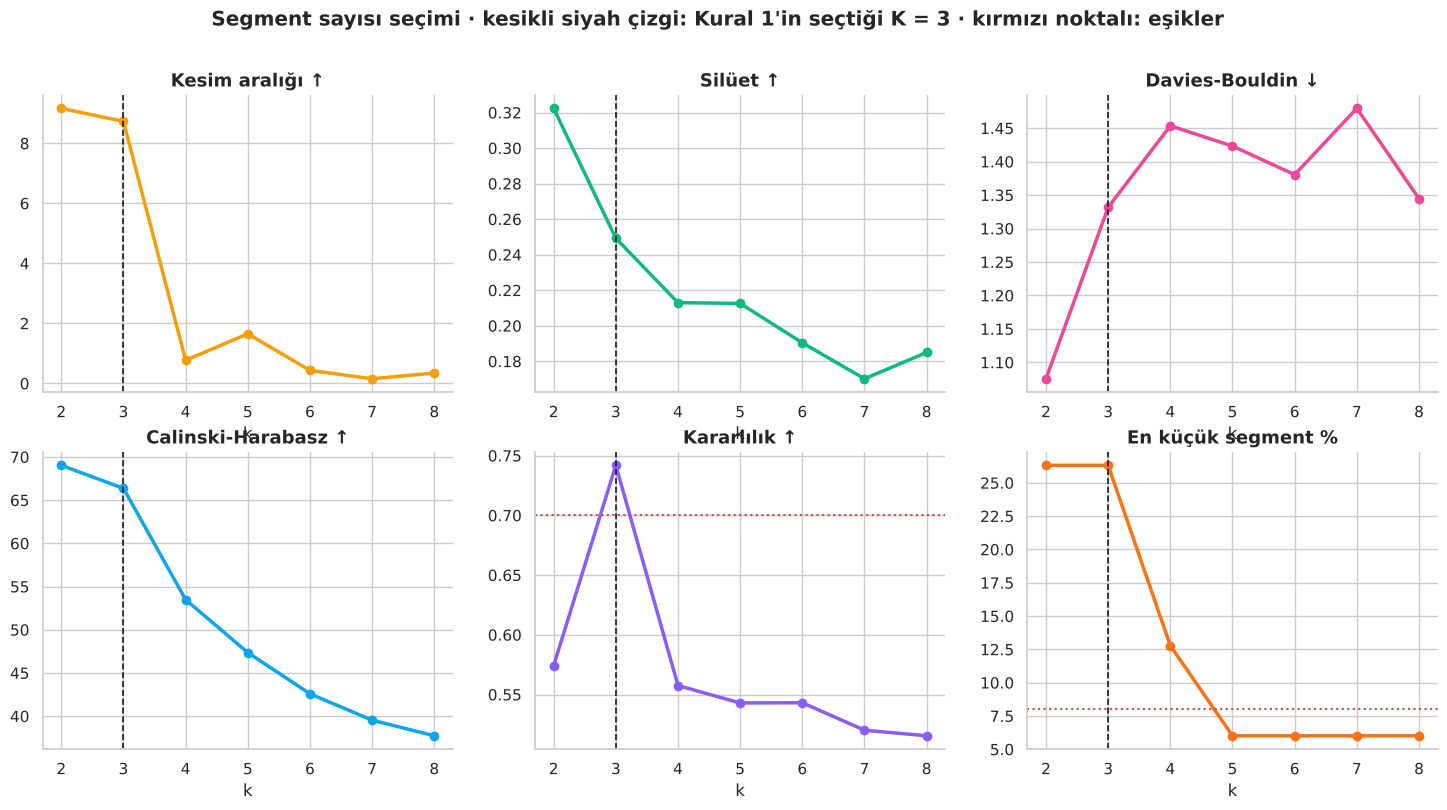

In [13]:
fig, ax = plt.subplots(2, 3, figsize=(18, 8.5))
cizim = [("Kesim aralığı ↑", RENK["altin"]), ("Silüet ↑", RENK["yesil"]), ("Davies-Bouldin ↓", RENK["pembe"]),
         ("Calinski-Harabasz ↑", RENK["mavi"]), ("Kararlılık ↑", RENK["mor"]), ("En küçük segment %", RENK["turuncu"])]
for a, (s, r) in zip(ax.ravel(), cizim):
    a.plot(k_tablo.index, k_tablo[s], "o-", color=r, lw=2.5); a.axvline(K, color="k", ls="--", lw=1.2); a.set(title=s, xlabel="k")
ax[1, 1].axhline(.70, color="r", ls=":"); ax[1, 2].axhline(8, color="r", ls=":")
fig.suptitle(f"Segment sayısı seçimi · kesikli siyah çizgi: Kural 1'in seçtiği K = {K} · kırmızı noktalı: eşikler", fontweight="bold")
kaydet(fig, "06_k_secimi"); plt.show()

<table><tr><td>

<img src="assets/etiket_not.svg" height="34" alt="Not">

Geometrik ölçütlerin **dördü de k = 2**'yi seçiyor (silüet 0,32, en geniş kesim aralığı 9,2): en güçlü ayrım **"Öncelikli destek ihtiyacı olan 35 ülke" ile "geri kalan 98 ülke"** arasındadır. Ama k = 2'nin kararlılığı yalnızca 0,57 ve kuruluş zaten bu ikiliği biliyor. **Kural 1**'in eşiklerini (kararlılık ≥ 0,70, en küçük segment ≥ %8, k ≥ 3) yalnızca **k = 3** geçiyor (kararlılık 0,74; kesim aralığı 8,7 ile k = 2'ye çok yakın). k = 4 ve sonrasında kesim aralıkları 2'nin altına düşüyor ve kararlılık 0,56'ya iniyor: dendrogram üçten sonrasını **net** bir yapı olarak desteklemiyor. Seçim **K = 3**; bu, kuralın sonuçlardan önce yazılmış olmasının değerini gösteriyor: geometrik ölçütler tek başına bırakılsaydı işe pek yaramayan ikili bir ayrım seçilecekti.

</td></tr></table>

### 🎞️ 7.3 · k Arttıkça Dünya Haritası (Animasyon)

Eğitim ülkelerinin Ward ağacı k = 2…7 için kesiliyor; segmentler **ortanca çocuk ölümüne** göre kırmızıdan (en yüksek) maviye (en düşük) boyanıyor. Test ülkeleri hâlâ kilitli (koyu gri).

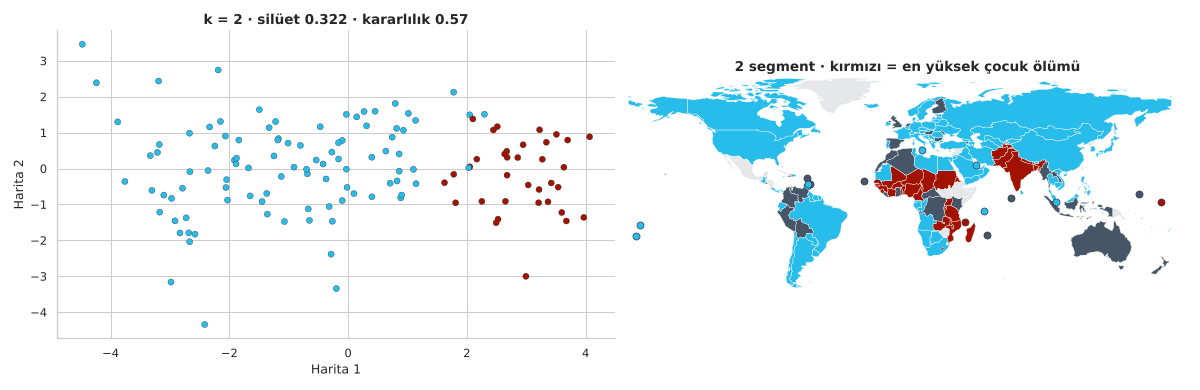

In [14]:
def segment_renkleri(et, df=tr):
    """Segmentleri ortanca çocuk ölümüne göre sıralayıp kırmızı (en yüksek) → yeşil (en düşük) renk verir."""
    sira = df.groupby(et)["Çocuk ölümü"].median().sort_values(ascending=False).index
    palet = [to_hex(c) for c in plt.cm.turbo(np.linspace(.95, .25, len(sira)))]          # kırmızı → turuncu → yeşil → mavi
    return {s: palet[j] for j, s in enumerate(sira)}

k_et = {k: AgglomerativeClustering(k).fit_predict(Ztr) for k in range(2, 8)}
def kare(i, fig):
    k = min(i + 2, 7); et = k_et[k]; renk = segment_renkleri(et)
    a1 = fig.add_subplot(1, 2, 1); a2 = fig.add_subplot(1, 2, 2)
    a1.scatter(Htr[:, 0], Htr[:, 1], s=34, c=[renk[e] for e in et], edgecolor="k", linewidth=.3)
    a1.set(title=f"k = {k} · silüet {silhouette_score(Ztr, et):.3f} · kararlılık {k_tablo.loc[k, 'Kararlılık ↑']:.2f}", xlabel="Harita 1", ylabel="Harita 2")
    harita = {u: renk[e] for u, e in zip(tr["Ülke (EN)"], et)}; harita.update({u: "#475569" for u in te["Ülke (EN)"]})
    dunya_haritasi(a2, harita, baslik=f"{k} segment · kırmızı = en yüksek çocuk ölümü")
gif_yap(kare, 7, "07_k_harita_animasyon", boyut=(16, 5.2), fps=0.9)

<a id="p8"></a>

<p align="center">
  <img src="assets/proje_08.svg" width="100%" alt="Bölüm 8: Büyük yarış">
</p>

### 🏁 8.1 · Yarışçılar: 27 Algoritma + Rastgele Taban

<p align="center">
  <img src="assets/diyagram_aileler.svg" width="100%" alt="Algoritma aileleri">
</p>

Hepsi **aynı 133 eğitim ülkesiyle**, **aynı 9 boyutlu ölçüm uzayında** (log + standart) yarışıyor. Segment sayısını parametre olarak alanlara **k = K** veriliyor; segment sayısını **kendisi bulan** algoritmalara (Mean Shift, DBSCAN, OPTICS, HDBSCAN, Affinity Propagation) verilmiyor, yalnızca veriye dayalı makul ayarlar veriliyor (yalnızca eğitimden).

In [15]:
k_uzak = np.sort(NearestNeighbors(n_neighbors=6).fit(Ztr).kneighbors(Ztr)[0][:, -1])
EPS = float(np.quantile(k_uzak, 0.90))                                   # 6. komşu uzaklığının %90'lık dilimi
BANT = float(estimate_bandwidth(Ztr, quantile=0.3, random_state=RS))
TERCIH = float(np.min(-pairwise_distances(Ztr, squared=True)))           # Affinity Propagation: az küme için en küçük benzerlik
KOMSU5 = partial(kneighbors_graph, n_neighbors=5, include_self=False)    # Ward + komşuluk kısıtı (bootstrap'ta yeniden kurulur)

def yariscilar(K):
    return {
        # 🌳 Birleştiren hiyerarşik (scikit-learn)
        "Ward": ("Birleştiren hiyerarşik", AgglomerativeClustering(K, linkage="ward")),
        "Tam bağlantı": ("Birleştiren hiyerarşik", AgglomerativeClustering(K, linkage="complete")),
        "Ortalama bağlantı (UPGMA)": ("Birleştiren hiyerarşik", AgglomerativeClustering(K, linkage="average")),
        "Tek bağlantı": ("Birleştiren hiyerarşik", AgglomerativeClustering(K, linkage="single")),
        "Ortalama bağlantı (kosinüs)": ("Birleştiren hiyerarşik", AgglomerativeClustering(K, linkage="average", metric="cosine")),
        "Tam bağlantı (Manhattan)": ("Birleştiren hiyerarşik", AgglomerativeClustering(K, linkage="complete", metric="manhattan")),
        "Ward + 5 komşu kısıtı": ("Birleştiren hiyerarşik", AgglomerativeClustering(K, linkage="ward", connectivity=KOMSU5)),
        # 🌳 Birleştiren hiyerarşik (SciPy)
        "WPGMA (ağırlıklı)": ("Birleştiren hiyerarşik", ScipyBaglanti(K, "weighted")),
        "UPGMC (merkez)": ("Birleştiren hiyerarşik", ScipyBaglanti(K, "centroid")),
        "WPGMC (medyan)": ("Birleştiren hiyerarşik", ScipyBaglanti(K, "median")),
        # 🪓 Bölen hiyerarşik
        "DIANA": ("Bölen hiyerarşik", DIANA(K)),
        "Bisecting K-Means": ("Bölen hiyerarşik", BisectingKMeans(K, n_init=10, random_state=RS)),
        # 🧺 Ağaç / özet / konsensüs
        "BIRCH": ("Ağaç/özet/konsensüs", Birch(n_clusters=K, threshold=0.5)),
        "Özellik ağacı + Ward": ("Ağaç/özet/konsensüs", Pipeline([("ozellik", FeatureAgglomeration(n_clusters=4)), ("ward", AgglomerativeClustering(K))])),
        "Konsensüs hiyerarşik": ("Ağaç/özet/konsensüs", KonsensusHiyerarsik(K, B=30, random_state=RS)),
        # 🎯 Merkez
        "K-Means": ("Merkez", KMeans(K, n_init=10, random_state=RS)),
        "Mini-Batch K-Means": ("Merkez", MiniBatchKMeans(K, n_init=10, random_state=RS)),
        "K-Medoids": ("Merkez", KMedoids(K, n_init=10, random_state=RS)),
        # 🔔 Olasılık
        "GMM (tam kovaryans)": ("Olasılık", GaussianMixture(K, n_init=5, random_state=RS)),
        "GMM (köşegen)": ("Olasılık", GaussianMixture(K, covariance_type="diag", n_init=5, random_state=RS)),
        "Bayesçi GMM": ("Olasılık", BayesianGaussianMixture(n_components=K, n_init=3, max_iter=500, random_state=RS)),
        # 🕸️ Graf ve mesaj
        "Spektral (komşuluk grafı)": ("Graf", SpectralClustering(K, affinity="nearest_neighbors", n_neighbors=10, random_state=RS)),
        "Affinity Propagation": ("Graf", AffinityPropagation(preference=TERCIH, damping=0.9, random_state=RS)),
        # 🌫️ Yoğunluk
        "HDBSCAN (yoğunluk hiyerarşisi)": ("Yoğunluk", HDBSCAN(min_cluster_size=8, copy=True)),
        "OPTICS": ("Yoğunluk", OPTICS(min_samples=6)),
        "DBSCAN": ("Yoğunluk", DBSCAN(eps=EPS, min_samples=6)),
        "Mean Shift": ("Yoğunluk", MeanShift(bandwidth=BANT)),
        # 🎲 Taban
        "Rastgele taban": ("Taban", RastgeleTaban(K, random_state=RS)),
    }
YARISCI = yariscilar(K)
print(f"{len(YARISCI) - 1} algoritma + rastgele taban | K = {K} | DBSCAN eps = {EPS:.2f} | Mean Shift bant = {BANT:.2f}")
print(pd.Series({a: f for a, (f, _) in YARISCI.items()}).value_counts().to_dict())

27 algoritma + rastgele taban | K = 3 | DBSCAN eps = 2.50 | Mean Shift bant = 3.06
{'Birleştiren hiyerarşik': 10, 'Yoğunluk': 4, 'Ağaç/özet/konsensüs': 3, 'Merkez': 3, 'Olasılık': 3, 'Bölen hiyerarşik': 2, 'Graf': 2, 'Taban': 1}


### 🏎️ 8.2 · Yarışı Koşalım

Her algoritma için: **eğitimde kur** → segment sayısı, gürültü ve boylar → **iç ölçütler** (silüet, DB, CH; gürültü dışı ülkelerde) → **10 bootstrap** ile kararlılık → süre. Sonra **Kural 2** ile uygunluk ve bileşik sıra. Test seti burada **kullanılmıyor**.

In [16]:
def ic_olcut(Z, et):
    ok = et >= 0
    if len(np.unique(et[ok])) < 2: return dict(sil=np.nan, db=np.nan, ch=np.nan)
    return dict(sil=silhouette_score(Z[ok], et[ok]), db=davies_bouldin_score(Z[ok], et[ok]), ch=calinski_harabasz_score(Z[ok], et[ok]))

def kos(ad, aile, model):
    t0 = time.perf_counter(); et = np.asarray(clone(model).fit_predict(Ztr)); sure = time.perf_counter() - t0
    ok = et >= 0; boy = np.bincount(et[ok]) if ok.any() else np.array([0])
    return ad, et, {"Aile": aile, "Segment": int(len(np.unique(et[ok]))), "Gürültü %": (~ok).mean() * 100,
                    "En küçük %": boy.min() / len(et) * 100, "Boylar": sorted(boy.tolist(), reverse=True)[:6],
                    **{k: v for k, v in zip(["Silüet", "Davies-Bouldin", "Calinski-Harabasz"], ic_olcut(Ztr, et).values())},
                    "Kararlılık (ARI)": bootstrap_ari(model, Ztr, 10, 7), "Süre (sn)": sure}

t0 = time.perf_counter()
sonuc = Parallel(n_jobs=N_JOBS)(delayed(kos)(ad, aile, m) for ad, (aile, m) in YARISCI.items())
ETIKET = {ad: et for ad, et, _ in sonuc}
yaris = pd.DataFrame({ad: s for ad, _, s in sonuc}).T
for c in ["Segment", "Gürültü %", "En küçük %", "Silüet", "Davies-Bouldin", "Calinski-Harabasz", "Kararlılık (ARI)", "Süre (sn)"]:
    yaris[c] = yaris[c].astype(float)

# Kural 2: uygunluk ve bileşik sıra (yalnızca eğitim ölçütleri)
yaris["Uygun"] = yaris["Segment"].between(2, 10) & (yaris["Gürültü %"] <= 10) & (yaris["En küçük %"] >= 5) & (yaris.index != "Rastgele taban")
u = yaris[yaris["Uygun"]]
yaris["Bileşik sıra"] = np.nan
yaris.loc[u.index, "Bileşik sıra"] = pd.concat([u["Silüet"].rank(ascending=False), u["Davies-Bouldin"].rank(),
                                                 u["Calinski-Harabasz"].rank(ascending=False), u["Kararlılık (ARI)"].rank(ascending=False)], axis=1).mean(1)
yaris = yaris.sort_values(["Uygun", "Bileşik sıra"], ascending=[False, True])
print(f"Toplam süre: {time.perf_counter() - t0:.1f} sn | uygun: {int(yaris['Uygun'].sum())} / {len(yaris) - 1}")
display(yaris.drop(columns=["Boylar"]).round(3)); rapor_kaydet(yaris.round(4), "06_buyuk_yaris")

Toplam süre: 2.0 sn | uygun: 18 / 27


,Aile,Segment,Gürültü %,En küçük %,Silüet,Davies-Bouldin,Calinski-Harabasz,Kararlılık (ARI),Süre (sn),Uygun,Bileşik sıra
K-Means,Merkez,3.0,0.000,27.820,0.262,1.314,69.923,0.923,0.008,True,2.25
Spektral (komşuluk grafı),Graf,3.0,0.000,22.556,0.260,1.288,67.256,0.828,0.007,True,4.00
K-Medoids,Merkez,3.0,0.000,24.060,0.264,1.292,69.037,0.761,0.002,True,4.50
Konsensüs hiyerarşik,Ağaç/özet/konsensüs,3.0,0.000,26.316,0.251,1.324,66.549,0.804,0.020,True,6.75
GMM (tam kovaryans),Olasılık,3.0,0.000,26.316,0.254,1.315,68.032,0.603,0.017,True,6.75
Ward,Birleştiren hiyerarşik,3.0,0.000,26.316,0.249,1.332,66.364,0.811,0.001,True,8.00
GMM (köşegen),Olasılık,3.0,0.000,29.323,0.241,1.392,67.550,0.898,0.007,True,8.00
Ward + 5 komşu kısıtı,Birleştiren hiyerarşik,3.0,0.000,26.316,0.249,1.332,66.364,0.782,0.004,True,8.25
Mini-Batch K-Means,Merkez,3.0,0.000,28.571,0.248,1.366,68.816,0.778,0.008,True,8.25
Bisecting K-Means,Bölen hiyerarşik,3.0,0.000,25.564,0.231,1.409,64.757,0.911,0.008,True,10.25


### 📊 8.3 · Yarışın Görseli

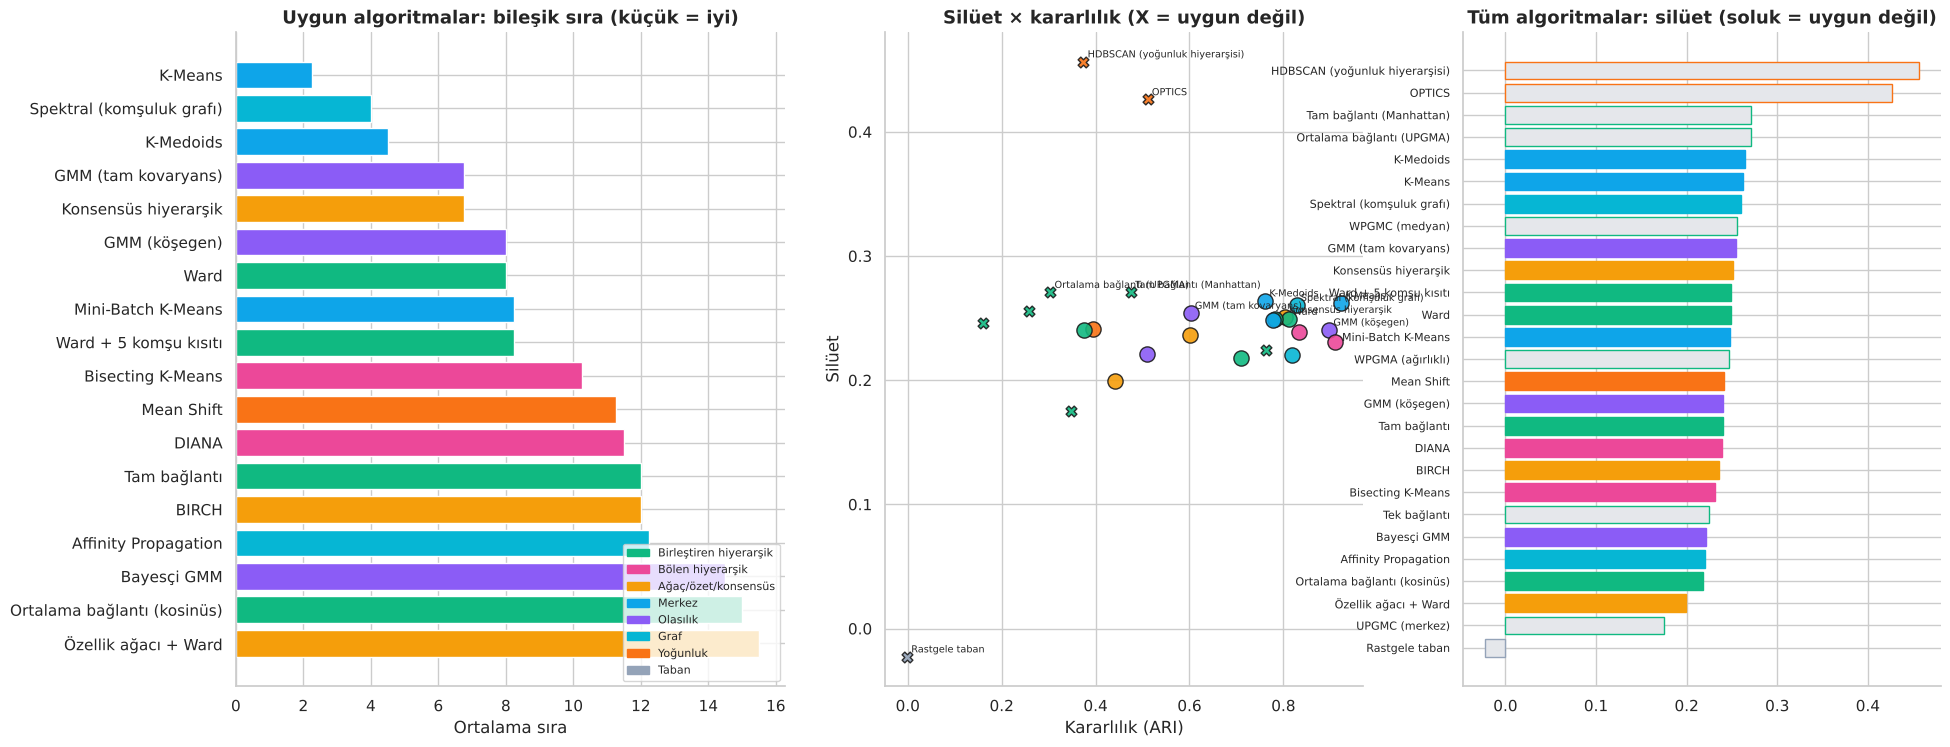

In [17]:
aile_renk = {"Birleştiren hiyerarşik": RENK["yesil"], "Bölen hiyerarşik": RENK["pembe"], "Ağaç/özet/konsensüs": RENK["altin"], "Merkez": RENK["mavi"],
             "Olasılık": RENK["mor"], "Graf": RENK["cyan"], "Yoğunluk": RENK["turuncu"], "Taban": RENK["gri"]}
uy = yaris[yaris["Uygun"]].sort_values("Bileşik sıra", ascending=False)
fig, ax = plt.subplots(1, 3, figsize=(22, 8.5), gridspec_kw={"width_ratios": [1.15, 1, 1]})
ax[0].barh(uy.index, uy["Bileşik sıra"], color=[aile_renk[a] for a in uy["Aile"]]); ax[0].set(title="Uygun algoritmalar: bileşik sıra (küçük = iyi)", xlabel="Ortalama sıra")
from matplotlib.patches import Patch
ax[0].legend(handles=[Patch(color=r, label=a) for a, r in aile_renk.items()], fontsize=8, loc="lower right")
for ad, s in yaris.iterrows():
    ax[1].scatter(s["Kararlılık (ARI)"], s["Silüet"], s=120 if s["Uygun"] else 60, color=aile_renk[s["Aile"]],
                  marker="o" if s["Uygun"] else "X", edgecolor="k", alpha=.9)
    if (s["Uygun"] and s["Bileşik sıra"] <= 8) or s["Silüet"] > .26 or ad == "Rastgele taban": ax[1].annotate(ad, (s["Kararlılık (ARI)"], s["Silüet"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax[1].set(title="Silüet × kararlılık (X = uygun değil)", xlabel="Kararlılık (ARI)", ylabel="Silüet")
ys = yaris.sort_values("Silüet", ascending=True).dropna(subset=["Silüet"])
ax[2].barh(ys.index, ys["Silüet"], color=[aile_renk[a] if u_ else "#E5E7EB" for a, u_ in zip(ys["Aile"], ys["Uygun"])], edgecolor=[aile_renk[a] for a in ys["Aile"]])
ax[2].set(title="Tüm algoritmalar: silüet (soluk = uygun değil)"); ax[2].tick_params(axis="y", labelsize=8)
kaydet(fig, "08_buyuk_yaris"); plt.show()

In [18]:
lider = yaris.index[0]; en_yuksek_sil = yaris["Silüet"].idxmax()
display(Markdown(
    f"**Okuma:** uygun algoritmalar arasında bileşik sırada lider **{lider}** (silüet {yaris.loc[lider, 'Silüet']:.3f}, kararlılık {yaris.loc[lider, 'Kararlılık (ARI)']:.3f}), "
    f"ikinci **{yaris.index[1]}**, üçüncü **{yaris.index[2]}**. Tüm tabloda **en yüksek silüet** ise **{en_yuksek_sil}** algoritmasında "
    f"({yaris.loc[en_yuksek_sil, 'Silüet']:.3f}; uygun: {'evet' if yaris.loc[en_yuksek_sil, 'Uygun'] else '**hayır**'}, boylar {yaris.loc[en_yuksek_sil, 'Boylar']}). "
    f"Rastgele taban silüeti {yaris.loc['Rastgele taban', 'Silüet']:.3f}."))

**Okuma:** uygun algoritmalar arasında bileşik sırada lider **K-Means** (silüet 0.262, kararlılık 0.923), ikinci **Spektral (komşuluk grafı)**, üçüncü **K-Medoids**. Tüm tabloda **en yüksek silüet** ise **HDBSCAN (yoğunluk hiyerarşisi)** algoritmasında (0.457; uygun: **hayır**, boylar [57, 17]). Rastgele taban silüeti -0.023.

### 🪤 8.4 · Silüet Tuzağı: En Yüksek Skor, En Kötü Segmentasyon

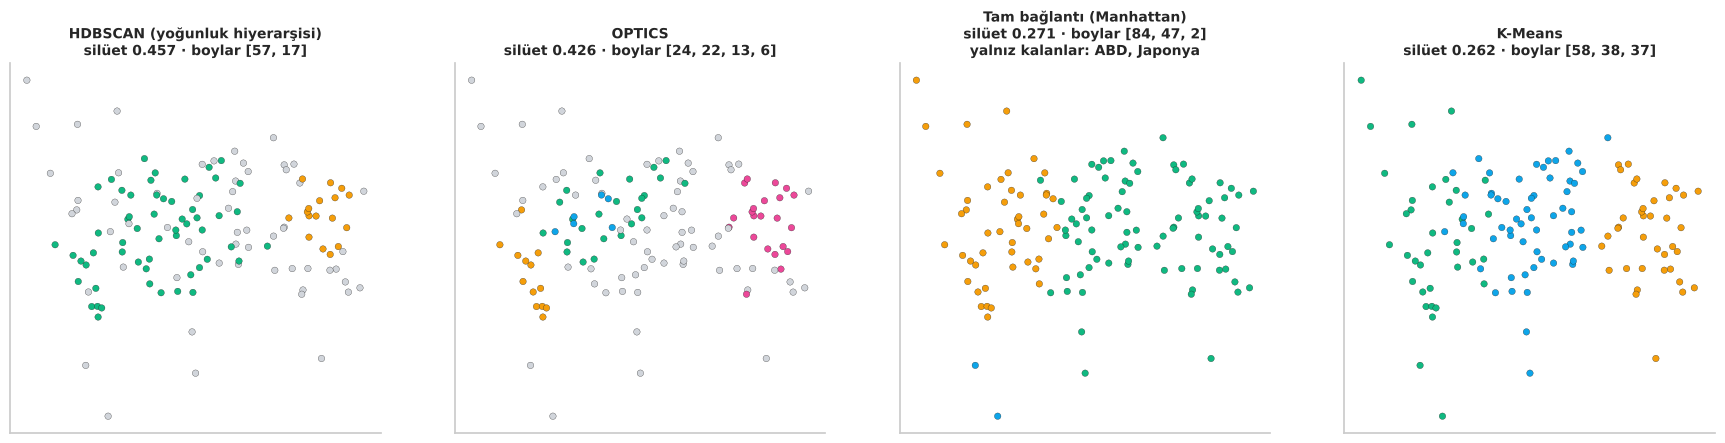

In [19]:
tuzak = [a for a in yaris.sort_values("Silüet", ascending=False).index if not yaris.loc[a, "Uygun"] and yaris.loc[a, "Segment"] >= 2][:3] + [lider]
fig, ax = plt.subplots(1, len(tuzak), figsize=(5.5 * len(tuzak), 4.8))
for a, ad in zip(ax, tuzak):
    et = ETIKET[ad]; boy = pd.Series(et[et >= 0]).value_counts().tolist()
    a.scatter(Htr[:, 0], Htr[:, 1], s=22, c=[KUME_RENK[e % 10] if e >= 0 else "#D1D5DB" for e in et], edgecolor="k", linewidth=.2)
    yalniz = [tr["Ülke"][i] for i in range(len(et)) if et[i] >= 0 and (et == et[i]).sum() <= 3]
    a.set_title(f"{ad}\nsilüet {yaris.loc[ad, 'Silüet']:.3f} · boylar {boy}" + (f"\nyalnız kalanlar: {', '.join(yalniz[:4])}" if yalniz else ""), fontsize=10)
    a.set_xticks([]); a.set_yticks([])
kaydet(fig, "09_siluet_tuzagi"); plt.show()

<table><tr><td>

<img src="assets/etiket_dikkat.svg" height="34" alt="Dikkat">

Tablonun en yüksek silüetleri **HDBSCAN (0,46)** ve **OPTICS (0,43)**'te; ama ikisi de ülkelerin **yarısına yakınını** (%44 ve %51) "gürültü" diye **hiçbir segmente koymuyor**: 133 ülkenin 59'u için "bilmiyorum" diyen bir model kuruluşa liste veremez. Hemen ardından gelen **ortalama bağlantı (UPGMA)** ve **Manhattan'lı tam bağlantı** (0,27) ise yalnızca **2 ülkelik** bir "segment" üretiyor; **tek bağlantı** 131 ülkeyi tek dev segmente koyup iki ülkeyi yalnız bırakıyor (kavram notebook'undaki zincirleme etkisi). Yalnız kalan ülkeler, aşırı ticaret ya da enflasyon değerine sahip **uç ülkeler**. Silüet, birkaç uç noktayı ayırıp gerisini tek kütle bırakmayı "ödüllendirebilir". **Kural 2'deki en küçük segment ve gürültü şartı** bu tuzağı yakalıyor: 27 algoritmanın 9'u bu yüzden elendi, 6'sı **SciPy/scikit-learn'ün klasik bağlantılarıdır**. Ders: hiyerarşik kümelemede bağlantı seçimi, uç değerlere karşı **dayanıklılık** seçimidir.

</td></tr></table>

<a id="p9"></a>

<p align="center">
  <img src="assets/proje_09.svg" width="100%" alt="Bölüm 9: Kararlılık">
</p>

### 📊 9.1 · İlk 6 Uygun Algoritma: 40 Bootstrap ve 10 Tohum

Yarıştaki kararlılık 10 bootstrap ile ölçüldü; ilk altı uygun algoritmayı **40 bootstrap** ile yeniden ölçüp dağılımına bakıyoruz. Ayrıca **tohum duyarlılığı**: aynı veriyle yalnızca `random_state`'i değiştirince segmentler ne kadar değişiyor? (Hiyerarşik algoritmalar **deterministiktir**: tohumdan etkilenmezler.)

,Ort. ARI,Alt %5,Medyan,En kötü,Tohum ARI,Tür
Algoritma,,,,,,
K-Means,0.911,0.770,0.928,0.708,0.995,rastgele başlangıçlı
Spektral (komşuluk grafı),0.812,0.639,0.826,0.500,0.995,rastgele başlangıçlı
K-Medoids,0.802,0.564,0.842,0.495,0.818,rastgele başlangıçlı
Konsensüs hiyerarşik,0.763,0.514,0.775,0.305,0.870,rastgele başlangıçlı
GMM (tam kovaryans),0.628,0.277,0.642,0.248,0.679,rastgele başlangıçlı
Ward,0.659,0.353,0.704,0.230,NaN,deterministik


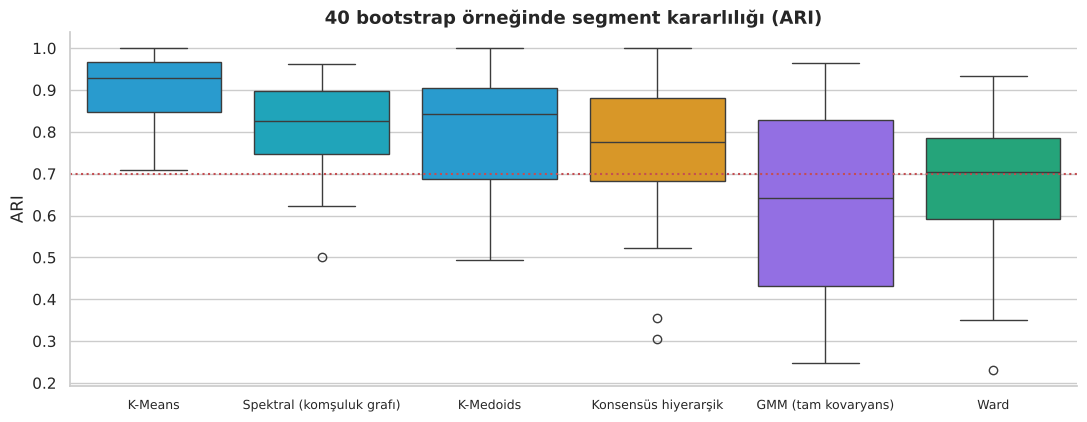

In [20]:
ilk6 = [a for a in yaris.index if yaris.loc[a, "Uygun"]][:6]
def bootstrap_tek(ad, model, ref, tohum):
    i = np.unique(np.random.default_rng(tohum).choice(len(Ztr), len(Ztr)))
    return ad, adjusted_rand_score(ref[i], np.asarray(clone(model).fit_predict(Ztr[i])))
bs40 = pd.DataFrame(Parallel(n_jobs=N_JOBS)(delayed(bootstrap_tek)(a, YARISCI[a][1], ETIKET[a], 100 + b) for a in ilk6 for b in range(40)), columns=["Algoritma", "ARI"])

def tohum_ari(ad):
    m = YARISCI[ad][1]; p = m.get_params()
    if not any(k == "random_state" or k.endswith("__random_state") for k in p): return ad, np.nan, "deterministik"
    et = [np.asarray(clone(m).set_params(random_state=t).fit_predict(Ztr)) for t in range(10)]
    return ad, np.mean([adjusted_rand_score(et[i], et[j]) for i in range(10) for j in range(i + 1, 10)]), "rastgele başlangıçlı"
tohum = pd.DataFrame([tohum_ari(a) for a in ilk6], columns=["Algoritma", "Tohum ARI", "Tür"]).set_index("Algoritma")
kararlilik = bs40.groupby("Algoritma")["ARI"].describe(percentiles=[.05, .5])[["mean", "5%", "50%", "min"]].join(tohum).loc[ilk6]
kararlilik.columns = ["Ort. ARI", "Alt %5", "Medyan", "En kötü", "Tohum ARI", "Tür"]
display(kararlilik.round(3)); rapor_kaydet(kararlilik.round(4), "07_kararlilik")

fig, ax = plt.subplots(figsize=(13, 4.6))
sns.boxplot(data=bs40, x="Algoritma", y="ARI", order=ilk6, ax=ax, palette=[aile_renk[YARISCI[a][0]] for a in ilk6])
ax.axhline(.7, color="r", ls=":"); ax.set(title="40 bootstrap örneğinde segment kararlılığı (ARI)", xlabel=""); ax.tick_params(axis="x", labelsize=9)
kaydet(fig, "10_kararlilik_kutu"); plt.show()

### 🎞️ 9.2 · Konsensüs Matrisi Nasıl Oluşur? (Animasyon)

Ward ağacını ülkelerin %80'lik alt örneklerinde tekrar tekrar kuruyoruz. Her karede bir alt örnek daha ekleniyor ve **"iki ülke aynı segmente kaç kez düştü?"** oranı güncelleniyor. Ülkeler, tam veriyle bulunan Ward segmentlerine göre sıralı: **köşegendeki koyu kareler** ne kadar keskin ve dışarısı ne kadar açıksa, segmentler o kadar kararlıdır.

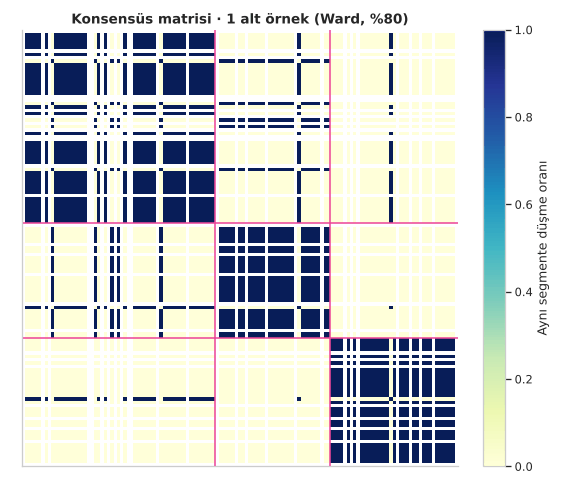

Segment içi ortalama birlikte-olma: 0.835 | segmentler arası: 0.112


In [21]:
ref_ward = AgglomerativeClustering(K).fit_predict(Ztr)
sira_idx = np.argsort(ref_ward, kind="stable")
rng = np.random.default_rng(2026); n = len(Ztr)
ayni, birlikte, kareler = np.zeros((n, n)), np.zeros((n, n)), []
for b in range(1, 61):
    i = np.sort(rng.choice(n, int(.8 * n), replace=False)); et = AgglomerativeClustering(K).fit_predict(Ztr[i])
    birlikte[np.ix_(i, i)] += 1; ayni[np.ix_(i, i)] += et[:, None] == et[None, :]
    if b in (1, 2, 3, 5, 8, 12, 20, 30, 45, 60):
        kareler.append((b, np.divide(ayni, birlikte, out=np.full_like(ayni, np.nan), where=birlikte > 0)[np.ix_(sira_idx, sira_idx)]))
def kare(i, fig):
    b, C = kareler[min(i, len(kareler) - 1)]
    a = fig.add_subplot(1, 1, 1); im = a.imshow(C, cmap="YlGnBu", vmin=0, vmax=1)
    sinir = np.cumsum(np.bincount(ref_ward))[:-1]
    for s in sinir: a.axhline(s - .5, color=RENK["pembe"], lw=1.5); a.axvline(s - .5, color=RENK["pembe"], lw=1.5)
    a.set(title=f"Konsensüs matrisi · {b} alt örnek (Ward, %80)", xticks=[], yticks=[]); fig.colorbar(im, ax=a, fraction=.046, label="Aynı segmente düşme oranı")
gif_yap(kare, len(kareler) + 2, "11_konsensus_matrisi", boyut=(7.5, 6.5), fps=1.2)
C_son = kareler[-1][1]; et_s = ref_ward[sira_idx]
print(f"Segment içi ortalama birlikte-olma: {np.nanmean(C_son[et_s[:, None] == et_s[None, :]]):.3f} | segmentler arası: {np.nanmean(C_son[et_s[:, None] != et_s[None, :]]):.3f}")

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

40 bootstrap'ta en kararlı yöntem **K-Means** (ortalama ARI 0,91, en kötü örnekte bile 0,71). **Ward**'ın ortalaması 0,66'da kalıyor ve en kötü örnekte 0,23'e düşüyor: Ward **deterministiktir** (aynı veriyle her seferinde aynı ağaç) ama **kararlı değildir**: birkaç ülke çıkarılınca ağacın üst dalları yer değiştirebiliyor. Bu iki kavramı karıştırmamak gerekir. **Konsensüs hiyerarşik** tam bu zayıflığa çare olarak tasarlandı ve Ward'ı geçiyor (0,76). Konsensüs matrisi animasyonu da aynı şeyi söylüyor: 60 alt örnekten sonra aynı segmentteki ülkeler ortalama **%84** oranında birlikte kalırken farklı segmentlerdekiler yalnızca **%11** oranında aynı segmente düşüyor; köşegendeki üç blok net, ama blok kenarlarındaki **soluk satırlar** iki segment arasında gidip gelen sınır ülkeleridir.

</td></tr></table>

<a id="p10"></a>

<p align="center">
  <img src="assets/proje_10.svg" width="100%" alt="Bölüm 10: Ayar ve final">
</p>

### 🛠️ 10.1 · Düğmeleri Çevirmek (Ölçüm Uzayı Sabit)

Yarışın üst sıralarındaki aileleri seçip düğmelerini tarıyoruz. **Önemli kural:** ayar sırasında **ölçüm uzayı değişmez** (aynı 9 gösterge, aynı log + standart); yalnızca algoritmanın kendi düğmeleri değişir. Aksi hâlde farklı uzaylardaki silüetleri karşılaştırmış oluruz.

| Aday | Taranan düğmeler | Sayı |
|:--|:--|:-:|
| 🌳 Birleştiren hiyerarşik | bağlantı (Ward, tam, ortalama) × mesafe (Öklid, Manhattan, kosinüs) × komşuluk kısıtı (yok, 5, 10 komşu) | 21 |
| 🧺 Konsensüs hiyerarşik | taban (Ward, K-Means) × son bağlantı (ortalama, tam) × alt örnek sayısı (20, 50) | 8 |
| 🪓 Bisecting K-Means | bölme stratejisi (en büyük küme, en büyük SSE) × n_init (5, 10, 20) | 6 |
| 🎯 K-Means | başlangıç (k-means++, rastgele) × n_init (1, 10, 30) × algoritma (lloyd, elkan) | 12 |
| 🎯 K-Medoids | n_init (5, 10, 30) | 3 |
| 🔔 GMM | kovaryans (tam, bağlı, köşegen, küresel) × düzenlileştirme (1e-6, 1e-3, 1e-1) | 12 |
| 🕸️ Spektral | komşu sayısı (5, 8, 10, 15) | 4 |

In [22]:
aday = []
for (bag, mes), kom in itertools.product([("ward", "euclidean"), ("complete", "euclidean"), ("complete", "manhattan"), ("complete", "cosine"),
                                          ("average", "euclidean"), ("average", "manhattan"), ("average", "cosine")], [None, 5, 10]):
    baglayici = partial(kneighbors_graph, n_neighbors=kom, include_self=False) if kom else None
    aday.append(("Birleştiren hiyerarşik", f"{bag}, {mes}, komşu={kom or 'yok'}", AgglomerativeClustering(K, linkage=bag, metric=mes, connectivity=baglayici)))
for taban, bag, B in itertools.product(["ward", "kmeans"], ["average", "complete"], [20, 50]):
    aday.append(("Konsensüs hiyerarşik", f"taban={taban}, son={bag}, B={B}", KonsensusHiyerarsik(K, B=B, taban=taban, baglanti=bag, random_state=RS)))
for strat, ni in itertools.product(["biggest_inertia", "largest_cluster"], [5, 10, 20]):
    aday.append(("Bisecting K-Means", f"{strat}, n_init={ni}", BisectingKMeans(K, bisecting_strategy=strat, n_init=ni, random_state=RS)))
for ini, ni, alg in itertools.product(["k-means++", "random"], [1, 10, 30], ["lloyd", "elkan"]):
    aday.append(("K-Means", f"init={ini}, n_init={ni}, {alg}", KMeans(K, init=ini, n_init=ni, algorithm=alg, random_state=RS)))
for ni in [5, 10, 30]:
    aday.append(("K-Medoids", f"n_init={ni}", KMedoids(K, n_init=ni, random_state=RS)))
for cov, reg in itertools.product(["full", "tied", "diag", "spherical"], [1e-6, 1e-3, 1e-1]):
    aday.append(("GMM", f"{cov}, reg={reg:g}", GaussianMixture(K, covariance_type=cov, reg_covar=reg, n_init=5, random_state=RS)))
for nn in [5, 8, 10, 15]:
    aday.append(("Spektral", f"n_neighbors={nn}", SpectralClustering(K, affinity="nearest_neighbors", n_neighbors=nn, random_state=RS)))

def ayar_kos(aile, ayar, m):
    et = np.asarray(clone(m).fit_predict(Ztr)); o = ic_olcut(Ztr, et)
    return {"Aile": aile, "Ayar": ayar, "Silüet": o["sil"], "Davies-Bouldin": o["db"], "Calinski-Harabasz": o["ch"],
            "Kararlılık (ARI)": bootstrap_ari(m, Ztr, 15, 11), "En küçük %": np.bincount(et[et >= 0]).min() / len(et) * 100, "Segment": len(np.unique(et))}
ayar = pd.DataFrame(Parallel(n_jobs=N_JOBS)(delayed(ayar_kos)(a, s, m) for a, s, m in aday))
ayar["Uygun"] = (ayar["Segment"] == K) & (ayar["En küçük %"] >= 5)
u = ayar[ayar["Uygun"]]
ayar.loc[u.index, "Bileşik sıra"] = pd.concat([u["Silüet"].rank(ascending=False), u["Davies-Bouldin"].rank(),
                                               u["Calinski-Harabasz"].rank(ascending=False), u["Kararlılık (ARI)"].rank(ascending=False)], axis=1).mean(1)
rapor_kaydet(ayar.round(4), "08_ayar_tum")
en_iyi_ayar = ayar[ayar["Uygun"]].sort_values("Bileşik sıra").groupby("Aile").head(1).set_index("Aile")
varsayilan = {"Birleştiren hiyerarşik": "Ward", "Konsensüs hiyerarşik": "Konsensüs hiyerarşik", "Bisecting K-Means": "Bisecting K-Means",
              "K-Means": "K-Means", "K-Medoids": "K-Medoids", "GMM": "GMM (tam kovaryans)", "Spektral": "Spektral (komşuluk grafı)"}
en_iyi_ayar["Varsayılan silüet"] = [yaris.loc[varsayilan[a], "Silüet"] for a in en_iyi_ayar.index]
en_iyi_ayar["Varsayılan kararlılık"] = [yaris.loc[varsayilan[a], "Kararlılık (ARI)"] for a in en_iyi_ayar.index]
print(f"{len(aday)} ayar denendi; {int(ayar['Uygun'].sum())} tanesi uygun.")
display(en_iyi_ayar[["Ayar", "Silüet", "Varsayılan silüet", "Kararlılık (ARI)", "Varsayılan kararlılık", "Davies-Bouldin", "Calinski-Harabasz", "En küçük %"]].round(3))
rapor_kaydet(en_iyi_ayar.round(4), "09_ayar_kazanci")

66 ayar denendi; 52 tanesi uygun.


,Ayar,Silüet,Varsayılan silüet,Kararlılık (ARI),Varsayılan kararlılık,Davies-Bouldin,Calinski-Harabasz,En küçük %
Aile,,,,,,,,
K-Means,"init=k-means++, n_init=10, elkan",0.262,0.262,0.922,0.923,1.314,69.923,27.820
Konsensüs hiyerarşik,"taban=kmeans, son=average, B=50",0.262,0.251,0.906,0.804,1.314,69.923,27.820
Spektral,n_neighbors=15,0.264,0.260,0.880,0.828,1.282,69.228,25.564
K-Medoids,n_init=10,0.264,0.264,0.821,0.761,1.292,69.037,24.060
GMM,"spherical, reg=1e-06",0.262,0.254,0.881,0.603,1.316,69.896,26.316
Birleştiren hiyerarşik,"ward, euclidean, komşu=5",0.249,0.249,0.712,0.811,1.332,66.364,26.316
Bisecting K-Means,"biggest_inertia, n_init=20",0.231,0.231,0.822,0.911,1.409,64.757,25.564


### 🏆 10.2 · Final Seçimi (Kural 3)

Her ailenin en iyi ayarını **yeni (taze) 30 bootstrap örneğiyle** bir kez daha ölçüp kural 3'ü uyguluyoruz: bileşik sırası en iyi olan; lider hiyerarşik değilse ve en iyi hiyerarşik aday silüette ≤ 0,02 **ve** kararlılıkta ≤ 0,05 geride ise **hiyerarşik** olan.

In [23]:
HIYERARSIK_AILELER = {"Birleştiren hiyerarşik", "Konsensüs hiyerarşik", "Bisecting K-Means"}
modeller_final = {a: [m for a_, s, m in aday if a_ == a and s == r["Ayar"]][0] for a, r in en_iyi_ayar.iterrows()}
def taze(a, m):
    ref = np.asarray(clone(m).fit_predict(Ztr)); s = []
    for b in range(30):
        i = np.unique(np.random.default_rng(9000 + b).choice(len(Ztr), len(Ztr)))
        s.append(adjusted_rand_score(ref[i], np.asarray(clone(m).fit_predict(Ztr[i]))))
    return a, float(np.mean(s))
final = en_iyi_ayar[["Ayar", "Silüet", "Davies-Bouldin", "Calinski-Harabasz"]].copy()
final["Taze kararlılık (30)"] = pd.Series(dict(Parallel(n_jobs=N_JOBS)(delayed(taze)(a, m) for a, m in modeller_final.items())))
final["Hiyerarşik mi?"] = [a in HIYERARSIK_AILELER for a in final.index]
final["Bileşik sıra"] = pd.concat([final["Silüet"].rank(ascending=False), final["Davies-Bouldin"].rank(),
                                   final["Calinski-Harabasz"].rank(ascending=False), final["Taze kararlılık (30)"].rank(ascending=False)], axis=1).mean(1)
final = final.sort_values("Bileşik sıra")
lider_aile = final.index[0]; secim, gerekce = lider_aile, "bileşik sırada lider"
if not final.loc[lider_aile, "Hiyerarşik mi?"]:
    h = final[final["Hiyerarşik mi?"]].index[0]
    fs, fk = final.loc[lider_aile, "Silüet"] - final.loc[h, "Silüet"], final.loc[lider_aile, "Taze kararlılık (30)"] - final.loc[h, "Taze kararlılık (30)"]
    if fs <= 0.02 and fk <= 0.05:
        secim, gerekce = h, f"lider {lider_aile} hiyerarşik değil; en iyi hiyerarşik aday {h} silüette {fs:+.3f}, kararlılıkta {fk:+.3f} geride (eşikler içinde)"
    else:
        gerekce = f"lider hiyerarşik değil ve en iyi hiyerarşik aday {h} eşiklerin dışında (silüet farkı {fs:.3f}, kararlılık farkı {fk:.3f})"
FINAL_AD = f"{secim} ({final.loc[secim, 'Ayar']})"; FINAL_KUMELEYICI = modeller_final[secim]
display(final.round(3)); rapor_kaydet(final.round(4), "10_final_adaylar")
display(Markdown(f"**Kural 3 kararı:** **{FINAL_AD}** — {gerekce}."))
et_final = np.asarray(clone(FINAL_KUMELEYICI).fit_predict(Ztr))
print("Final segmentlerin diğer adaylarla uyumu (ARI):", {a: round(adjusted_rand_score(et_final, np.asarray(clone(m).fit_predict(Ztr))), 3) for a, m in modeller_final.items()})
print("Varsayılan Ward ile uyum (ARI):", round(adjusted_rand_score(et_final, ETIKET["Ward"]), 3))

,Ayar,Silüet,Davies-Bouldin,Calinski-Harabasz,Taze kararlılık (30),Hiyerarşik mi?,Bileşik sıra
Aile,,,,,,,
K-Means,"init=k-means++, n_init=10, elkan",0.262,1.314,69.923,0.903,False,2.375
Konsensüs hiyerarşik,"taban=kmeans, son=average, B=50",0.262,1.314,69.923,0.900,True,2.625
Spektral,n_neighbors=15,0.264,1.282,69.228,0.872,False,2.750
K-Medoids,n_init=10,0.264,1.292,69.037,0.777,False,3.750
GMM,"spherical, reg=1e-06",0.262,1.316,69.896,0.877,False,4.250
Bisecting K-Means,"biggest_inertia, n_init=20",0.231,1.409,64.757,0.885,True,6.000
Birleştiren hiyerarşik,"ward, euclidean, komşu=5",0.249,1.332,66.364,0.684,True,6.250


**Kural 3 kararı:** **Konsensüs hiyerarşik (taban=kmeans, son=average, B=50)** — lider K-Means hiyerarşik değil; en iyi hiyerarşik aday Konsensüs hiyerarşik silüette +0.000, kararlılıkta +0.003 geride (eşikler içinde).

Final segmentlerin diğer adaylarla uyumu (ARI): {'K-Means': 1.0, 'Konsensüs hiyerarşik': 1.0, 'Spektral': 0.883, 'K-Medoids': 0.888, 'GMM': 0.907, 'Birleştiren hiyerarşik': 0.84, 'Bisecting K-Means': 0.55}
Varsayılan Ward ile uyum (ARI): 0.84


<table><tr><td>

<img src="assets/etiket_not.svg" height="34" alt="Not">

Kural 3'ü harfiyen uyguladık: bileşik sırada lider **K-Means**; en iyi hiyerarşik aday **konsensüs hiyerarşik** (taban K-Means, ortalama bağlantı, 50 alt örnek) silüette **0,000**, taze kararlılıkta yalnızca **0,003** geride olduğu için eşiklerin içinde kaldı ve **final model oldu**. Dürüst not: bu ayarla konsensüs ağacı, K-Means ile **birebir aynı** segmentleri veriyor (ARI 1,00). Yani kural 3 segmentleri değil, **açıklama biçimini** değiştirdi: segmentler 50 K-Means oylamasının **ortak kararına** dayanıyor ve bu karar bir **ağaç** olarak okunabiliyor. Ayar en çok GMM'ye yaradı (kararlılık 0,60 → 0,88, küresel kovaryansla: yani K-Means'e yaklaşarak); varsayılan Ward ile final arasındaki uyum ARI 0,84: ülkelerin büyük çoğunluğu iki yöntemde de aynı ailede.

</td></tr></table>

<a id="p11"></a>

<p align="center">
  <img src="assets/proje_11.svg" width="100%" alt="Bölüm 11: Segment kimliği">
</p>

### 🧭 11.1 · Final Boru Hattı ve Segmentlerin Kimliği

Final boru hattı = **ön işleme + seçilen kümeleyici + `AgacAtayici`**, tüm eğitim ülkeleriyle **bir kez** kurulur. `AgacAtayici`, her segmentin merkezini saklar ve yeni gelen ülkeyi **en yakın segment merkezine** atar (hiyerarşik kümelemenin `predict()` eksikliğini kapatır). Sonra her segmentin **gerçek birimlerdeki medyanlarına** bakıp **iş diliyle** ad veriyoruz. Adlar, yalnızca **eğitim profillerine** göre ve **ortanca çocuk ölümü sırasına** göre verilir.

In [24]:
FINAL = Pipeline([("on", on_isleme()), ("kume", AgacAtayici(clone(FINAL_KUMELEYICI)))]).fit(Xtr)
seg_tr = FINAL.named_steps["kume"].labels_
Ztr_f = FINAL.named_steps["on"].transform(Xtr).to_numpy()

# Segmentleri ortanca çocuk ölümüne göre sırala → isim ver
sira = list(tr.groupby(seg_tr)["Çocuk ölümü"].median().sort_values(ascending=False).index)
AD_HAVUZU = {2: ["🆘 Öncelikli Destek", "🏙️ Gelişmiş"], 3: ["🆘 Öncelikli Destek", "🌱 Gelişmekte Olan", "🏙️ Gelişmiş"],
             4: ["🆘 Öncelikli Destek", "🌱 Alt-Orta Gelirli", "🌤️ Üst-Orta Gelirli", "🏙️ Gelişmiş"],
             5: ["🆘 Öncelikli Destek", "🌱 Alt-Orta Gelirli", "🌤️ Üst-Orta Gelirli", "🏢 Yüksek Gelirli", "🏙️ En Gelişmiş"]}
SEGMENT_AD = {s: AD_HAVUZU.get(K, [f"Segment {j + 1}" for j in range(K)])[j] for j, s in enumerate(sira)}
SEG_KISA = {s: SEGMENT_AD[s].split(" ", 1)[1] for s in sira}
PALET_SEG = {2: ["#DC2626", "#10B981"], 3: ["#DC2626", "#F59E0B", "#10B981"], 4: ["#DC2626", "#F97316", "#0EA5E9", "#10B981"]}
SEG_RENK = dict(zip(sira, PALET_SEG.get(K, [to_hex(c) for c in plt.cm.RdYlGn(np.linspace(.04, .96, K))])))   # kırmızı = öncelikli
ONCELIKLI = sira[0]

profil = tr.groupby(seg_tr)[OZELLIKLER].median().loc[sira]
profil.insert(0, "Ülke sayısı", pd.Series(seg_tr).value_counts().loc[sira].to_numpy())
profil.insert(1, "Pay %", profil["Ülke sayısı"] / len(tr) * 100)
profil.index = [SEGMENT_AD[s] for s in sira]
display(profil.round(1)); rapor_kaydet(profil.round(2), "11_segment_profili")
for s in sira:
    print(f"{SEGMENT_AD[s]:<24} ({(seg_tr == s).sum():>2}): " + ", ".join(tr["Ülke"][seg_tr == s].tolist()[:14]) + (" …" if (seg_tr == s).sum() > 14 else ""))

,Ülke sayısı,Pay %,Çocuk ölümü,İhracat,Sağlık harcaması,İthalat,Gelir,Enflasyon,Yaşam beklentisi,Doğurganlık,Kişi başı GSYH
🆘 Öncelikli Destek,38,28.6,90.4,22.2,5.5,36.8,1835.0,8.9,59.8,5.2,723.0
🌱 Gelişmekte Olan,58,43.6,19.6,46.7,5.5,46.6,10750.0,7.9,71.8,2.4,5135.0
🏙️ Gelişmiş,37,27.8,4.5,46.2,9.4,47.9,28700.0,1.2,80.0,1.6,23400.0


🆘 Öncelikli Destek       (38): Nijer, Sudan, Burkina Faso, Pakistan, Haiti, Madagaskar, Uganda, Tacikistan, Eritre, Bangladeş, Moritanya, Sierra Leone, Togo, Lesotho …
🌱 Gelişmekte Olan        (58): Tonga, Fiji, Güney Afrika, Surinam, Ukrayna, Kırgızistan, Türkiye, Türkmenistan, Irak, Paraguay, Guyana, Guatemala, Belize, Butan …
🏙️ Gelişmiş              (37): Lübnan, İtalya, Danimarka, İsrail, Almanya, Litvanya, Slovakya, Sırbistan, Bosna-Hersek, İsviçre, Letonya, İzlanda, Karadağ, Portekiz …


,Doğru mu?
Öncelikli: en yüksek çocuk ölümü,True
Öncelikli: en düşük kişi başı GSYH,True
Öncelikli: en düşük yaşam beklentisi,True
Gelişmiş: en yüksek gelir,True
Gelişmiş: en yüksek yaşam beklentisi,True
Sıra: kişi başı GSYH tekdüze artıyor,True


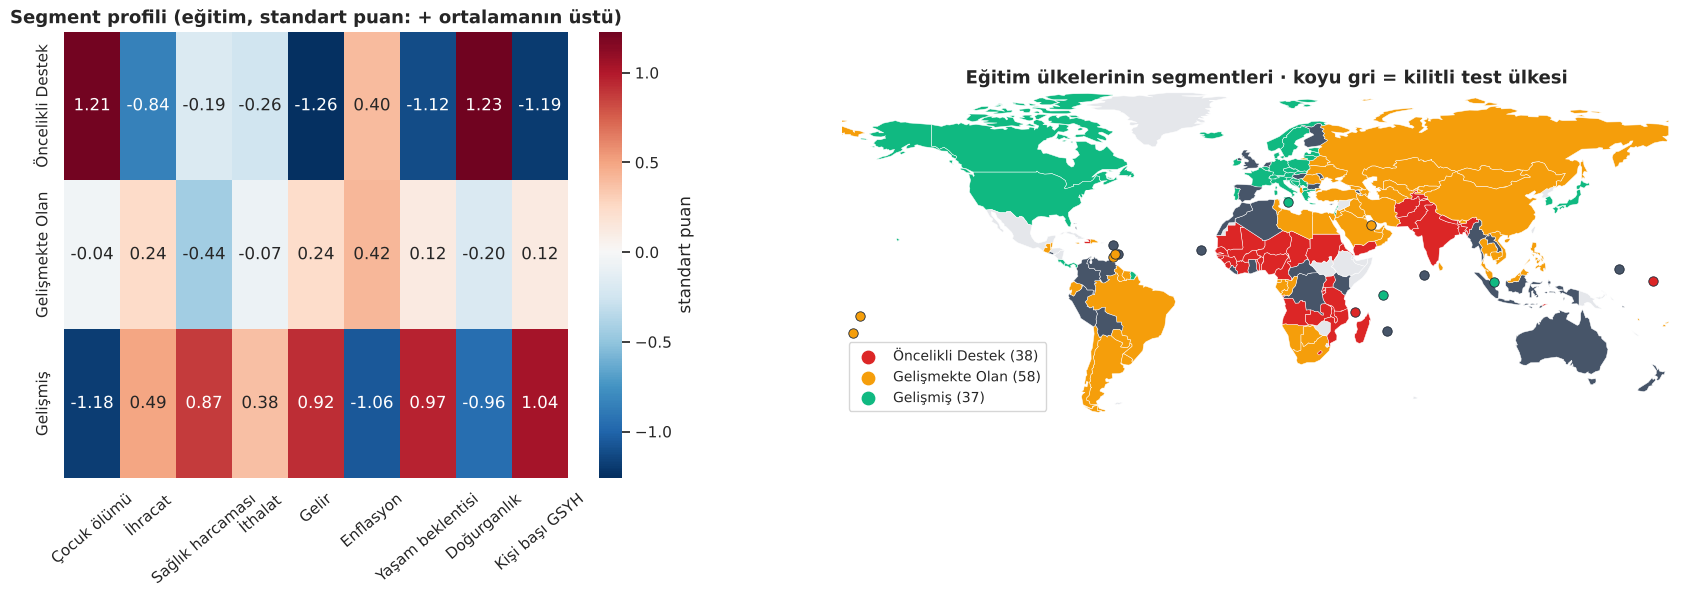

In [25]:
# Ad kuralının profile uyduğunu otomatik kontrol et (yanlış etiketlemeye karşı sigorta)
p = profil
kontrol = {"Öncelikli: en yüksek çocuk ölümü": p["Çocuk ölümü"].idxmax() == p.index[0],
           "Öncelikli: en düşük kişi başı GSYH": p["Kişi başı GSYH"].idxmin() == p.index[0],
           "Öncelikli: en düşük yaşam beklentisi": p["Yaşam beklentisi"].idxmin() == p.index[0],
           "Gelişmiş: en yüksek gelir": p["Gelir"].idxmax() == p.index[-1],
           "Gelişmiş: en yüksek yaşam beklentisi": p["Yaşam beklentisi"].idxmax() == p.index[-1],
           "Sıra: kişi başı GSYH tekdüze artıyor": bool(p["Kişi başı GSYH"].is_monotonic_increasing)}
display(pd.Series(kontrol, name="Doğru mu?").to_frame())

fig, ax = plt.subplots(1, 2, figsize=(21, 5.8), gridspec_kw={"width_ratios": [1, 1.35]})
z_prof = pd.DataFrame(Ztr_f, columns=SUTUN)[OZELLIKLER].groupby(seg_tr).mean().loc[sira]; z_prof.index = [SEG_KISA[s] for s in sira]   # grafiklerde emojisiz ad
sns.heatmap(z_prof, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax[0], cbar_kws={"label": "standart puan"})
ax[0].set_title("Segment profili (eğitim, standart puan: + ortalamanın üstü)"); ax[0].tick_params(axis="x", rotation=40)
harita = {u: SEG_RENK[s] for u, s in zip(tr["Ülke (EN)"], seg_tr)}; harita.update({u: "#475569" for u in te["Ülke (EN)"]})
dunya_haritasi(ax[1], harita, baslik="Eğitim ülkelerinin segmentleri · koyu gri = kilitli test ülkesi")
for s in sira: ax[1].scatter([], [], color=SEG_RENK[s], s=80, label=f"{SEG_KISA[s]} ({(seg_tr == s).sum()})")
ax[1].legend(loc="lower left", fontsize=10, frameon=True)
kaydet(fig, "12_segment_kimligi"); plt.show()

### 🌳 11.2 · 133 Eğitim Ülkesinin Adlı Soy Ağacı

Final segmentlerin renkleriyle boyanmış tam dendrogram (Ward ağacı, Öklid). Yaprak adları, ait oldukları **final segmentin** renginde yazılıdır: bir dalın içinde farklı renkte ad görmek, final modelin o ülkeyi Ward'dan **farklı** bir aileye koyduğu anlamına gelir.

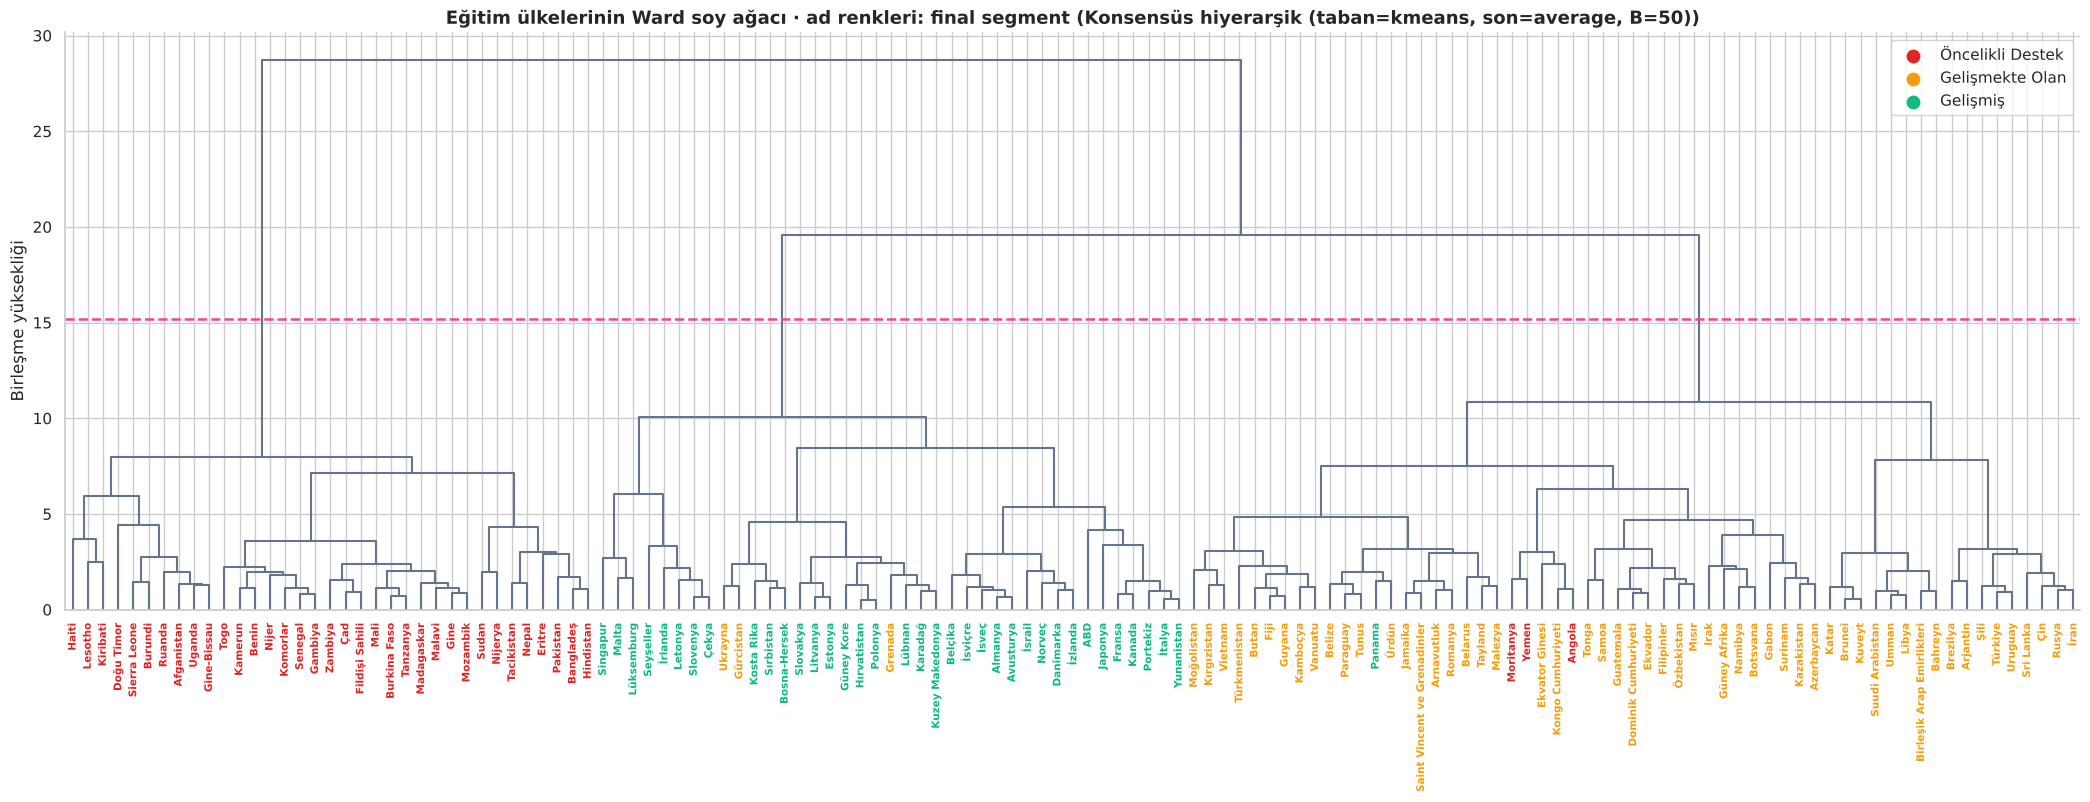

In [26]:
fig, ax = plt.subplots(figsize=(26, 7.5))
d_tam = dendrogram(Z_ward, labels=tr["Ülke"].to_numpy(), ax=ax, leaf_font_size=7.5, color_threshold=0, above_threshold_color="#64748B")
ulke_seg = dict(zip(tr["Ülke"], seg_tr))
for etiket in ax.get_xticklabels():
    etiket.set_color(SEG_RENK[ulke_seg[etiket.get_text()]]); etiket.set_fontweight("bold")
ax.axhline((yuk[-K] + yuk[-K + 1]) / 2, color=RENK["pembe"], ls="--", lw=1.8)
for s in sira: ax.scatter([], [], color=SEG_RENK[s], s=80, label=SEG_KISA[s])
ax.legend(loc="upper right", fontsize=11); ax.set(title=f"Eğitim ülkelerinin Ward soy ağacı · ad renkleri: final segment ({FINAL_AD})", ylabel="Birleşme yüksekliği")
kaydet(fig, "13_adli_soy_agaci"); plt.show()

### 🌳 11.3 · Vekil Karar Ağacı: Segmentleri Kurala Çevirmek

Yönetim kurulu "merkeze uzaklık" ile çalışmaz; **kural** ister. Segment etiketlerini **ham göstergelerden** tahmin eden sığ bir karar ağacı (derinlik 2) kuruyoruz. **Sadakat (fidelity)**: ağacın, kümeleyicinin verdiği segmenti ne sıklıkla doğru tahmin ettiği. Test sadakati 12. bölümde ölçülecek.

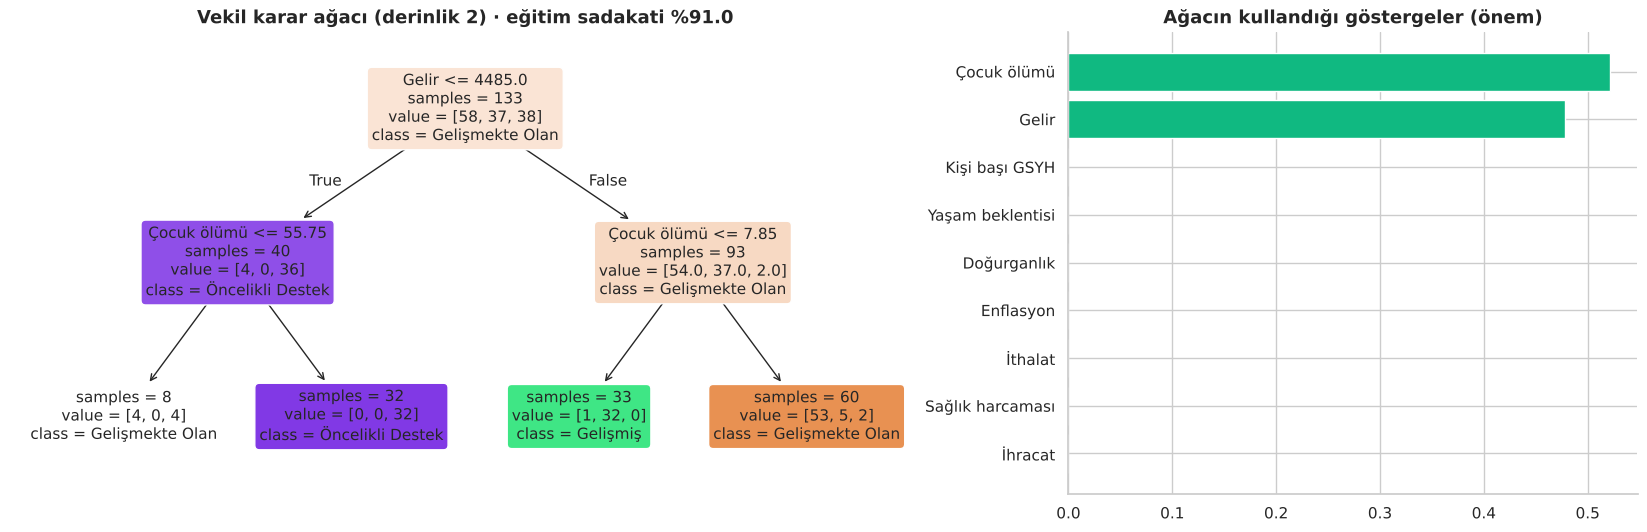

In [27]:
doldur = SimpleImputer(strategy="median").set_output(transform="pandas").fit(Xtr)
Xtr_d, Xte_d = doldur.transform(Xtr), doldur.transform(Xte)
agac = DecisionTreeClassifier(max_depth=2, min_samples_leaf=8, random_state=RS).fit(Xtr_d, seg_tr)
sadakat_tr = (agac.predict(Xtr_d) == seg_tr).mean()
fig, ax = plt.subplots(1, 2, figsize=(21, 6), gridspec_kw={"width_ratios": [1.6, 1]})
plot_tree(agac, feature_names=OZELLIKLER, class_names=[SEG_KISA[c] for c in agac.classes_], filled=True, rounded=True, fontsize=11, ax=ax[0], impurity=False)
ax[0].set_title(f"Vekil karar ağacı (derinlik 2) · eğitim sadakati %{sadakat_tr * 100:.1f}")
onem = pd.Series(agac.feature_importances_, index=OZELLIKLER).sort_values()
ax[1].barh(onem.index, onem, color=RENK["yesil"]); ax[1].set(title="Ağacın kullandığı göstergeler (önem)")
kaydet(fig, "14_vekil_agac"); plt.show()
rapor_kaydet(onem.sort_values(ascending=False).round(4).to_frame("Önem"), "12_vekil_agac_onem")

### 🎞️ 11.4 · Üç Boyutta Segmentler (Animasyon)

Haritanın ilk üç ekseninde segmentler dönerken: segmentlerin birbirine **değen ama karışmayan** bulutlar olduğuna dikkat edin.

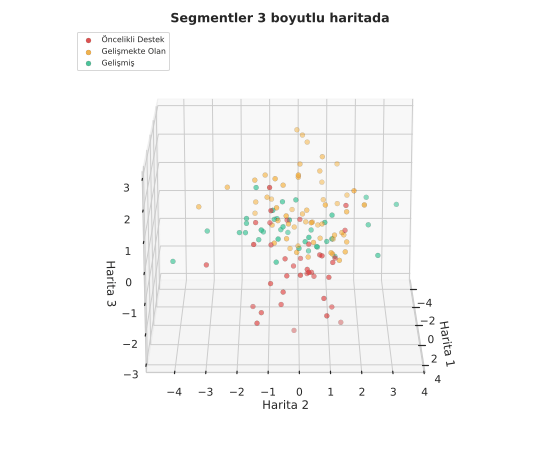

In [28]:
def kare(i, fig):
    ax = fig.add_subplot(1, 1, 1, projection="3d")
    for s in sira:
        m = seg_tr == s
        ax.scatter(Htr[m, 0], Htr[m, 1], Htr[m, 2], s=26, alpha=.8, color=SEG_RENK[s], edgecolor="k", linewidth=.2, label=SEG_KISA[s])
    ax.view_init(elev=18, azim=i * 12); ax.set_xlabel("Harita 1"); ax.set_ylabel("Harita 2"); ax.set_zlabel("Harita 3")
    ax.legend(loc="upper left", fontsize=8); ax.set_title("Segmentler 3 boyutlu haritada")
gif_yap(kare, 30, "15_segmentler_3b", boyut=(8, 6.5), fps=6, dpi=70)

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

Üç segment **net bir kalkınma merdiveni** oluşturuyor ve otomatik ad kontrollerinin altısı da doğru: **🆘 Öncelikli Destek** (38 eğitim ülkesi; ortanca çocuk ölümü **‰90**, kişi başı GSYH **723 $**, yaşam beklentisi **59,8**, doğurganlık **5,2**), **🌱 Gelişmekte Olan** (58; çocuk ölümü ‰20, GSYH 5.135 $) ve **🏙️ Gelişmiş** (37; çocuk ölümü ‰4,5, GSYH 23.400 $, en yüksek sağlık harcaması payı ve en düşük enflasyon). Vekil karar ağacı yalnızca **iki soruyla** (çocuk ölümü ve gelir) eğitim ülkelerinin **%91'ini** doğru segmente koyuyor: yönetim kuruluna anlatılabilecek kadar basit bir kural. Adlı soy ağacında renklerin büyük ölçüde dalları takip ettiği, ama **Gelişmekte Olan** ile komşu segmentlerin sınırında farklı renkte adların serpiştirildiği görülüyor: o ülkeler Ward'ın ağacı ile finalin konsensüsünün **anlaşamadığı** ülkelerdir.

</td></tr></table>

<a id="p12"></a>

<p align="center">
  <img src="assets/proje_12.svg" width="100%" alt="Bölüm 12: Test seti">
</p>

### 🏆 12.1 · Test Seti Açılıyor (Tek Sefer)

Final boru hattını kilitli 34 test ülkesine **bir kez** uyguluyoruz ve beş soruya bakıyoruz:

1. **Sıkılık:** test silüeti eğitime yakın mı?
2. **Boy:** segment payları eğitimdekiyle aynı mı? (Fisher/ki-kare testi)
3. **Yeniden keşif:** aynı algoritmayı testte **sıfırdan** kurunca, eğitimden atanan segmentleri yeniden buluyor mu? (ARI)
4. **Kural:** vekil karar ağacı test ülkelerinde de sadık mı?
5. **Profil:** segmentlerin test ülkelerindeki medyanları eğitimdekine benziyor mu?

In [29]:
seg_te = FINAL.predict(Xte)
Zte_f = FINAL.named_steps["on"].transform(Xte).to_numpy()
sil_tr, sil_te = silhouette_score(Ztr_f, seg_tr), silhouette_score(Zte_f, seg_te)
yeni = np.asarray(clone(FINAL_KUMELEYICI).fit_predict(Zte_f))
tab = pd.crosstab(np.r_[np.zeros(len(seg_tr)), np.ones(len(seg_te))], np.r_[seg_tr, seg_te])
p_ki = stats.chi2_contingency(tab)[1]
sadakat_te = (agac.predict(Xte_d) == seg_te).mean()
test_ozet = pd.DataFrame({"Eğitim": [sil_tr, davies_bouldin_score(Ztr_f, seg_tr), calinski_harabasz_score(Ztr_f, seg_tr), sadakat_tr, np.nan],
                          "Test": [sil_te, davies_bouldin_score(Zte_f, seg_te), calinski_harabasz_score(Zte_f, seg_te), sadakat_te, adjusted_rand_score(seg_te, yeni)]},
                         index=["Silüet ↑", "Davies-Bouldin ↓", "Calinski-Harabasz ↑", "Vekil ağaç sadakati ↑", "Yeniden keşif ARI ↑"])
paylar = pd.DataFrame({"Eğitim %": pd.Series(seg_tr).value_counts(normalize=True) * 100, "Test %": pd.Series(seg_te).value_counts(normalize=True) * 100}).loc[sira].fillna(0)
paylar.index = [SEGMENT_AD[s] for s in sira]
display(test_ozet.round(3)); display(paylar.round(1))
print(f"Segment payları eğitim ve testte aynı mı? ki-kare p = {p_ki:.3f}  (p > 0,05 → fark yok sayılır)")
rapor_kaydet(test_ozet.round(4), "13_test_olcutleri")

,Eğitim,Test
Silüet ↑,0.262,0.265
Davies-Bouldin ↓,1.314,1.278
Calinski-Harabasz ↑,69.923,18.374
Vekil ağaç sadakati ↑,0.910,0.765
Yeniden keşif ARI ↑,NaN,0.822


,Eğitim %,Test %
🆘 Öncelikli Destek,28.6,23.5
🌱 Gelişmekte Olan,43.6,38.2
🏙️ Gelişmiş,27.8,38.2


Segment payları eğitim ve testte aynı mı? ki-kare p = 0.493  (p > 0,05 → fark yok sayılır)


Eğitim medyanı                                \
Segment          🆘 Öncelikli Destek 🌱 Gelişmekte Olan 🏙️ Gelişmiş   
Gösterge                                                            
Doğurganlık                     5.2               2.4         1.6   
Enflasyon                       8.9               7.9         1.2   
Gelir                        1835.0           10750.0     28700.0   
Kişi başı GSYH                723.0            5135.0     23400.0   
Yaşam beklentisi               59.8              71.8        80.0   
Çocuk ölümü                    90.4              19.6         4.5   

                       Test medyanı                                
Segment          🆘 Öncelikli Destek 🌱 Gelişmekte Olan 🏙️ Gelişmiş  
Gösterge                                                           
Doğurganlık                     4.3               2.5         1.8  
Enflasyon                       6.1               7.0         1.1  
Gelir                        2130.0            7300.0     32300.0  
Kişi başı GSYH               1053.5            3220.0     30700.0  
Yaşam beklentisi               62.0              73.5        79.9  
Çocuk ölümü                    76.8              20.3         6.0

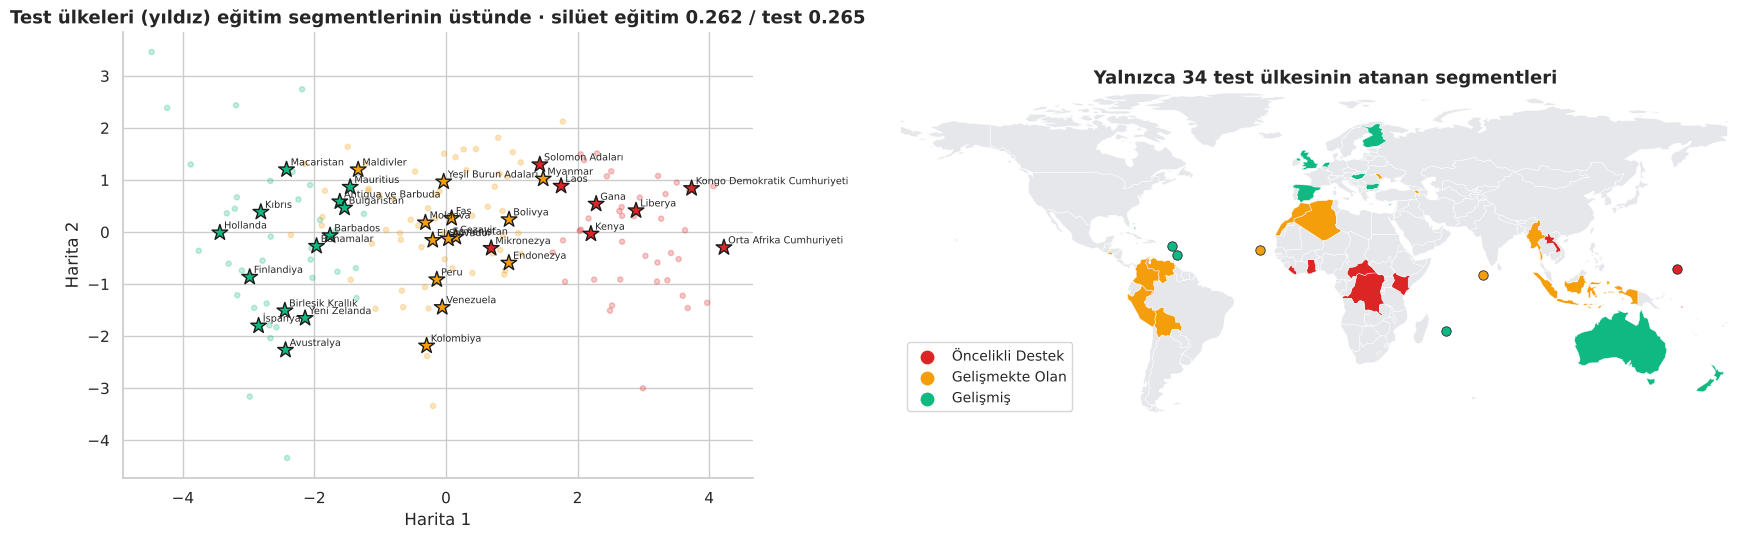

,Segment,Çocuk ölümü,Kişi başı GSYH,Yaşam beklentisi
Ülke,,,,
Solomon Adaları,🆘 Öncelikli Destek,28.1,1290,61.7
Mikronezya,🆘 Öncelikli Destek,40.0,2860,65.4
Orta Afrika Cumhuriyeti,🆘 Öncelikli Destek,149.0,446,47.5
Liberya,🆘 Öncelikli Destek,89.3,327,60.8
Kenya,🆘 Öncelikli Destek,62.2,967,62.8
Gana,🆘 Öncelikli Destek,74.7,1310,62.2
Laos,🆘 Öncelikli Destek,78.9,1140,63.8
Kongo Demokratik Cumhuriyeti,🆘 Öncelikli Destek,116.0,334,57.5
Kolombiya,🌱 Gelişmekte Olan,18.6,6250,76.4


In [30]:
kars = []
for s in sira:
    for g in ["Çocuk ölümü", "Gelir", "Yaşam beklentisi", "Doğurganlık", "Kişi başı GSYH", "Enflasyon"]:
        kars.append({"Segment": SEGMENT_AD[s], "Gösterge": g, "Eğitim medyanı": tr.loc[seg_tr == s, g].median(), "Test medyanı": te.loc[seg_te == s, g].median()})
kars = pd.DataFrame(kars).pivot(index="Gösterge", columns="Segment"); display(kars.round(1)); rapor_kaydet(kars.round(2), "14_egitim_test_profil")

fig, ax = plt.subplots(1, 2, figsize=(21, 5.8), gridspec_kw={"width_ratios": [1, 1.35]})
ax[0].scatter(Htr[:, 0], Htr[:, 1], s=14, c=[SEG_RENK[s] for s in seg_tr], alpha=.25)
ax[0].scatter(Hte[:, 0], Hte[:, 1], s=140, marker="*", c=[SEG_RENK[s] for s in seg_te], edgecolor="k")
for (x, y), a in zip(Hte[:, :2], te["Ülke"]): ax[0].annotate(a, (x, y), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax[0].set(title=f"Test ülkeleri (yıldız) eğitim segmentlerinin üstünde · silüet eğitim {sil_tr:.3f} / test {sil_te:.3f}", xlabel="Harita 1", ylabel="Harita 2")
harita = {u: SEG_RENK[s] for u, s in zip(te["Ülke (EN)"], seg_te)}
dunya_haritasi(ax[1], harita, baslik="Yalnızca 34 test ülkesinin atanan segmentleri")
for s in sira: ax[1].scatter([], [], color=SEG_RENK[s], s=80, label=SEG_KISA[s])
ax[1].legend(loc="lower left", fontsize=10)
kaydet(fig, "16_test_seti"); plt.show()
display(te.assign(Segment=[SEGMENT_AD[s] for s in seg_te])[["Ülke", "Segment", "Çocuk ölümü", "Kişi başı GSYH", "Yaşam beklentisi"]].sort_values("Segment").set_index("Ülke"))

<table><tr><td>

<img src="assets/etiket_sonuc.svg" height="34" alt="Sonuç">

Segmentler **yalnızca eğitim verisinin bir tesadüfü değil**: test silüeti (**0,265**) eğitimdekine (0,262) neredeyse eşit, segment payları istatistiksel olarak farklı değil (ki-kare p = 0,49) ve aynı algoritma 34 test ülkesinde **sıfırdan** kurulunca eğitimden atanan segmentleri **ARI 0,82** ile yeniden buluyor. Profiller de tutarlı (öncelikli segmentte çocuk ölümü ‰90 ↔ ‰77). Zayıf nokta: vekil ağacın sadakati testte **%76,5**'e düşüyor (eğitimde %91); iki soruluk kural, sınırdaki ülkelerde final modelle ayrışıyor. Bu yüzden kural, karar için değil **anlatım** için kullanılmalı; resmî atama final model ile yapılır. Calinski-Harabasz'ın testte düşük çıkması ölçütün örnek sayısına duyarlılığındandır (34 ↔ 133), kalite düşüşü değildir.

</td></tr></table>

<a id="p13"></a>

<p align="center">
  <img src="assets/proje_13.svg" width="100%" alt="Bölüm 13: Yardım kararı">
</p>

### 🇺🇳 13.1 · Dış Doğrulama: Segmentler BM'nin En Az Gelişmiş Ülkeler Listesiyle Örtüşüyor mu?

BM'nin **En Az Gelişmiş Ülkeler (EAGÜ)** listesi; kişi başı gelir, insan varlıkları (sağlık, eğitim) ve ekonomik kırılganlık ölçütlerine göre, **bizim modelimizden tamamen bağımsız** bir uzman sürecinde belirlenir. Bu liste kümelemede **hiç kullanılmadı**. Eğer "Öncelikli Destek" segmenti EAGÜ'leri yakalıyorsa, segmentasyonun gerçek bir şeyi yakaladığına dair **bağımsız bir kanıt** elde ederiz.

,Veri,Segment,Ülke,EAGÜ sayısı,EAGÜ oranı %,Alt %95,Üst %95
0,Eğitim,🆘 Öncelikli Destek,38,32,84.2,69.6,92.6
1,Eğitim,🌱 Gelişmekte Olan,58,3,5.2,1.8,14.1
2,Eğitim,🏙️ Gelişmiş,37,0,0.0,0.0,9.4
3,Test,🆘 Öncelikli Destek,8,5,62.5,30.6,86.3
4,Test,🌱 Gelişmekte Olan,13,1,7.7,1.4,33.3
5,Test,🏙️ Gelişmiş,13,0,0.0,0.0,22.8


,Öncelikli segmentte,EAGÜ,İkisi de,Kesinlik %,Duyarlılık %,ARI (2 grup)
Veri,,,,,,
Eğitim,38,35,32,84.21,91.43,0.74
Test,8,6,5,62.50,83.33,0.52
Tümü,46,41,37,80.43,90.24,0.70


EAGÜ olup öncelikli segmentte OLMAYANLAR: Butan (Gelişmekte Olan), Kamboçya (Gelişmekte Olan), Vanuatu (Gelişmekte Olan), Myanmar (Gelişmekte Olan)
Öncelikli segmentte olup EAGÜ OLMAYANLAR: Pakistan, Tacikistan, Nijerya, Kamerun, Hindistan, Fildişi Sahili, Kenya, Gana, Mikronezya


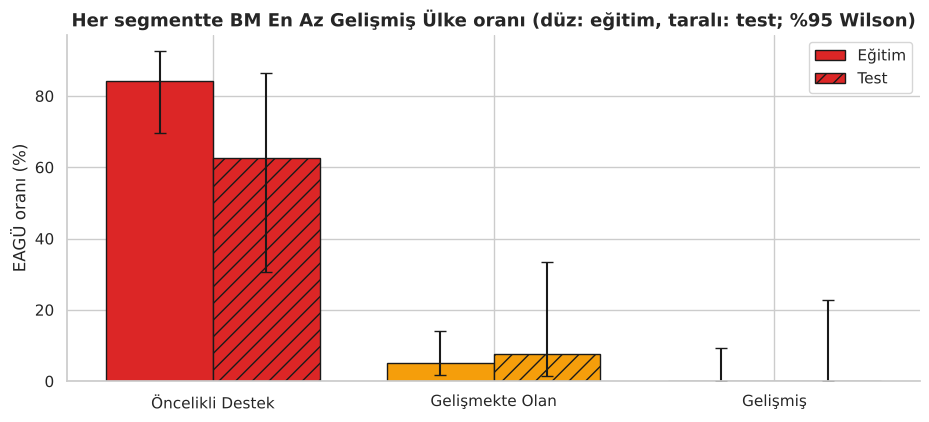

In [31]:
satir = []
for ad_, df_, seg_ in [("Eğitim", tr, seg_tr), ("Test", te, seg_te)]:
    for s in sira:
        m = seg_ == s; y = df_.loc[m, "EAGÜ (BM 2018)"]; lo, hi = wilson(y.sum(), len(y))
        satir.append({"Veri": ad_, "Segment": SEGMENT_AD[s], "Ülke": int(m.sum()), "EAGÜ sayısı": int(y.sum()), "EAGÜ oranı %": y.mean() * 100 if len(y) else np.nan,
                      "Alt %95": lo * 100, "Üst %95": hi * 100})
eagu = pd.DataFrame(satir); display(eagu.round(1)); rapor_kaydet(eagu.round(2), "15_eagu_segment")

tum = pd.concat([tr.assign(Segment=seg_tr, Veri="Eğitim"), te.assign(Segment=seg_te, Veri="Test")], ignore_index=True)
tum["Öncelikli mi?"] = tum["Segment"] == ONCELIKLI
dogruluk = []
for ad_, g in [("Eğitim", tum[tum["Veri"] == "Eğitim"]), ("Test", tum[tum["Veri"] == "Test"]), ("Tümü", tum)]:
    tp = int((g["Öncelikli mi?"] & (g["EAGÜ (BM 2018)"] == 1)).sum())
    dogruluk.append({"Veri": ad_, "Öncelikli segmentte": int(g["Öncelikli mi?"].sum()), "EAGÜ": int(g["EAGÜ (BM 2018)"].sum()), "İkisi de": tp,
                     "Kesinlik %": tp / max(g["Öncelikli mi?"].sum(), 1) * 100, "Duyarlılık %": tp / max(g["EAGÜ (BM 2018)"].sum(), 1) * 100,
                     "ARI (2 grup)": adjusted_rand_score(g["EAGÜ (BM 2018)"], g["Öncelikli mi?"])})
dogruluk = pd.DataFrame(dogruluk).set_index("Veri"); display(dogruluk.round(2)); rapor_kaydet(dogruluk.round(3), "16_eagu_ortusme")

kacan = tum[(tum["EAGÜ (BM 2018)"] == 1) & ~tum["Öncelikli mi?"]].assign(Segment=lambda x: x["Segment"].map(SEGMENT_AD))
fazla = tum[(tum["EAGÜ (BM 2018)"] == 0) & tum["Öncelikli mi?"]]
print("EAGÜ olup öncelikli segmentte OLMAYANLAR:", ", ".join(f"{u} ({s.split(' ', 1)[1]})" for u, s in zip(kacan["Ülke"], kacan["Segment"])))
print("Öncelikli segmentte olup EAGÜ OLMAYANLAR:", ", ".join(fazla["Ülke"]))

fig, ax = plt.subplots(figsize=(11, 4.5))
for j, (ad_, g) in enumerate(eagu.groupby("Veri", sort=False)):
    x = np.arange(len(g)) + (j - .5) * .38
    ax.bar(x, g["EAGÜ oranı %"], .38, color=[SEG_RENK[s] for s in sira], edgecolor="k", hatch=None if j == 0 else "//", label=ad_)
    ax.errorbar(x, g["EAGÜ oranı %"], yerr=[g["EAGÜ oranı %"] - g["Alt %95"], g["Üst %95"] - g["EAGÜ oranı %"]], fmt="none", ecolor="k", capsize=4)
ax.set_xticks(range(K)); ax.set_xticklabels([SEG_KISA[s] for s in sira]); ax.set(ylabel="EAGÜ oranı (%)", title="Her segmentte BM En Az Gelişmiş Ülke oranı (düz: eğitim, taralı: test; %95 Wilson)")
ax.legend(); kaydet(fig, "17_eagu_dogrulama"); plt.show()

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

Kümelemede **hiç kullanılmayan** BM listesiyle örtüşme güçlü: Öncelikli Destek segmentindeki 46 ülkenin **%80'i** EAGÜ (kesinlik), verideki 41 EAGÜ'nün **%90'ı** öncelikli segmentte (duyarlılık); Gelişmiş segmentte **tek bir EAGÜ yok**. Bu, segmentasyonun gerçek bir kalkınma yapısını yakaladığına dair **bağımsız bir kanıttır**. Uyuşmazlıklar da öğretici: **Butan, Kamboçya, Vanuatu ve Myanmar** EAGÜ olduğu hâlde Gelişmekte Olan segmentte; çünkü çocuk ölümleri görece düşük, BM ise **ekonomik kırılganlık** gibi bizim verimizde olmayan ölçütlere de bakar (Myanmar'ın ticaret verisinin hatalı olduğunu ve medyanla doldurulduğunu da hatırlayalım). Öte yandan **Pakistan, Hindistan, Nijerya, Kenya, Kamerun, Fildişi Sahili** EAGÜ değil ama öncelikli segmentte: kişi başı göstergeleri ağır, fakat BM'nin gelir eşiğini aşmışlar. Testte kesinliğin %62,5'e düşmesi (8 ülkede 5) küçük örnek belirsizliği içindedir (Wilson aralığı %31–%86).

</td></tr></table>

### 🆘 13.2 · İhtiyaç Endeksi, Konsensüs Oyu ve Kısa Liste (Kural 4)

<p align="center">
  <img src="assets/diyagram_yardim_karari.svg" width="100%" alt="Kümeden karara">
</p>

**İhtiyaç endeksi:** beş göstergenin (çocuk ölümü↑, doğurganlık↑, gelir↓, kişi başı GSYH↓, yaşam beklentisi↓) **eğitimde öğrenilen** log + standart ölçekteki puanlarının ortalaması. **Konsensüs oyu:** yarıştaki **uygun** algoritmalardan kaçı bu ülkeyi kendi "en yüksek çocuk ölümü" segmentine koydu? (Test ülkeleri her algoritma için eğitim etiketlerinden 5 komşulu k-NN ile atanır.) Oyu yüksek olan ülke, **yöntemden bağımsız** olarak önceliklidir.

In [32]:
# İhtiyaç endeksi (eğitimde öğrenilen dönüşüm, tüm ülkelere uygulanır)
Z_tum = FINAL.named_steps["on"].transform(tum[OZELLIKLER])
yon = {"Çocuk ölümü": 1, "Doğurganlık": 1, "Gelir": -1, "Kişi başı GSYH": -1, "Yaşam beklentisi": -1}
tum["İhtiyaç endeksi"] = sum(Z_tum[s] * y for s, y in yon.items()) / len(yon)

# Konsensüs oyu: uygun algoritmaların her biri için "en yüksek çocuk ölümü" segmenti
uygunlar = [a for a in yaris.index if yaris.loc[a, "Uygun"]]
oy = np.zeros(len(tum))
Z_tum_np = Z_tum.to_numpy(); egitim_mask = (tum["Veri"] == "Eğitim").to_numpy()
for a in uygunlar:
    et_tr = ETIKET[a]; ok = et_tr >= 0
    et_hepsi = np.empty(len(tum), int); et_hepsi[egitim_mask] = et_tr
    et_hepsi[~egitim_mask] = KNeighborsClassifier(5).fit(Ztr[ok], et_tr[ok]).predict(Z_tum_np[~egitim_mask])
    en_kotu = pd.Series(tr["Çocuk ölümü"].to_numpy()[ok]).groupby(et_tr[ok]).median().idxmax()
    oy += et_hepsi == en_kotu
tum["Konsensüs oyu"] = oy.astype(int); tum["Oy oranı %"] = oy / len(uygunlar) * 100

kisa = tum[tum["Öncelikli mi?"]].sort_values("İhtiyaç endeksi", ascending=False)
kisa["Sıra"] = np.arange(1, len(kisa) + 1)
ilk10 = kisa.head(10).copy()
BUTCE = 10_000_000
ilk10["Bütçe payı ($)"] = (ilk10["İhtiyaç endeksi"] / ilk10["İhtiyaç endeksi"].sum() * BUTCE).round(-3)
goster = ["Sıra", "Ülke", "Veri", "İhtiyaç endeksi", "Konsensüs oyu", "Oy oranı %", "EAGÜ (BM 2018)", "Çocuk ölümü", "Yaşam beklentisi", "Kişi başı GSYH"]
display(ilk10[goster + ["Bütçe payı ($)"]].set_index("Sıra").round(2))
print(f"Öncelikli segmentteki ülke sayısı: {len(kisa)} | uygun algoritma sayısı (oy veren): {len(uygunlar)}")
print(f"Öncelikli segmentte oy oranı %80'in altında kalanlar (yönteme duyarlı): " + ", ".join(kisa.loc[kisa['Oy oranı %'] < 80, 'Ülke']))
rapor_kaydet(kisa[goster].round(3), "17_oncelik_listesi"); rapor_kaydet(ilk10[goster + ["Bütçe payı ($)"]].round(3), "18_butce_senaryosu")

,Ülke,Veri,İhtiyaç endeksi,Konsensüs oyu,Oy oranı %,EAGÜ (BM 2018),Çocuk ölümü,Yaşam beklentisi,Kişi başı GSYH,Bütçe payı ($)
Sıra,,,,,,,,,,
1,Haiti,Eğitim,1.87,18,100.00,1,208.0,32.1,662,1123000.0
2,Orta Afrika Cumhuriyeti,Test,1.81,18,100.00,1,149.0,47.5,446,1085000.0
3,Kongo Demokratik Cumhuriyeti,Test,1.75,17,94.44,1,116.0,57.5,334,1049000.0
4,Nijer,Eğitim,1.74,18,100.00,1,123.0,58.8,348,1046000.0
5,Burundi,Eğitim,1.70,18,100.00,1,93.6,57.7,231,1018000.0
6,Sierra Leone,Eğitim,1.62,18,100.00,1,160.0,55.0,399,971000.0
7,Mozambik,Eğitim,1.62,17,94.44,1,101.0,54.5,419,970000.0
8,Malavi,Eğitim,1.58,18,100.00,1,90.5,53.1,459,946000.0
9,Çad,Eğitim,1.50,17,94.44,1,150.0,56.5,897,902000.0


Öncelikli segmentteki ülke sayısı: 46 | uygun algoritma sayısı (oy veren): 18
Öncelikli segmentte oy oranı %80'in altında kalanlar (yönteme duyarlı): Angola, Moritanya, Solomon Adaları, Laos, Yemen, Bangladeş, Hindistan


### 🔄 13.3 · Endeks Ağırlıklarına Duyarlılık

Kısa listenin ilk 10'u, endeksin ağırlıklarına ne kadar bağlı? Üç alternatif endeksle karşılaştırıyoruz: yalnızca **sağlık** (çocuk ölümü, yaşam beklentisi), yalnızca **ekonomi** (gelir, GSYH) ve **çocuk ölümü ağırlıklı** (çocuk ölümü 3 kat).

,Ortak ülke (10'da),Giren,Çıkan
Alternatif endeks,,,
Sağlık,6,"Fildişi Sahili, Gine-Bissau, Lesotho, Zambiya","Burundi, Kongo Demokratik Cumhuriyeti, Liberya..."
Ekonomi,8,"Madagaskar, Togo","Haiti, Çad"
Çocuk ölümü ağırlıklı,9,Mali,Liberya


Dört endeksin hepsinde ilk 10'da olan 'çekirdek' ülkeler: Malavi, Mozambik, Orta Afrika Cumhuriyeti, Sierra Leone


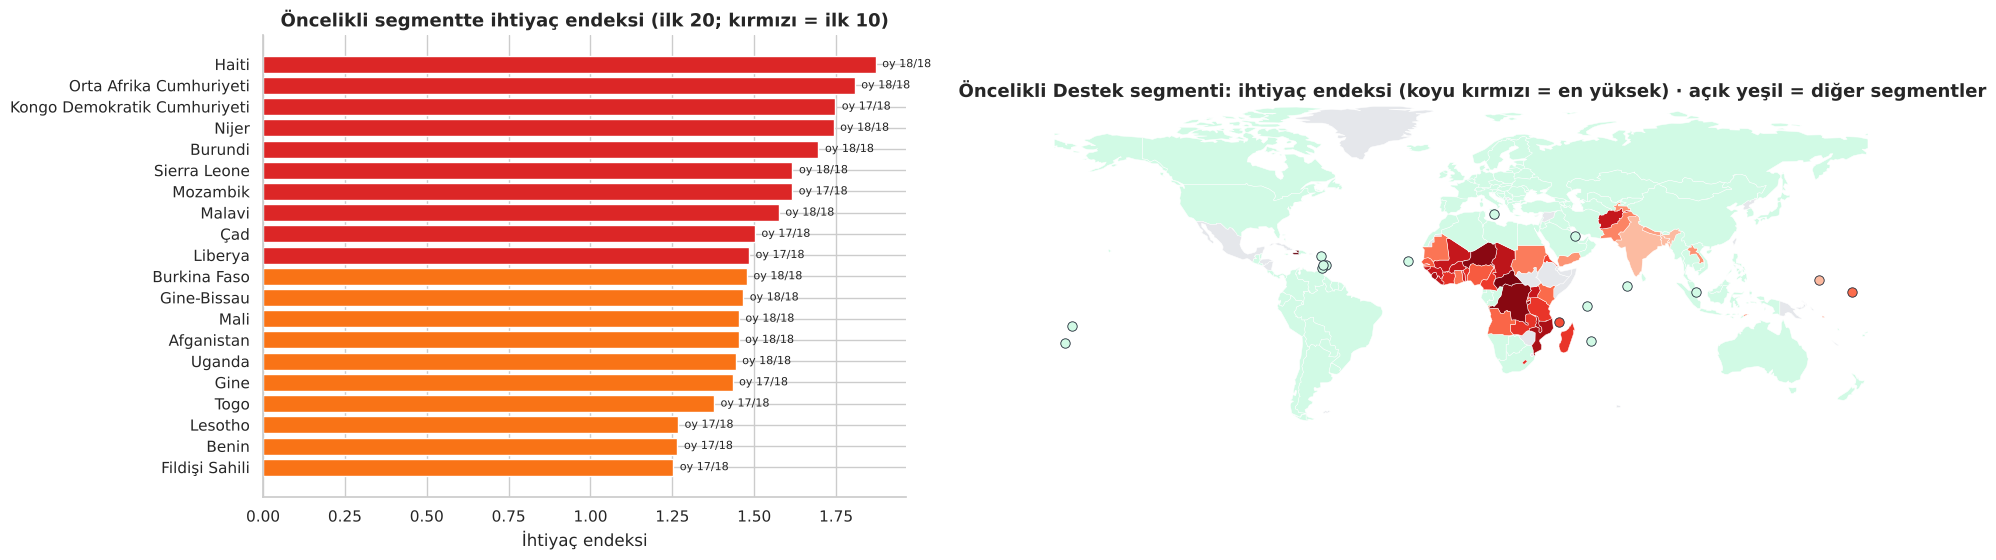

In [33]:
alternatif = {"Sağlık": {"Çocuk ölümü": 1, "Yaşam beklentisi": -1}, "Ekonomi": {"Gelir": -1, "Kişi başı GSYH": -1},
              "Çocuk ölümü ağırlıklı": {"Çocuk ölümü": 3, "Doğurganlık": 1, "Gelir": -1, "Kişi başı GSYH": -1, "Yaşam beklentisi": -1}}
ana10 = set(ilk10["Ülke"]); duyar = []
for ad_, w in alternatif.items():
    e = sum(Z_tum[s] * v for s, v in w.items()) / sum(abs(v) for v in w.values())
    alt10 = set(tum.loc[tum["Öncelikli mi?"]].assign(e=e[tum["Öncelikli mi?"]]).nlargest(10, "e")["Ülke"])
    duyar.append({"Alternatif endeks": ad_, "Ortak ülke (10'da)": len(ana10 & alt10), "Giren": ", ".join(sorted(alt10 - ana10)), "Çıkan": ", ".join(sorted(ana10 - alt10))})
duyar = pd.DataFrame(duyar).set_index("Alternatif endeks"); display(duyar); rapor_kaydet(duyar, "19_endeks_duyarlilik")
sabit = sorted(set.intersection(ana10, *[set(tum.loc[tum["Öncelikli mi?"]].assign(e=sum(Z_tum[s] * v for s, v in w.items())[tum["Öncelikli mi?"]]).nlargest(10, "e")["Ülke"]) for w in alternatif.values()]))
print("Dört endeksin hepsinde ilk 10'da olan 'çekirdek' ülkeler:", ", ".join(sabit))

fig, ax = plt.subplots(1, 2, figsize=(21, 6), gridspec_kw={"width_ratios": [1, 1.3]})
k20 = kisa.head(20).iloc[::-1]
ax[0].barh(k20["Ülke"], k20["İhtiyaç endeksi"], color=[RENK["kirmizi"] if u in ana10 else RENK["turuncu"] for u in k20["Ülke"]])
for y_, (e, o) in enumerate(zip(k20["İhtiyaç endeksi"], k20["Konsensüs oyu"])): ax[0].text(e + .02, y_, f"oy {o}/{len(uygunlar)}", va="center", fontsize=8)
ax[0].set(title="Öncelikli segmentte ihtiyaç endeksi (ilk 20; kırmızı = ilk 10)", xlabel="İhtiyaç endeksi")
renk = {u: to_hex(plt.cm.Reds(.25 + .75 * (e - kisa["İhtiyaç endeksi"].min()) / (kisa["İhtiyaç endeksi"].max() - kisa["İhtiyaç endeksi"].min())))
        for u, e in zip(kisa["Ülke (EN)"], kisa["İhtiyaç endeksi"])}
renk.update({u: "#D1FAE5" for u in tum.loc[~tum["Öncelikli mi?"], "Ülke (EN)"]})
dunya_haritasi(ax[1], renk, baslik="Öncelikli Destek segmenti: ihtiyaç endeksi (koyu kırmızı = en yüksek) · açık yeşil = diğer segmentler")
kaydet(fig, "18_oncelik_haritasi"); plt.show()

<table><tr><td>

<img src="assets/etiket_ybs.svg" height="34" alt="YBS Bağlantısı">

Bu bölüm bir **karar destek sisteminin (KDS)** kalbidir: model **öneri** üretir (segment, endeks, konsensüs oyu), kararı **insan** verir. Bir yardım kuruluşunun bilgi sisteminde bu çıktılar ülke kartına alan olarak yazılır; saha raporları, çatışma ve erişim bilgisi, diğer bağışçıların katkıları gibi **modelde olmayan** veriler aynı ekranda gösterilir. Endeks ağırlıkları **yönetişim** kararıdır: kim, hangi gerekçeyle belirledi? Bu yüzden duyarlılık tablosu raporun ayrılmaz parçasıdır.

</td></tr></table>

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

İlk 10 ülkenin **hepsi** BM EAGÜ listesinde ve **hepsi** uygun 18 algoritmanın en az 17'sinin "en kırılgan" segmentinde: **Haiti**, Orta Afrika Cumhuriyeti, Kongo Demokratik Cumhuriyeti, Nijer, Burundi, Sierra Leone, Mozambik, Malavi, Çad, Liberya. Yani liste **yönteme duyarlı değil**. Endeks ağırlıklarına duyarlılık ise orta düzeyde: alternatif endekslerle ilk 10'un **6–9'u** aynı kalıyor ve dört endeksin hepsinde ilk 10'da olan **çekirdek** ülkeler Malavi, Mozambik, Orta Afrika Cumhuriyeti ve Sierra Leone. Oy oranı %80'in altında kalan **Angola, Moritanya, Solomon Adaları, Laos, Yemen, Bangladeş ve Hindistan**, öncelikli segmentin **sınırında** duruyor; saha ekipleri bu ülkeler için ek bilgiye (çatışma, erişim, diğer bağışçılar) başvurmalı. Bütçe senaryosunda 10 milyon dolar, endeksle orantılı olarak ülke başına ≈ 0,89–1,12 milyon dolar arasında dağılıyor; bu bir **varsayımdır**, nüfus ve emme kapasitesi gibi bilgiler eklenmeden uygulanmamalıdır.

</td></tr></table>

<a id="p14"></a>

<p align="center">
  <img src="assets/proje_14.svg" width="100%" alt="Bölüm 14: Adalet ve hata">
</p>

### ⚖️ 14.1 · Segmentler Kıtanın Vekili mi?

Kıta kümelemede **kullanılmadı**. Ama segmentler kıtayla güçlü biçimde ilişkiliyse, model "bir kıtayı" damgalıyor gibi algılanabilir. İlişkiyi **Cramér V** ile ölçüyoruz ve her kıtadaki öncelikli ülke oranına bakıyoruz.

Segment,🆘 Öncelikli Destek,🌱 Gelişmekte Olan,🏙️ Gelişmiş
Kıta,,,
Afrika,33,12,2
Asya,9,30,6
Avrupa,0,6,33
Güney Amerika,0,12,0
Kuzey Amerika,1,7,7
Okyanusya,3,4,2


Cramér V (kıta × segment): 0.630


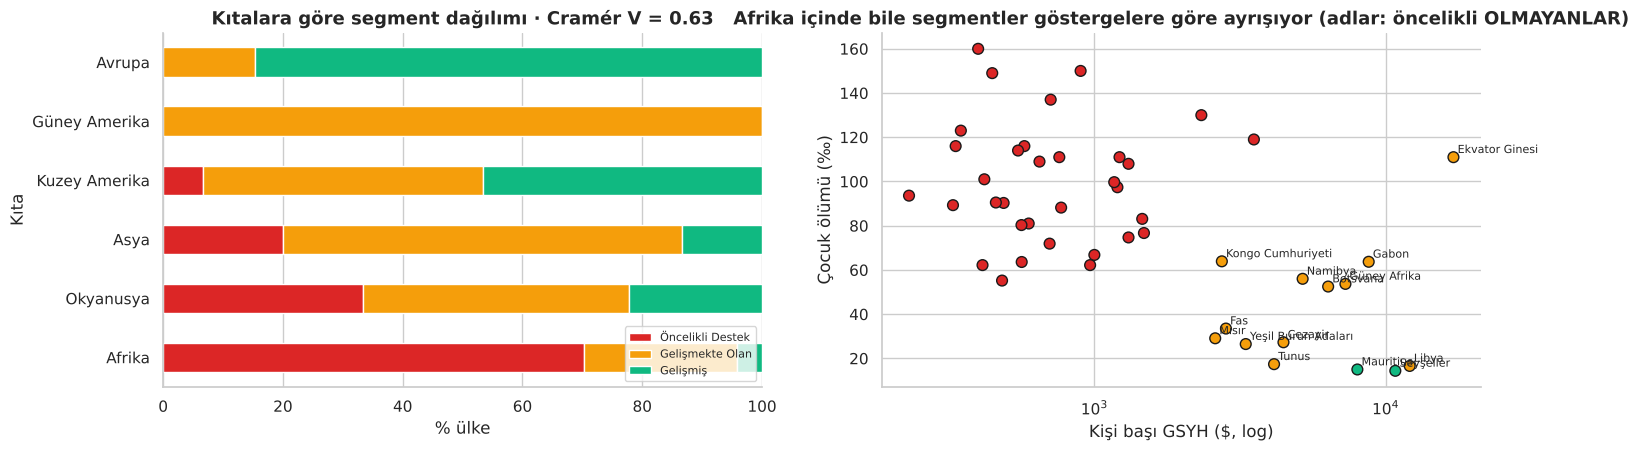

In [34]:
kita_tab = pd.crosstab(tum["Kıta"], tum["Segment"].map(SEGMENT_AD))[[SEGMENT_AD[s] for s in sira]]
cv = cramers_v(tum["Kıta"], tum["Segment"])
kita_oran = (tum.groupby("Kıta")["Öncelikli mi?"].mean() * 100).sort_values(ascending=False)
display(kita_tab); print(f"Cramér V (kıta × segment): {cv:.3f}")
fig, ax = plt.subplots(1, 2, figsize=(17, 4.6))
(kita_tab.div(kita_tab.sum(1), axis=0) * 100).loc[kita_oran.index].rename(columns={SEGMENT_AD[s]: SEG_KISA[s] for s in sira}).plot.barh(stacked=True, ax=ax[0], color=[SEG_RENK[s] for s in sira], edgecolor="white")
ax[0].set(title=f"Kıtalara göre segment dağılımı · Cramér V = {cv:.2f}", xlabel="% ülke"); ax[0].legend(fontsize=8, loc="lower right")
afr = tum[tum["Kıta"] == "Afrika"]
ax[1].scatter(afr["Kişi başı GSYH"], afr["Çocuk ölümü"], c=[SEG_RENK[s] for s in afr["Segment"]], s=60, edgecolor="k")
for _, r in afr[~afr["Öncelikli mi?"]].iterrows(): ax[1].annotate(r["Ülke"], (r["Kişi başı GSYH"], r["Çocuk ölümü"]), fontsize=8, xytext=(3, 3), textcoords="offset points")
ax[1].set(xscale="log", xlabel="Kişi başı GSYH ($, log)", ylabel="Çocuk ölümü (‰)", title="Afrika içinde bile segmentler göstergelere göre ayrışıyor (adlar: öncelikli OLMAYANLAR)")
kaydet(fig, "19_kita_adalet"); plt.show()
rapor_kaydet(kita_tab, "20_kita_segment")

<table><tr><td>

<img src="assets/etiket_etik.svg" height="34" alt="Etik not">

Segmentler kıtayla **güçlü** biçimde ilişkili (Cramér V **0,63**): Afrika'daki 47 ülkenin 33'ü öncelikli segmentte, Avrupa'da tek bir öncelikli ülke yok. Kıta modelde **hiç kullanılmadı**; ilişki, tarihsel ve ekonomik eşitsizliklerin göstergelere yansımasından doğuyor. Yine de iki risk var: (1) **Damgalama:** "Afrika = yardım" gibi bir algı, yatırım ve turizm kararlarını olumsuz etkileyebilir; bu yüzden segment adları ülke **halkını değil göstergelerin durumunu** anlatmalı. (2) **Ortalamaya hapsetme:** sağdaki grafik Afrika içinde bile ayrışmayı gösteriyor; Güney Afrika, Botsvana, Namibya, Mısır, Fas, Tunus gibi 14 Afrika ülkesi öncelikli segmentte değil. Model kıtayı değil **göstergeleri** okuyor; rapor da öyle okumalı.

</td></tr></table>

### 🧪 14.2 · Özellik Duyarlılığı: Bir Göstergeyi Çıkarınca Ne Olur?

Her seferinde **bir göstergeyi** çıkarıp final boru hattını yeniden kuruyoruz (eğitimde) ve tüm 167 ülkeyi atıyoruz. İki soruya bakıyoruz: segmentler ne kadar değişiyor (ARI) ve **kaç ülkenin öncelik durumu** değişiyor?

In [35]:
seg_tum = np.r_[seg_tr, seg_te]
def ozellik_cikar(s):
    kalan = [o for o in OZELLIKLER if o != s]
    log_k, slog_k = [o for o in LOG_SUTUNLARI if o in kalan], [o for o in ISARETLI_LOG_SUTUNLARI if o in kalan]
    on = Pipeline([("doldur", SimpleImputer(strategy="median")), ("donustur", ColumnTransformer(
        [("log", FunctionTransformer(log1p_donustur, feature_names_out="one-to-one"), log_k)] +
        ([("isaretli_log", FunctionTransformer(isaretli_log, feature_names_out="one-to-one"), slog_k)] if slog_k else []),
        remainder="passthrough", verbose_feature_names_out=False)), ("olcek", StandardScaler())]).set_output(transform="pandas")
    boru = Pipeline([("on", on), ("kume", AgacAtayici(clone(FINAL_KUMELEYICI)))]).fit(Xtr[kalan])
    et = np.r_[boru.named_steps["kume"].labels_, boru.predict(Xte[kalan])]
    onc = pd.Series(tr["Çocuk ölümü"].to_numpy()).groupby(et[:len(tr)]).median().idxmax()
    return {"Çıkarılan gösterge": s, "ARI (final ile)": adjusted_rand_score(seg_tum, et),
            "Öncelik durumu değişen ülke": int(((et == onc) != (seg_tum == ONCELIKLI)).sum()),
            "Değişenler": ", ".join(tum["Ülke"][(et == onc) != (seg_tum == ONCELIKLI)].tolist()[:6])}
duyarlilik = pd.DataFrame([ozellik_cikar(s) for s in OZELLIKLER]).set_index("Çıkarılan gösterge").sort_values("ARI (final ile)")
display(duyarlilik.round(3)); rapor_kaydet(duyarlilik.round(4), "21_ozellik_duyarliligi")

,ARI (final ile),Öncelik durumu değişen ülke,Değişenler
Çıkarılan gösterge,,,
Enflasyon,0.772,1,Hindistan
Sağlık harcaması,0.787,2,"Kongo Cumhuriyeti, Mikronezya"
Doğurganlık,0.873,5,"Güney Afrika, Özbekistan, Angola, Kamboçya, My..."
İhracat,0.893,6,"Kırgızistan, Namibya, Kongo Cumhuriyeti, Kambo..."
İthalat,0.907,2,"Kongo Cumhuriyeti, Kamboçya"
Çocuk ölümü,0.911,5,"Tonga, Moritanya, Angola, Hindistan, Laos"
Yaşam beklentisi,0.943,0,
Gelir,0.945,3,"Güney Afrika, Bangladeş, Hindistan"
Kişi başı GSYH,0.945,3,"Güney Afrika, Bangladeş, Hindistan"


<table><tr><td>

<img src="assets/etiket_teshis.svg" height="34" alt="Teşhis">

Hiçbir gösterge tek başına sonucu belirlemiyor: herhangi biri çıkarılınca segmentler final ile **ARI 0,77–0,95** düzeyinde uyumlu kalıyor ve öncelik durumu değişen ülke sayısı **en fazla 6** (167 ülke içinde). En çok etkiyi, kalkınma ekseninin **dışındaki** göstergeler yapıyor: **enflasyon** ve **sağlık harcaması** çıkarılınca segment sınırları en çok kayıyor (ARI 0,77–0,79), ama öncelik listesi neredeyse hiç değişmiyor (1–2 ülke). **Doğurganlık, ihracat ve çocuk ölümü** çıkarılınca 5–6 ülkenin öncelik durumu değişiyor; değişenler (Angola, Kamboçya, Hindistan, Laos, Moritanya…) 13. bölümde zaten **oy oranı düşük** çıkan sınır ülkeleri. Gelir ve kişi başı GSYH birbirinin yerini tuttuğu için (Spearman 0,98) ikisinden biri çıkarılınca sonuç çok az değişiyor.

</td></tr></table>

### 🧭 14.3 · Sınırdaki ve Sıra Dışı Ülkeler

**Sınırdaki ülke:** silüeti negatif (komşu segmente daha yakın) → karar verirken iki segmentin profiline de bakılmalı. **Sıra dışı ülke:** en yakın segment merkezine uzaklığı eğitimdeki uzaklıkların **%99'luk diliminin** üstünde → segment ataması **güvenilmez**, insan incelemesi gerekir.

In [36]:
uz_tr, uz_te = FINAL.transform(Xtr).min(1), FINAL.transform(Xte).min(1)
AYKIRI_ESIK = float(np.quantile(uz_tr, 0.99))
s_tum = np.r_[silhouette_samples(Ztr_f, seg_tr), silhouette_samples(Zte_f, seg_te)]
tum["Silüet"] = s_tum; tum["Merkeze uzaklık"] = np.r_[uz_tr, uz_te]
tum["Sınırda mı?"] = tum["Silüet"] < 0; tum["Sıra dışı mı?"] = tum["Merkeze uzaklık"] > AYKIRI_ESIK
sinir = tum[tum["Sınırda mı?"] | tum["Sıra dışı mı?"]].assign(Segment=lambda x: x["Segment"].map(SEGMENT_AD))
display(sinir[["Ülke", "Veri", "Segment", "Silüet", "Merkeze uzaklık", "Sınırda mı?", "Sıra dışı mı?", "Çocuk ölümü", "Enflasyon", "İhracat", "Kişi başı GSYH"]]
        .sort_values("Merkeze uzaklık", ascending=False).set_index("Ülke").round(2))
print(f"Sıra dışı eşiği (eğitim %99): {AYKIRI_ESIK:.2f} | sınırdaki: {int(tum['Sınırda mı?'].sum())} | sıra dışı: {int(tum['Sıra dışı mı?'].sum())}")
print("Sınırdaki ülkelerin segmentleri:", tum.loc[tum["Sınırda mı?"], "Segment"].map(SEGMENT_AD).value_counts().to_dict())
rapor_kaydet(sinir.round(3), "22_sinirdaki_siradisi")

,Veri,Segment,Silüet,Merkeze uzaklık,Sınırda mı?,Sıra dışı mı?,Çocuk ölümü,Enflasyon,İhracat,Kişi başı GSYH
Ülke,,,,,,,,,,
ABD,Eğitim,🏙️ Gelişmiş,0.19,4.59,False,True,7.3,1.22,12.4,48400
Singapur,Eğitim,🏙️ Gelişmiş,0.21,4.19,False,True,2.8,-0.05,200.0,46600
Panama,Eğitim,🏙️ Gelişmiş,-0.00,2.08,True,False,19.7,2.59,70.0,8080
Maldivler,Test,🌱 Gelişmekte Olan,-0.17,1.88,True,False,13.2,2.88,77.6,7100
Kuzey Makedonya,Eğitim,🏙️ Gelişmiş,-0.02,1.82,True,False,10.4,2.04,39.8,4540
Laos,Test,🆘 Öncelikli Destek,-0.04,1.74,True,False,78.9,9.20,35.4,1140


Sıra dışı eşiği (eğitim %99): 4.07 | sınırdaki: 4 | sıra dışı: 2
Sınırdaki ülkelerin segmentleri: {'🏙️ Gelişmiş': 2, '🆘 Öncelikli Destek': 1, '🌱 Gelişmekte Olan': 1}


<table><tr><td>

<img src="assets/etiket_teshis.svg" height="34" alt="Teşhis">

Yalnızca **4 sınırdaki** (silüeti negatif ya da sıfır) ve **2 sıra dışı** ülke var. Sıra dışı ikili öğretici: **ABD**, sağlık harcamasının GSYH'deki payı en yüksek (%17,9) ve dış ticareti düşük olduğu için zengin ülkelerin merkezinden uzak; **Singapur** ise ihracatı GSYH'nin **%200**'ü olan bir ticaret merkezi. İkisi de doğru segmentte ama "tipik" değiller; segment ortalamasıyla politika tasarlarken bu ülkelere ayrıca bakılmalı. Sınırdaki **Laos** (öncelikli segmentin kenarında) ve **Maldivler, Panama, Kuzey Makedonya** (Gelişmekte Olan–Gelişmiş sınırı), karar verilirken **iki segmentin profiline** birden bakılması gereken ülkeler. Laos'un 13. bölümde de düşük oy oranı alması tesadüf değil: farklı yöntemler aynı ülkelerde tereddüt ediyor.

</td></tr></table>

<a id="p15"></a>

<p align="center">
  <img src="assets/proje_15.svg" width="100%" alt="Bölüm 15: Model kaydı">
</p>

### 💾 15.1 · Modeli ve Meta Bilgiyi Kaydet

Final boru hattı (doldurma + log + işaretli log + ölçek + kümeleyici + merkez atayıcı) **tek bir `joblib` dosyasına** kaydedilir. Yanına segment adları, gösterge listesi, sıra dışı eşiği, başarı ölçütleri ve sürümler **`meta.json`** olarak yazılır.

In [37]:
MODEL_DIR = Path("outputs/model"); MODEL_DIR.mkdir(parents=True, exist_ok=True)
joblib.dump(FINAL, MODEL_DIR / "ulke_segment_model.joblib")
meta = {"proje": "Gün 56 — Ülke segmentasyonu (hiyerarşik kümeleme ve 27 algoritma)", "model": FINAL_AD, "k": K,
        "ozellikler": OZELLIKLER, "log_sutunlari": LOG_SUTUNLARI, "isaretli_log_sutunlari": ISARETLI_LOG_SUTUNLARI,
        "segment_adlari": {str(int(k)): v for k, v in SEGMENT_AD.items()}, "oncelikli_segment": int(ONCELIKLI), "aykiri_esik": AYKIRI_ESIK,
        "basari": {"egitim_siluet": round(float(sil_tr), 4), "test_siluet": round(float(sil_te), 4),
                   "test_yeniden_kesif_ari": round(float(test_ozet.loc["Yeniden keşif ARI ↑", "Test"]), 4),
                   "vekil_agac_test_sadakati": round(float(sadakat_te), 4)},
        "atama_kurali": "en yakın segment merkezi (AgacAtayici)", "veri": "Kaggle — Unsupervised Learning on Country Data (167 ülke)",
        "surumler": {"python": sys.version.split()[0], "scikit-learn": sklearn.__version__, "pandas": pd.__version__, "numpy": np.__version__, "scipy": scipy.__version__}}
(MODEL_DIR / "meta.json").write_text(json.dumps(meta, ensure_ascii=False, indent=2), encoding="utf-8")
# Ayrı süreç testi için: Kaggle sütun adlarıyla 6 HAM test ülkesi
ters = {v: k for k, v in SUTUN_TR.items()}
ornek = ham[ham["Ülke"].isin(te["Ülke"].head(6))].rename(columns=ters).rename(columns={"Ülke (EN)": "country"})[["country"] + list(SUTUN_TR)]
ornek.to_csv(MODEL_DIR / "ornek_ulkeler.csv", index=False, encoding="utf-8-sig")
print({p.name: f"{p.stat().st_size / 1024:.1f} KB" for p in MODEL_DIR.iterdir()})

{'ornek_ulkeler.csv': '0.4 KB', 'meta.json': '1.2 KB', 'ulke_segment_model.joblib': '145.5 KB'}


### 🧰 15.2 · Ayrı Süreçte Yükleme Testi

Kaydedilen model, bu notebook'un belleğinden **bağımsız** yeni bir Python sürecinde yüklenip **ham ülke kaydıyla** (Kaggle sütun adları) çalıştırılıyor. `ihtiyac_ata()` fonksiyonu, karar defterindeki ticaret kuralını (%1'in altı → eksik) kendisi uygular; böylece işletmede de aynı temizlik yapılır.

In [38]:
betik = """
import pandas as pd
from ulke_yardimci import ihtiyac_ata
ham = pd.read_csv('outputs/model/ornek_ulkeler.csv', encoding='utf-8-sig')
sonuc = ihtiyac_ata(ham)
print(sonuc.to_string(index=False))
yeni = {'country': 'Hayali Ülke', 'child_mort': 95.0, 'exports': 20.0, 'health': 5.0, 'imports': 40.0, 'income': 1500,
        'inflation': 12.0, 'life_expec': 58.0, 'total_fer': 5.5, 'gdpp': 700}
print('Tek kayıt:', ihtiyac_ata(yeni).iloc[0].to_dict())
print('SEGMENTLER', ','.join(map(str, sonuc['Segment'])))
"""
sonuc = subprocess.run([sys.executable, "-c", betik], capture_output=True, text=True, cwd=".")
print(sonuc.stdout or sonuc.stderr)
# Aynı ülkelerin bu notebook'taki tahminiyle karşılaştır
ayri = [int(x) for x in [l for l in sonuc.stdout.splitlines() if l.startswith("SEGMENTLER")][0].split()[1].split(",")] if sonuc.returncode == 0 else []
ayni = list(FINAL.predict(ticaret_kontrol(ornek.rename(columns=SUTUN_TR))[OZELLIKLER])) == ayri
print("Notebook ile ayrı süreç aynı segmentleri mi verdi?", bool(ayni))

               Ülke  Segment       Segment adı  Merkeze uzaklık  Sıra dışı?
Antigua and Barbuda        1       🏙️ Gelişmiş            1.519       False
           Barbados        1       🏙️ Gelişmiş            1.205       False
            Bolivia        0 🌱 Gelişmekte Olan            1.374       False
        El Salvador        0 🌱 Gelişmekte Olan            1.416       False
            Hungary        1       🏙️ Gelişmiş            1.679       False
            Morocco        0 🌱 Gelişmekte Olan            1.739       False
Tek kayıt: {'Ülke': 'Hayali Ülke', 'Segment': 2, 'Segment adı': '🆘 Öncelikli Destek', 'Merkeze uzaklık': 0.743, 'Sıra dışı?': False}
SEGMENTLER 1,1,0,0,1,0

Notebook ile ayrı süreç aynı segmentleri mi verdi? True


<table><tr><td>

<img src="assets/etiket_etik.svg" height="34" alt="Etik not">

Bu model **yalnızca bu veri setindeki 9 göstergenin ölçüldüğü dönem** için kuruldu. Göstergeler yıllar içinde değişir (salgın, savaş, kriz); segmentler **her yıl yeniden** hesaplanmalı ve **izleme** kurulmalıdır: yeni ülkelerin sıra dışı oranı, segment payları ve EAGÜ örtüşmesi. Model bir ülkeyi "yardıma muhtaç" diye **damgalamak** için değil, sınırlı kaynağı **önceliklendirmeye yardım** için kullanılmalı; raporlarda segment adları **saygılı ve nötr** dilde tutulmalıdır.

</td></tr></table>

<a id="p16"></a>

<p align="center">
  <img src="assets/proje_16.svg" width="100%" alt="Bölüm 16: Proje özeti">
</p>

### 📋 16.1 · Proje Özeti (hücre çıktılarından üretilir)

In [39]:
d_e = dogruluk.loc["Tümü"]
ozet = pd.DataFrame([
    ("Veri", f"{len(d)} ülke, 9 gösterge; eğitim {len(tr)} / test {len(te)} (GSYH çeyreğine göre tabakalı)"),
    ("Veri kalitesi", "Myanmar'ın ihracat/ithalatı (%0,1) hatalı sayıldı → boru hattında eğitim medyanı; uç değerler gerçek olgu olarak korundu"),
    ("Ön işleme", "Doldur → log1p (6) + işaretli log (enflasyon) → standart ölçek, tek Pipeline"),
    ("Segment sayısı (kural 1)", f"K = {K} (silüet k = {k_tablo['Silüet ↑'].idxmax()}, kesim aralığı k = {k_tablo['Kesim aralığı ↑'].idxmax()})"),
    ("Yarış (kural 2)", f"{len(YARISCI) - 1} algoritma + taban; uygun {int(yaris['Uygun'].sum())}; lider {yaris.index[0]}; en yüksek silüet {yaris['Silüet'].idxmax()} ({'uygun' if yaris.loc[yaris['Silüet'].idxmax(), 'Uygun'] else 'uygun değil'})"),
    ("Final (kural 3)", FINAL_AD),
    ("Eğitim / test silüeti", f"{sil_tr:.3f} / {sil_te:.3f}"),
    ("Test yeniden keşif ARI · vekil ağaç test sadakati", f"{test_ozet.loc['Yeniden keşif ARI ↑', 'Test']:.3f} · %{sadakat_te * 100:.1f}"),
    ("Segmentler", " · ".join(f"{SEGMENT_AD[s]} ({int((seg_tum == s).sum())})" for s in sira)),
    ("EAGÜ dış doğrulama (tümü)", f"kesinlik %{d_e['Kesinlik %']:.1f} · duyarlılık %{d_e['Duyarlılık %']:.1f}"),
    ("Kısa liste ilk 5", ", ".join(ilk10["Ülke"].head(5))),
    ("Adalet", f"kıta × segment Cramér V = {cv:.2f}; sınırdaki {int(tum['Sınırda mı?'].sum())}, sıra dışı {int(tum['Sıra dışı mı?'].sum())} ülke"),
], columns=["Başlık", "Sonuç"]).set_index("Başlık")
display(ozet); rapor_kaydet(ozet, "99_proje_ozeti")

,Sonuç
Başlık,
Veri,"167 ülke, 9 gösterge; eğitim 133 / test 34 (GS..."
Veri kalitesi,"Myanmar'ın ihracat/ithalatı (%0,1) hatalı sayı..."
Ön işleme,Doldur → log1p (6) + işaretli log (enflasyon) ...
Segment sayısı (kural 1),"K = 3 (silüet k = 2, kesim aralığı k = 2)"
Yarış (kural 2),27 algoritma + taban; uygun 18; lider K-Means;...
Final (kural 3),"Konsensüs hiyerarşik (taban=kmeans, son=averag..."
Eğitim / test silüeti,0.262 / 0.265
Test yeniden keşif ARI · vekil ağaç test sadakati,0.822 · %76.5
Segmentler,🆘 Öncelikli Destek (46) · 🌱 Gelişmekte Olan (7...


<table><tr><td>

<img src="assets/etiket_yonetici.svg" height="34" alt="Yönetici Özeti">

Bu tablo **bu çalıştırmanın gerçek sayılarıdır**. Yönetici için beş cümle: (1) 167 ülke, dokuz sağlık ve ekonomi göstergesine göre **üç anlamlı aileye** ayrılıyor: öncelikli destek (46 ülke), gelişmekte olan (71) ve gelişmiş (50). (2) Aileler **görülmemiş 34 ülkede** de aynı biçimde ortaya çıkıyor (test silüeti eğitime eşit, yeniden keşif ARI 0,82). (3) Modelden **bağımsız** BM En Az Gelişmiş Ülkeler listesiyle örtüşme yüksek: öncelikli ailenin %80'i EAGÜ, EAGÜ'lerin %90'ı öncelikli ailede. (4) Kısa listenin ilk 10'u (Haiti, Orta Afrika Cumhuriyeti, Kongo DC, Nijer, Burundi, Sierra Leone, Mozambik, Malavi, Çad, Liberya) **27 algoritmanın neredeyse tamamında** öncelikli; liste yönteme değil, en fazla **endeks ağırlıklarına** biraz duyarlı. (5) Öneri: ilk 10 ile saha değerlendirmesine başlanmalı, **sınırdaki** ülkeler (Angola, Laos, Yemen, Moritanya…) ek bilgiyle ele alınmalı ve segmentler **her yıl** yeni verilerle yeniden hesaplanmalı.

</td></tr></table>

<p align="center">
  <img src="assets/kapanis_proje.svg" width="100%" alt="Kapanış">
</p>

### 🧠 Akılda Kalacaklar

<table>
<tr><td width="33%" valign="top" align="center"><h3>🧼</h3><b>Tek hatalı satır</b><br><sub><i>Myanmar'ın ticareti</i></sub><br><br>167 satırlık veride bir hata <b>bütün ağacı</b> bükebilir; önce veriye bak<br><br></td><td width="33%" valign="top" align="center"><h3>🔒</h3><b>Etiketsizken de test</b><br><sub><i>kilitli 34 ülke</i></sub><br><br>Segmentlerin tesadüf olmadığını ancak <b>görülmemiş ülke</b> gösterir<br><br></td><td width="33%" valign="top" align="center"><h3>🪤</h3><b>Silüet tuzağı</b><br><sub><i>boylara bak</i></sub><br><br>En yüksek silüet, çoğu zaman <b>tek dev küme + yalnız ülkeler</b> demektir<br><br></td></tr>
<tr><td valign="top" align="center"><h3>🌳</h3><b>Ağaç = açıklama</b><br><sub><i>dendrogram + vekil ağaç</i></sub><br><br>Hiyerarşi, yönetim kuruluna "kim kime benziyor" sorusunu <b>tek resimde</b> cevaplar<br><br></td><td valign="top" align="center"><h3>🔁</h3><b>Kararlılık ölçülür</b><br><sub><i>bootstrap · konsensüs</i></sub><br><br>Deterministik olmak kararlı olmak değildir; <b>yeniden örnekle</b><br><br></td><td valign="top" align="center"><h3>🇺🇳</h3><b>Bağımsız kanıt</b><br><sub><i>EAGÜ listesi</i></sub><br><br>Kümelemede kullanılmayan bir dış ölçüt, segmentlerin <b>anlamını</b> sınar<br><br></td></tr>
<tr><td valign="top" align="center"><h3>🗳️</h3><b>Konsensüs oyu</b><br><sub><i>yöntemden bağımsız öncelik</i></sub><br><br>Bütün algoritmaların öncelikli dediği ülke, <b>en güvenilir</b> önceliktir<br><br></td><td valign="top" align="center"><h3>⚖️</h3><b>Kıta değil gösterge</b><br><sub><i>Cramér V</i></sub><br><br>Segmentler kıtayla ilişkili ama <b>kıtanın kendisi</b> kullanılmadı; dili nötr tut<br><br></td><td valign="top" align="center"><h3>🧑‍⚖️</h3><b>Model önerir, insan karar verir</b><br><sub><i>KDS</i></sub><br><br>Endeks ağırlıkları bir <b>yönetişim</b> kararıdır; duyarlılığı raporla<br><br></td></tr>
</table>

### 📚 KAYNAKÇA

Metin içi atıflar APA 7 biçimindedir. **Dolaylı atıf**, kaynağa ikinci elden ulaşıldığında "(B, A'dan aktarma)" kalıbıyla gösterilir. Bu notebook'taki örnekler:

- Ward bağlantısı, birleşmede **grup içi kareler toplamındaki artışı** en küçük yapan ölçüte dayanır (Ward, 1963; Murtagh ve Legendre, 2014'ten aktarma); scikit-learn ve SciPy'nin uyguladığı biçim, Lance–Williams güncelleme formülüyle yazılan "Ward2" ölçütüdür (Lance ve Williams, 1967; Murtagh ve Legendre, 2014'ten aktarma).
- Ortalama bağlantı (UPGMA) Sokal ve Michener'e (1958), tek bağlantı Sneath'e (1957) dayanır (Sokal ve Michener, 1958; Sneath, 1957; Murtagh ve Contreras, 2012'den aktarma).
- Hiyerarşik kümeleme şemalarının ultrametrik yapısı Johnson (1967) tarafından biçimlendirilmiştir (Johnson, 1967; Ran ve ark., 2023'ten aktarma).
- DIANA ve AGNES: Kaufman ve Rousseeuw (1990). BIRCH: Zhang ve ark. (1996). HDBSCAN: Campello ve ark. (2013). Konsensüs kümelemesi: Monti ve ark. (2003). Kofenetik korelasyon: Sokal ve Rohlf (1962). Silüet: Rousseeuw (1987). ARI: Hubert ve Arabie (1985). Küme bazında bootstrap kararlılığı: Hennig (2007).
- Hiyerarşik kümeleme yöntemlerinin güncel ve kapsamlı bir derlemesi için Ran ve ark. (2023); verimli algoritmalar için Müllner (2011).

**Kaynak listesi**

- Campello, R. J. G. B., Moulavi, D., & Sander, J. (2013). Density-based clustering based on hierarchical density estimates. In J. Pei, V. S. Tseng, L. Cao, H. Motoda, & G. Xu (Eds.), *Advances in knowledge discovery and data mining* (pp. 160–172). Springer. https://doi.org/10.1007/978-3-642-37456-2_14
- Hennig, C. (2007). Cluster-wise assessment of cluster stability. *Computational Statistics & Data Analysis, 52*(1), 258–271. https://doi.org/10.1016/j.csda.2006.11.025
- Hubert, L., & Arabie, P. (1985). Comparing partitions. *Journal of Classification, 2*(1), 193–218. https://doi.org/10.1007/BF01908075
- Johnson, S. C. (1967). Hierarchical clustering schemes. *Psychometrika, 32*(3), 241–254. https://doi.org/10.1007/BF02289588
- Kaufman, L., & Rousseeuw, P. J. (1990). *Finding groups in data: An introduction to cluster analysis*. Wiley. https://doi.org/10.1002/9780470316801
- Kokkula, R. (2020). *Unsupervised learning on country data* [Data set]. Kaggle. https://www.kaggle.com/datasets/rohan0301/unsupervised-learning-on-country-data
- Lance, G. N., & Williams, W. T. (1967). A general theory of classificatory sorting strategies: 1. Hierarchical systems. *The Computer Journal, 9*(4), 373–380. https://doi.org/10.1093/comjnl/9.4.373
- Monti, S., Tamayo, P., Mesirov, J., & Golub, T. (2003). Consensus clustering: A resampling-based method for class discovery and visualization of gene expression microarray data. *Machine Learning, 52*(1–2), 91–118. https://doi.org/10.1023/A:1023949509487
- Müllner, D. (2011). *Modern hierarchical, agglomerative clustering algorithms* (arXiv:1109.2378). arXiv. https://doi.org/10.48550/arXiv.1109.2378
- Murtagh, F., & Contreras, P. (2012). Algorithms for hierarchical clustering: An overview. *WIREs Data Mining and Knowledge Discovery, 2*(1), 86–97. https://doi.org/10.1002/widm.53
- Murtagh, F., & Legendre, P. (2014). Ward's hierarchical agglomerative clustering method: Which algorithms implement Ward's criterion? *Journal of Classification, 31*(3), 274–295. https://doi.org/10.1007/s00357-014-9161-z
- Natural Earth. (t.y.). *Admin 0 – Countries, 1:110m* [Data set]. https://www.naturalearthdata.com/
- Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.
- Ran, X., Xi, Y., Lu, Y., Wang, X., & Lu, Z. (2023). Comprehensive survey on hierarchical clustering algorithms and the recent developments. *Artificial Intelligence Review, 56*(8), 8219–8264. https://doi.org/10.1007/s10462-022-10366-3
- Rousseeuw, P. J. (1987). Silhouettes: A graphical aid to the interpretation and validation of cluster analysis. *Journal of Computational and Applied Mathematics, 20*, 53–65. https://doi.org/10.1016/0377-0427(87)90125-7
- Sneath, P. H. A. (1957). The application of computers to taxonomy. *Journal of General Microbiology, 17*(1), 201–226. https://doi.org/10.1099/00221287-17-1-201
- Sokal, R. R., & Michener, C. D. (1958). A statistical method for evaluating systematic relationships. *University of Kansas Science Bulletin, 38*, 1409–1438.
- Sokal, R. R., & Rohlf, F. J. (1962). The comparison of dendrograms by objective methods. *Taxon, 11*(2), 33–40. https://doi.org/10.2307/1217208
- United Nations Committee for Development Policy. (2018). *List of least developed countries (as of December 2018)*. United Nations. https://www.un.org/development/desa/dpad/least-developed-country-category.html
- Virtanen, P., Gommers, R., Oliphant, T. E., Haberland, M., Reddy, T., Cournapeau, D., Burovski, E., Peterson, P., Weckesser, W., Bright, J., van der Walt, S. J., Brett, M., Wilson, J., Millman, K. J., Mayorov, N., Nelson, A. R. J., Jones, E., Kern, R., Larson, E., … SciPy 1.0 Contributors. (2020). SciPy 1.0: Fundamental algorithms for scientific computing in Python. *Nature Methods, 17*(3), 261–272. https://doi.org/10.1038/s41592-019-0686-2
- Ward, J. H., Jr. (1963). Hierarchical grouping to optimize an objective function. *Journal of the American Statistical Association, 58*(301), 236–244. https://doi.org/10.1080/01621459.1963.10500845
- Zhang, T., Ramakrishnan, R., & Livny, M. (1996). BIRCH: An efficient data clustering method for very large databases. *ACM SIGMOD Record, 25*(2), 103–114. https://doi.org/10.1145/235968.233324